In [1]:
import numpy as npimport pandas as pdimport matplotlib.pyplot as pltimport xarray as xrfrom os import walkimport picklefrom pathlib import Path# Set project rootproject_root = Path().resolve().parents[0]import geopandas as gpdfrom geopandas import GeoDataFramefrom shapely.geometry import Point

In [2]:
def find_nearest(value,vector):
    vector = np.float64(vector)-np.float64(value);
    return np.argmin(np.abs(vector))

In [3]:
#restrepo_features_path = project_root / "data" / "raw" / "features" / "FeaturesPhrampusLee_TOCSedRate_updated"#restrepo_features_path = Path().resolve().parents[3] / "work_old/Data/Features_PhrampusLee_noNaN_highres_rot/"restrepo_features_path = project_root / "data" / "raw" / "features" / "FeaturesPhrampusLee_TOCSedRate_updated"restrepo_files = []for (dirpath, dirnames, filenames) in walk(restrepo_features_path):    #print(filenames)    restrepo_files.extend(filenames)restrepo_files.sort()len(restrepo_files)

510

In [4]:
feature_selection = pd.read_csv(project_root / "data" / "interim" / "selectedFeatureLists" / "selectedfeatures_v_men.txt").values#feature_selection = pd.read_csv(Path("restrepoHighResFeaturesRaw-50.txt")).valuesselection_filter = np.zeros(len(restrepo_files), dtype=bool)for idx, feature_name in enumerate(restrepo_files):    if feature_name in feature_selection: # drop '.nc' from feature names #drop .grd        selection_filter[idx] = True

In [5]:
feature_selection.shape

(110, 1)

In [6]:
filenames

[]

In [7]:
selected_files = []
for file in restrepo_files:
    #if file in feature_selection:
        selected_files.append(file)

In [8]:
len(feature_selection)

110

In [9]:
restrepo_files = selected_files

In [10]:



restrepo_files

['2N2_load_eot20_modified.nc',
 '2N2_ocean_eot20_modified.nc',
 'CM_MANTLE_DEN_KGM3_CRUST1s.5m.grd',
 'CM_MANTLE_DEN_KGM3_CRUST1s.r50km.aad.5m.grd',
 'CM_MANTLE_DEN_KGM3_CRUST1s.r50km.alg.5m.grd',
 'CM_MANTLE_DEN_KGM3_CRUST1s.r50km.men.5m.grd',
 'CM_MANTLE_DEN_KGM3_CRUST1s.r50km.mlg.5m.grd',
 'CM_MANTLE_VP_MS_CRUST1s.5m.grd',
 'CM_MANTLE_VP_MS_CRUST1s.r50km.aad.5m.grd',
 'CM_MANTLE_VP_MS_CRUST1s.r50km.alg.5m.grd',
 'CM_MANTLE_VP_MS_CRUST1s.r50km.men.5m.grd',
 'CM_MANTLE_VP_MS_CRUST1s.r50km.mlg.5m.grd',
 'CM_MANTLE_VS_MS_CRUST1s.5m.grd',
 'CM_MANTLE_VS_MS_CRUST1s.r50km.aad.5m.grd',
 'CM_MANTLE_VS_MS_CRUST1s.r50km.alg.5m.grd',
 'CM_MANTLE_VS_MS_CRUST1s.r50km.men.5m.grd',
 'CM_MANTLE_VS_MS_CRUST1s.r50km.mlg.5m.grd',
 'ChlorSummerMean.nc',
 'ChlorSummerMean_modified.nc',
 'ChlorSummerMean_modified_r50km.nc',
 'ChlorWinterMean.nc',
 'ChlorWinterMean_modified.nc',
 'ChlorWinterMean_modified_r50km.nc',
 'DERIVATIVE_GL_ELEVATION_M_ASL_ETOPO2v2.5.nc',
 'DERIVATIVE_GL_ELEVATION_M_ASL_ETOPO2v2.r1

In [11]:
#"""
file_idx = -1
corrupted_files = 0

for file in restrepo_files[0:len(restrepo_files)]:
    file_idx += 1
    
    try:
        rootgrp = xr.open_dataset(Path(restrepo_features_path / file), format = 'NETCDF4')
        
        if file == "SF_POROSITY_FRC.5m_with_coords_flip.nc":
            porosity_fileidx = file_idx
            print("porosity_fileidx_lee")
            print(porosity_fileidx)
            dataset_numpy_porosity = rootgrp.variables['data']

        elif file == "POROSITY_global_prediction.grd":
            porosity_fileidx_martin = file_idx
            print("porosity_fileidx_martin") 
            print(porosity_fileidx_martin)
            dataset_numpy_porosity_martin = rootgrp.variables['data']

            
        elif file == "SEAFLOOR_DENSITY_GCM3.nc":
            density_fileidx = file_idx
            print("density_fileidx")
            print(density_fileidx)
            dataset_numpy_density = rootgrp.variables['data']
            

    except:
        #restrepo_X_mean = np.append(restrepo_X_mean,np.nan)
        #restrepo_X_std = np.append(restrepo_X_std,np.nan)
        corrupted_files += 1
        continue
#"""

/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)
/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'gmt' loading failed:
Error loading GMT shared library at 'libgmt.so'.
libgmt.so: cannot open shared object file: No such file or directory
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


porosity_fileidx_martin
142
density_fileidx
221
porosity_fileidx_lee
253


In [12]:
"""
import matplotlib.pyplot as plt
import os

output_dir = Path().resolve().parents[3] / "work_old/Data/Features_Images"
os.makedirs(output_dir, exist_ok=True)

file_idx = -1
corrupted_files = 0

for file in restrepo_files[0:len(restrepo_files)]:
    file_idx += 1
    
    try:
        rootgrp = xr.open_dataset(Path(restrepo_features_path / file), format = 'NETCDF4')
        print(f"\nFile: {file}")
        
        # Plot the data
        plt.figure(figsize=(10,8))
        plt.imshow(rootgrp.variables['data'], 
                  extent=[rootgrp.lon.values[0], rootgrp.lon.values[-1],
                         rootgrp._LOG_MG_M3_lat.values[0], rootgrp.lat.values[-1]],
                  aspect='auto')
        plt.colorbar(label='Value')
        plt.title(file)
        plt.xlabel('Longitude')
        plt.ylabel('Latitude')
        
        # Save plot
        output_file = output_dir / f"{file.split('.')[0]}.png"
        plt.savefig(output_file)
        plt.close()

    except:
        restrepo_X_mean = np.append(restrepo_X_mean,np.nan)
        restrepo_X_std = np.append(restrepo_X_std,np.nan)
        corrupted_files += 1
        continue
"""

'\nimport matplotlib.pyplot as plt\nimport os\n\noutput_dir = Path(\'/gxfs_work/cau/sunms498/work_old/Data/Features_Images\')\nos.makedirs(output_dir, exist_ok=True)\n\nfile_idx = -1\ncorrupted_files = 0\n\nfor file in restrepo_files[0:len(restrepo_files)]:\n    file_idx += 1\n    \n    try:\n        rootgrp = xr.open_dataset(Path(restrepo_features_path / file), format = \'NETCDF4\')\n        print(f"\nFile: {file}")\n        \n        # Plot the data\n        plt.figure(figsize=(10,8))\n        plt.imshow(rootgrp.variables[\'data\'], \n                  extent=[rootgrp.lon.values[0], rootgrp.lon.values[-1],\n                         rootgrp._LOG_MG_M3_lat.values[0], rootgrp.lat.values[-1]],\n                  aspect=\'auto\')\n        plt.colorbar(label=\'Value\')\n        plt.title(file)\n        plt.xlabel(\'Longitude\')\n        plt.ylabel(\'Latitude\')\n        \n        # Save plot\n        output_file = output_dir / f"{file.split(\'.\')[0]}.png"\n        plt.savefig(output_file)

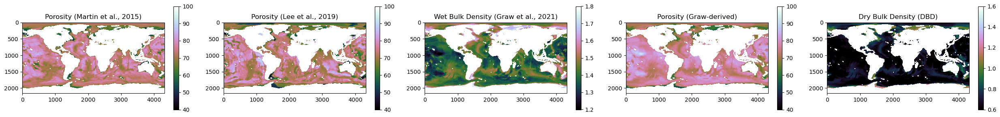

In [13]:

land_file = "../../data/raw/island_map.npy"
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1

# Calculate porosity from bulk density using Graw et al. (2021) equation
dS = 2.65  # density of dry sediments (g/cm3)
dPW = 1.024  # density of porewater (g/cm3)
dataset_numpy_porosity_graw = (dS - dataset_numpy_density) / (dS - dPW)

dataset_numpy_porosity_graw = dataset_numpy_porosity_graw*100.0

# Calculate dry bulk density (DBD)
DBD = (1 - dataset_numpy_porosity_graw/100.0) * dS

# Create masked arrays and rotate/flip
porosity_martin = np.rot90(np.rot90(np.fliplr(dataset_numpy_porosity_martin)))
porosity_lee = np.rot90(np.rot90(np.fliplr(dataset_numpy_porosity)))
density = np.rot90(np.rot90(np.fliplr(dataset_numpy_density)))
porosity_graw = np.rot90(np.rot90(np.fliplr(dataset_numpy_porosity_graw)))
DBD = np.rot90(np.rot90(np.fliplr(DBD)))
#land_map_rotated = np.rot90(np.rot90(np.fliplr(land_map)))

porosity_martin_masked = np.ma.masked_array(porosity_martin, mask=land_map)
porosity_lee_masked = np.ma.masked_array(porosity_lee, mask=land_map)
density_masked = np.ma.masked_array(density, mask=land_map)
porosity_graw_masked = np.ma.masked_array(porosity_graw, mask=land_map)
DBD_masked = np.ma.masked_array(DBD, mask=land_map)

fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(1, 5, figsize=(25, 3))

im1 = ax1.imshow(porosity_martin_masked, vmin=40, vmax=100, cmap='cubehelix')
fig.colorbar(im1, ax=ax1)
ax1.set_title("Porosity (Martin et al., 2015)")

im2 = ax2.imshow(porosity_lee_masked, vmin=40, vmax=100, cmap='cubehelix')
fig.colorbar(im2, ax=ax2)
ax2.set_title("Porosity (Lee et al., 2019)")



# Plot wet density (original), porosity, and dry bulk density
im3 = ax3.imshow(density_masked, vmin=1.2, vmax=1.8, cmap='cubehelix')
fig.colorbar(im3, ax=ax3)
ax3.set_title("Wet Bulk Density (Graw et al., 2021)")

# Add a fourth subplot for porosity
#ax4 = fig.add_subplot(1, 4, 4)
im4 = ax4.imshow(porosity_graw_masked, vmin=40, vmax=100, cmap='cubehelix')
fig.colorbar(im4, ax=ax4)
ax4.set_title("Porosity (Graw-derived)")

# Add a fifth subplot for DBD
#ax5 = fig.add_subplot(1, 5, 5)
im5 = ax5.imshow(DBD_masked, vmin=0.6, vmax=1.6, cmap='cubehelix')
fig.colorbar(im5, ax=ax5)
ax5.set_title("Dry Bulk Density (DBD)")

plt.tight_layout()


df_1: 7 points in low porosity (<55) areas (Graw-derived)
df_1: 121 points in low porosity (<55) areas (Lee et al., 2019)
df_1: 224 points in low porosity (<55) areas (Martin et al., 2015)
df_2: 15 points in low porosity (<55) areas (Graw-derived)
df_2: 695 points in low porosity (<55) areas (Lee et al., 2019)
df_2: 670 points in low porosity (<55) areas (Martin et al., 2015)


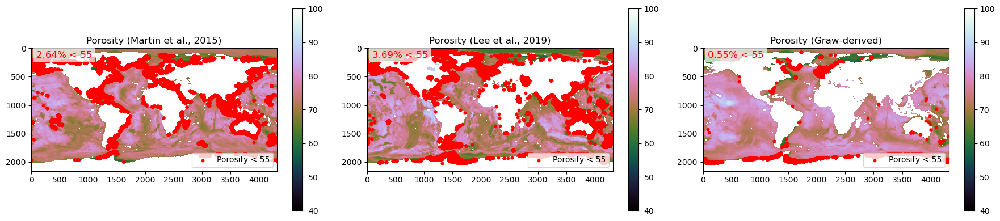

In [14]:

# Load land mask
land_file = "../../data/raw/island_map.npy"
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1

# Calculate porosity from bulk density using Graw et al. (2021) equation
dS = 2.65  # density of dry sediments (g/cm3)
dPW = 1.024  # density of porewater (g/cm3)
dataset_numpy_porosity_graw = (dS - dataset_numpy_density) / (dS - dPW)
dataset_numpy_porosity_graw = dataset_numpy_porosity_graw * 100.0

# Prepare porosity maps (rotate/flip and mask)
porosity_martin = np.rot90(np.rot90(np.fliplr(dataset_numpy_porosity_martin)))
porosity_lee = np.rot90(np.rot90(np.fliplr(dataset_numpy_porosity)))
porosity_graw = np.rot90(np.rot90(np.fliplr(dataset_numpy_porosity_graw)))

porosity_martin_masked = np.ma.masked_array(porosity_martin, mask=land_map)
porosity_lee_masked = np.ma.masked_array(porosity_lee, mask=land_map)
porosity_graw_masked = np.ma.masked_array(porosity_graw, mask=land_map)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4))

im1 = ax1.imshow(porosity_martin_masked, vmin=40, vmax=100, cmap='cubehelix')
fig.colorbar(im1, ax=ax1)
ax1.set_title("Porosity (Martin et al., 2015)")

im2 = ax2.imshow(porosity_lee_masked, vmin=40, vmax=100, cmap='cubehelix')
fig.colorbar(im2, ax=ax2)
ax2.set_title("Porosity (Lee et al., 2019)")

im3 = ax3.imshow(porosity_graw_masked, vmin=40, vmax=100, cmap='cubehelix')
fig.colorbar(im3, ax=ax3)
ax3.set_title("Porosity (Graw-derived)")

# Highlight points where porosity < 55 for each map and calculate percentage
percentages = []
for ax, porosity_map, mask_map, title in zip(
    [ax1, ax2, ax3],
    [porosity_martin, porosity_lee, porosity_graw],
    [porosity_martin_masked.mask, porosity_lee_masked.mask, porosity_graw_masked.mask],
    ["Martin et al., 2015", "Lee et al., 2019", "Graw-derived"]
):
    # Find indices where porosity < 55 and not masked
    valid_mask = ~mask_map
    low_porosity_mask = (porosity_map < 55) & valid_mask
    y_idx, x_idx = np.where(low_porosity_mask)
    ax.scatter(x_idx, y_idx, s=10, c='red', marker='o', label='Porosity < 55')
    ax.legend(loc='lower right')
    # Calculate percentage
    n_total = np.sum(valid_mask)
    n_low = np.sum(low_porosity_mask)
    percent = 100.0 * n_low / n_total if n_total > 0 else np.nan
    percentages.append(percent)
    # Annotate percentage on the plot
    ax.text(0.02, 0.98, f"{percent:.2f}% < 55", color='red', fontsize=12,
            ha='left', va='top', transform=ax.transAxes, bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

plt.tight_layout()

# --- NEW CODE: Check how many MAR points are in low porosity areas ---

# Assume you have two dataframes: df_1 and df_2, each with columns:
# ['Latitude', 'Longitude', 'MAR(g/cm**2/ka)', 'Sedimentation rate [cm/ka]']
# (If not, adjust the dataframe names accordingly.)

import copy
df_1 = pd.read_csv(str(Path().resolve().parents[2] / "nn4sedratetoc" / "data/raw/labels/sedrate_continentalshelves.csv"))
df_2 = pd.read_csv(str(Path().resolve().parents[2] / "nn4sedratetoc" / "data/raw/labels/sedrate_deep.csv"))
def count_low_porosity_points(df, porosity_map, mask_map, threshold=55):
    """
    For each point in df (with Latitude, Longitude), check if it falls in a low porosity (<threshold) area.
    Returns the count and a boolean mask for the dataframe.
    """
    # The porosity maps are on a regular grid: assume global 360x180 (1 deg), or get shape
    n_lat, n_lon = porosity_map.shape
    #print(n_lat, n_lon)
    # Build grid axes
    lon_grid = np.linspace(-180, 180, n_lon)
    lat_grid = np.linspace(-90, 90, n_lat)
    # For each point, find nearest grid cell
    low_mask = []
    for idx, row in df.iterrows():
        lat = row['Latitude']
        lon = row['Longitude']
        # Find nearest index
        lat_idx = np.abs(lat_grid - lat).argmin()
        lon_idx = np.abs(lon_grid - lon).argmin()
        # Check if masked (land) or not
        if mask_map[lat_idx, lon_idx]:
            low_mask.append(False)
            continue
        # Check porosity value
        if porosity_map[lat_idx, lon_idx] < threshold:
            low_mask.append(True)
        else:
            low_mask.append(False)
    n_low = np.sum(low_mask)
    return n_low, np.array(low_mask)

# Example for df_1 and porosity_graw
n_low_graw_df1, mask_low_graw_df1 = count_low_porosity_points(df_1, porosity_graw, porosity_graw_masked.mask)
n_low_lee_df1, mask_low_lee_df1 = count_low_porosity_points(df_1, porosity_lee, porosity_lee_masked.mask)
n_low_martin_df1, mask_low_martin_df1 = count_low_porosity_points(df_1, porosity_martin, porosity_martin_masked.mask)

print(f"df_1: {n_low_graw_df1} points in low porosity (<55) areas (Graw-derived)")
print(f"df_1: {n_low_lee_df1} points in low porosity (<55) areas (Lee et al., 2019)")
print(f"df_1: {n_low_martin_df1} points in low porosity (<55) areas (Martin et al., 2015)")

# If you have a second dataframe, repeat:
if 'df_2' in locals():
    n_low_graw_df2, mask_low_graw_df2 = count_low_porosity_points(df_2, porosity_graw, porosity_graw_masked.mask)
    n_low_lee_df2, mask_low_lee_df2 = count_low_porosity_points(df_2, porosity_lee, porosity_lee_masked.mask)
    n_low_martin_df2, mask_low_martin_df2 = count_low_porosity_points(df_2, porosity_martin, porosity_martin_masked.mask)
    print(f"df_2: {n_low_graw_df2} points in low porosity (<55) areas (Graw-derived)")
    print(f"df_2: {n_low_lee_df2} points in low porosity (<55) areas (Lee et al., 2019)")
    print(f"df_2: {n_low_martin_df2} points in low porosity (<55) areas (Martin et al., 2015)")

# Optionally, add a column to the dataframe to mark low porosity points
df_1 = copy.deepcopy(df_1)
df_1['LowPorosity_Graw'] = mask_low_graw_df1
df_1['LowPorosity_Lee'] = mask_low_lee_df1
df_1['LowPorosity_Martin'] = mask_low_martin_df1

if 'df_2' in locals():
    df_2 = copy.deepcopy(df_2)
    df_2['LowPorosity_Graw'] = mask_low_graw_df2
    df_2['LowPorosity_Lee'] = mask_low_lee_df2
    df_2['LowPorosity_Martin'] = mask_low_martin_df2
n_low_graw_df1, mask_low_graw_df1 = count_low_porosity_points(df_1, porosity_graw, porosity_graw_masked.mask)

In [15]:
#check if the points are being taken properly form the porosity map
"""
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 8))
plt.imshow(dataset_numpy_porosity, 
           extent=[-180, 180, -90, 90], 
           origin='lower', 
           cmap='viridis', 
           aspect='auto')

plt.colorbar(label='Porosity (%)')
plt.title("Porosity Map with MAR Locations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.scatter(df_1["Longitude"], df_1["Latitude"], 
            c='red', s=10, label="Sedimentation Data", alpha=0.6)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
"""

'\nimport matplotlib.pyplot as plt\nplt.figure(figsize=(15, 8))\nplt.imshow(dataset_numpy_porosity, \n           extent=[-180, 180, -90, 90], \n           origin=\'lower\', \n           cmap=\'viridis\', \n           aspect=\'auto\')\n\nplt.colorbar(label=\'Porosity (%)\')\nplt.title("Porosity Map with MAR Locations")\nplt.xlabel("Longitude")\nplt.ylabel("Latitude")\nplt.scatter(df_1["Longitude"], df_1["Latitude"], \n            c=\'red\', s=10, label="Sedimentation Data", alpha=0.6)\n\nplt.legend()\nplt.grid(True)\nplt.tight_layout()\nplt.show()\n'

In [16]:
def convertSR2MAR(sedrate, porosity, ds):
    """Convert sedimentation rate (cm/ka) to MAR (g/cm²/ka)."""
    MAR = (1 - porosity / 100.0) * ds * (sedrate )
    return MAR
def convertMAR2SR(MAR, porosity, ds):
    """Convert MAR (g/cm²/ka) back to sedimentation rate (cm/ka)."""
    if porosity >= 100:  # avoid division by zero or negative values
        return np.nan
    return MAR / ((1 - porosity / 100.0) * ds)


### df_1

In [17]:
data_path = Path("../../data/raw/labels/") 
sedrate_labels_file = "sedRateData_mosaic_pangea.csv"


In [18]:
df_1 = pd.read_csv(Path(data_path / sedrate_labels_file))

In [19]:
#df_1 = df_1[df_1["Depth [m]"]<=0.01]
df_1

,Event,Latitude,Longitude,Waterdepth [m],Sampledepth [cm],reference,citedReference,"Accumulation rate, sediment, mean [g/cmÂ²/kyr x10]",Age [ka BP],Age comment [-],...,SAMPLING_DATE,DATING_METHOD,SUBSTRATE,DATA_PROVIDER,COUNTRY,CONTACT_INFO,SEA_AREA,SITE,DEVICE,SAMPLING_DATE.1
0,7/11/77,34.6167,-76.5500,8.5,NaN,"Colman & Holland, 1998","Klump and Martens (1981, 1987), Martens and Kl...",NaN,0.0,Holocene,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,11/10/78,34.6167,-76.5500,8.5,NaN,"Colman & Holland, 1998","Klump and Martens (1981, 1987), Martens and Kl...",NaN,0.0,Holocene,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,8/11/78,34.6167,-76.5500,8.5,NaN,"Colman & Holland, 1998","Klump and Martens (1981, 1987), Martens and Kl...",NaN,0.0,Holocene,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,10/83,41.5208,-70.7617,15.0,NaN,"Colman & Holland, 1998",NaN,NaN,0.0,Holocene,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,12/83,41.5208,-70.7617,15.0,NaN,"Colman & Holland, 1998",NaN,NaN,0.0,Holocene,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5755,PHOXY 11,43.6480,30.0680,460.0,NaN,"Egger, M., Riedinger, N., Mogollón, J.M. et al...","Egger, M., Kraal, P., Slomp, C. P., Utrecht Un...",NaN,NaN,NaN,...,NaN,NaN,NaN,AUB014,NaN,RV Pelagia,Western Black Sea shelf,Black Sea,Gravity corer,NaN
5756,PHOXY 12,42.9370,30.0320,1969.0,NaN,"Egger, M., Riedinger, N., Mogollón, J.M. et al...","Egger, M., Kraal, P., Slomp, C. P., Utrecht Un...",NaN,NaN,NaN,...,NaN,NaN,NaN,AUB014,NaN,RV Pelagia,Western Black Sea shelf,Black Sea,Gravity corer,NaN
5757,AUBO14-BB01-GC01,55.3820,15.4610,96.0,NaN,"Egger, M., Riedinger, N., Mogollón, J.M. et al...","Felix Beulig, Aarhus University, unpublished data",NaN,NaN,NaN,...,NaN,NaN,NaN,AUB014,NaN,RV Aurora,Bornholm Basin,Baltic Sea,Gravity corer,NaN
5758,AUBO14-BB02-GC02,55.3880,15.4670,93.0,NaN,"Egger, M., Riedinger, N., Mogollón, J.M. et al...","Felix Beulig, Aarhus University, unpublished data",NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,RV Aurora,Bornholm Basin,Baltic Sea,Gravity corer,NaN


In [20]:
df_1.columns

Index(['Event', 'Latitude', 'Longitude', 'Waterdepth [m]', 'Sampledepth [cm]',
       'reference', 'citedReference',
       'Accumulation rate, sediment, mean [g/cmÂ²/kyr x10]', 'Age [ka BP]',
       'Age comment [-]', 'Age max [ka]', 'Age min [ka]', 'CaCO3 [%]',
       'Comment Holocene [-]', 'Comment LGM [-]', 'Comment Sed Rate [-]',
       'Density, dry bulk [g/ccm]', 'Depth bot/max Holocene [m]',
       'Depth bot/max LGM [m]', 'Depth sediment Holocene [m]',
       'Depth sediment LGM [m]', 'Depth to stratigraphic marker [cm]',
       'Depth top/min Holocene [m]', 'Depth top/min LGM [m]', 'Method [-]',
       'Opal % (CaCO3 free sample) [%]', 'Opal % (whole sediment) [%]',
       'Opal Accum [mg/cmÂ²kyr]', 'Org C % concentration (Holocene) [wt %]',
       'Org C % concentration (LGM) [%]', 'Org C Accum Holocene [mg/cmÂ²/kyr]',
       'Org C Accum LGM [mg/cmÂ²/kyr]', 'Qtz % (CaCO3 free sample) [%]',
       'Sedimentation rate [cm/ka]', 'Sedimentation rate [cm/yr]',
       'SAMPLING_

In [21]:
def fix_sampledepth_and_calculate_average(df, sampledepth_col='Sampledepth [cm]'):
    """
    Fix sampledepth column by converting date-like entries back to ranges
    and calculate average depth for ranges.
    
    Args:
        df: DataFrame containing the sampledepth column
        sampledepth_col: Name of the sampledepth column
    
    Returns:
        DataFrame with fixed sampledepth and new average depth column
    """
    
    # Month abbreviation to number mapping
    month_map = {
        'Jan': '01', 'Feb': '02', 'Mar': '03', 'Apr': '04', 'May': '05', 'Jun': '06',
        'Jul': '07', 'Aug': '08', 'Sep': '09', 'Oct': '10', 'Nov': '11', 'Dec': '12'
    }
    
    def fix_sampledepth(val):
        """Convert date-like entries back to range format"""
        if pd.isna(val):
            return val
        
        if isinstance(val, str):
            # Match patterns like '1-Mar', '4-Jun', etc.
            match = re.match(r'^(\d{1,2})-([A-Za-z]{3})$', val)
            if match:
                start = int(match.group(1))
                month_abbr = match.group(2).title()
                end = month_map.get(month_abbr)
                if end:
                    return f"{start:02d}-{end}"
            
            # Also handle cases like '0-4', '9-Oct' (where second part is month)
            match2 = re.match(r'^(\d{1,2})-([A-Za-z]{3})$', val)
            if match2:
                start = int(match2.group(1))
                month_abbr = match2.group(2).title()
                end = month_map.get(month_abbr)
                if end:
                    return f"{start:02d}-{end}"
        
        return val
    
    def calculate_average_depth(val):
        """Calculate average depth for range values"""
        if pd.isna(val):
            return np.nan
        
        if isinstance(val, str):
            # Check if it's a range (contains '-')
            if '-' in val:
                try:
                    parts = val.split('-')
                    if len(parts) == 2:
                        start = float(parts[0])
                        end = float(parts[1])
                        return (start + end) / 2
                except (ValueError, TypeError):
                    return np.nan
            else:
                # Single value
                try:
                    return float(val)
                except (ValueError, TypeError):
                    return np.nan
        
        elif isinstance(val, (int, float)):
            return float(val)
        
        return np.nan
    
    # Create a copy to avoid modifying original
    df_fixed = df.copy()
    
    # Fix the sampledepth column
    df_fixed[sampledepth_col] = df_fixed[sampledepth_col].apply(fix_sampledepth)
    
    # Create new column with average depth
    avg_col_name = 'Sampledepth_avg_cm'
    df_fixed[avg_col_name] = df_fixed[sampledepth_col].apply(calculate_average_depth)
    
    return df_fixed


In [22]:
df_1 = df_1[["Latitude","Longitude","Sedimentation rate [cm/ka]"]]
df_1 = df_1[df_1["Longitude"]>-180]
df_1 = df_1.dropna(how="any")

In [23]:
df_1

,Latitude,Longitude,Sedimentation rate [cm/ka]
3,41.5208,-70.7617,50.0
4,41.5208,-70.7617,50.0
5,41.5208,-70.7617,50.0
6,41.5208,-70.7617,50.0
7,41.5208,-70.7617,50.0
...,...,...,...
5430,41.8110,17.2948,89.0
5431,41.8062,16.3500,570.0
5432,41.7737,16.3080,390.0
5433,41.6318,16.3187,490.0


In [24]:
import pandas as pd

# Group by Latitude and Longitude and filter groups with more than one entry
df_1 = df_1.groupby(['Latitude', 'Longitude']).filter(lambda x: len(x) > 0)

# Display the filtered DataFrame
print("Filtered DataFrame:")
print(df_1)

# Group the data by Latitude and Longitude and calculate the mean of each group
df_1 = df_1.groupby(['Latitude', 'Longitude'], as_index=False).mean()

# Display the resulting DataFrame with averaged locations
print("DataFrame after averaging:")
print(df_1)

Filtered DataFrame:
      Latitude  Longitude  Sedimentation rate [cm/ka]
3      41.5208   -70.7617                        50.0
4      41.5208   -70.7617                        50.0
5      41.5208   -70.7617                        50.0
6      41.5208   -70.7617                        50.0
7      41.5208   -70.7617                        50.0
...        ...        ...                         ...
5430   41.8110    17.2948                        89.0
5431   41.8062    16.3500                       570.0
5432   41.7737    16.3080                       390.0
5433   41.6318    16.3187                       490.0
5434   41.6318    16.3187                       490.0

[3016 rows x 3 columns]
DataFrame after averaging:
      Latitude  Longitude  Sedimentation rate [cm/ka]
0      -68.133   -126.750                        0.58
1      -68.117   -130.733                        0.77
2      -68.067   -106.800                        0.74
3      -68.050   -159.817                        1.15
4      -68

In [25]:
import numpy as np

# Preprocessing (already done)
df_1 = df_1[["Latitude", "Longitude", "Sedimentation rate [cm/ka]"]]
df_1 = df_1[df_1["Longitude"] > -180]
df_1 = df_1.dropna(how="any")

# Assuming dataset_numpy_porosity, latitudes, longitudes, ds are defined
#dataset_numpy_porosity = np.rot90(np.rot90(np.fliplr(dataset_numpy_porosity)))


"""
def convertSR2MARusingDensity(sedrate, density):
    #Convert sedimentation rate (cm/ka) to MAR (g/cm²/ka) using density.
    MAR = density * (sedrate / 1000.0)
    return MAR
"""
# Constant 
ds = 2.6  # dry sediment density in g/cm³ 

# Compute MAR for each row using both methods
MAR_list = []
MAR_density_list = []
MAR_graw_list = []
MAR_martin_list = []
latitudes = np.linspace(-90, 90, 2161)      # from -90 to +90, every 0.1°
longitudes = np.linspace(-180, 180, 4321)   # from -180 to +180, every 0.1°
for idx, row in df_1.iterrows():
    lat, lon, sedrate = row["Latitude"], row["Longitude"], row["Sedimentation rate [cm/ka]"]
    lat_idx = find_nearest(lat, latitudes)
    lon_idx = find_nearest(lon, longitudes)
    porosity = int(dataset_numpy_porosity[lat_idx, lon_idx])
    porosity_martin = int(dataset_numpy_porosity_martin[lat_idx, lon_idx])
    porosity_graw = int(dataset_numpy_porosity_graw[lat_idx, lon_idx])

    # Calculate MAR using porosity method
    MAR = convertSR2MAR(sedrate, porosity, ds)
    MAR_list.append(MAR)

    MAR_martin = convertSR2MAR(sedrate, porosity_martin, ds)
    MAR_martin_list.append(MAR_martin)

    MAR_graw = convertSR2MAR(sedrate, porosity_graw, ds)
    MAR_graw_list.append(MAR_graw)
    """
    # Calculate MAR using density method
    density = int(dataset_numpy_density[lat_idx, lon_idx])  # Calculate density from porosity and ds
    MAR_density = convertSR2MARusingDensity(sedrate, density)
    MAR_density_list.append(MAR_density)
    """

# Add both MAR columns to the DataFrame
#df_1["MAR_Lee_porosity (g/cm**2/ka)"] = MAR_list
#df_1["MAR_density (g/cm**2/yr)"] = MAR_density_list
#df_1["MAR_martin (g/cm**2/ka)"] = MAR_martin_list
df_1["MAR(g/cm**2/ka)"] = MAR_graw_list






In [26]:
df_1

,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,-68.133,-126.750,0.58,0.36192
1,-68.117,-130.733,0.77,0.50050
2,-68.067,-106.800,0.74,0.46176
3,-68.050,-159.817,1.15,0.74750
4,-68.050,174.600,0.97,0.68094
...,...,...,...,...
2711,82.030,15.190,3.67,3.14886
2712,82.120,42.540,10.00,9.62000
2713,82.170,42.040,10.00,9.10000
2714,82.400,40.890,10.00,8.32000


/tmp/ipykernel_3264220/3441829342.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/3441829342.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
count,2716.000000,2716.000000,2716.000000,2716.000000
mean,32.336100,4.331952,251.149002,207.097258
std,35.682365,71.306614,439.721112,361.773675
min,-68.133000,-179.650000,0.000000,0.000000
25%,14.837250,-17.058750,3.000000,1.908270
50%,43.110067,10.130665,60.000000,49.042500
75%,58.758151,23.796679,330.000000,273.780000
max,82.400000,179.733000,5000.000000,5070.000000


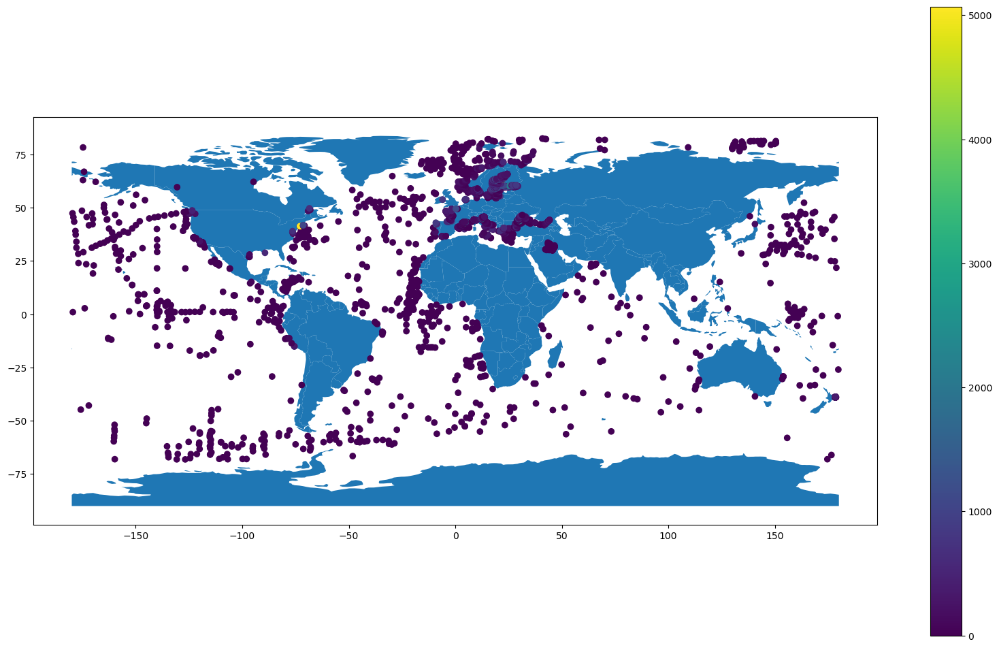

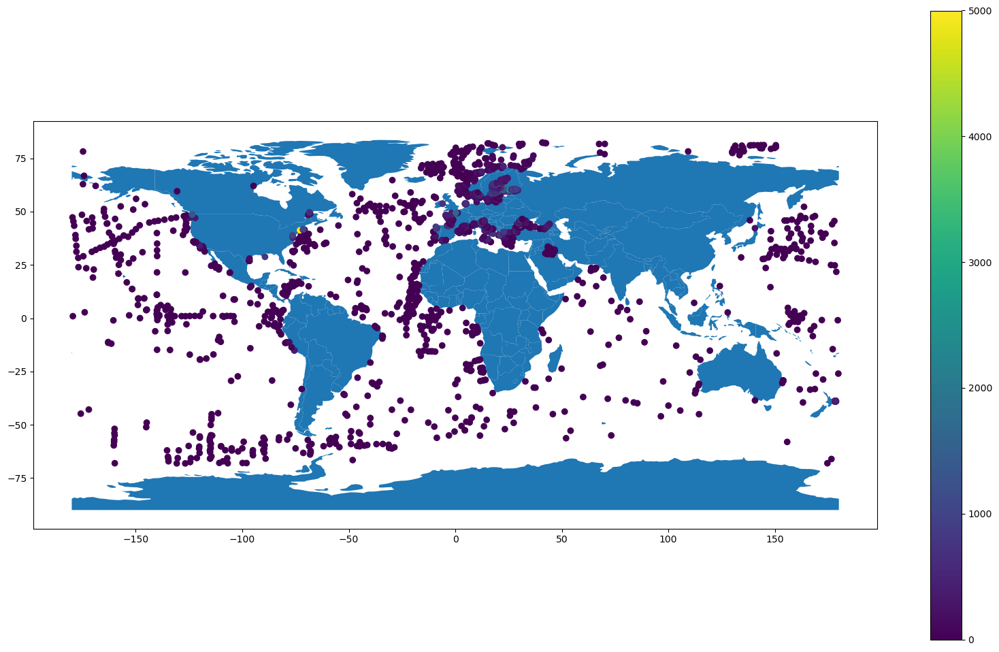

In [27]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_1['Longitude'], df_1['Latitude'])]
gdf_1 = GeoDataFrame(df_1, geometry=geometry)  
gdf_1.plot(ax = world.plot(figsize = (20, 12)), column = df_1["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_1['Longitude'], df_1['Latitude'])]
gdf_1 = GeoDataFrame(df_1, geometry=geometry)  
gdf_1.plot(ax = world.plot(figsize = (20, 12)), column = df_1["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 5000,legend = True);#"Sedimentation rate [cm/ka]"

df_1.describe()

/tmp/ipykernel_3264220/3976558503.py:31: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/3976558503.py:31: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/3976558503.py:31: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ip

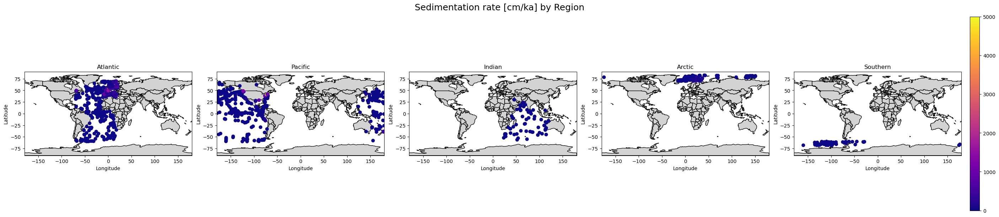

/tmp/ipykernel_3264220/3976558503.py:60: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/3976558503.py:60: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/3976558503.py:60: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ip

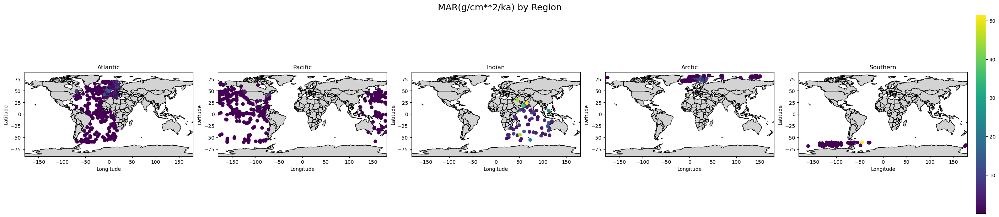

Region: Atlantic, Number of points: 1426
          Latitude    Longitude  Sedimentation rate [cm/ka]  MAR(g/cm**2/ka)
count  1426.000000  1426.000000                 1426.000000      1426.000000
mean     38.610026     0.214872                  296.166286       244.787267
std      28.443701    19.149348                  446.964187       354.052586
min     -59.920000   -69.833000                    0.000000         0.000000
25%      36.472829    -6.257708                    5.000000         3.433950
50%      44.935610     7.073316                  150.000000       118.560000
75%      58.207000    13.247250                  400.000000       327.307500
max      69.814170    19.997652                 4800.000000      3369.600000

Region: Pacific, Number of points: 555
         Latitude   Longitude  Sedimentation rate [cm/ka]  MAR(g/cm**2/ka)
count  555.000000  555.000000                  555.000000       555.000000
mean     5.026678  -15.614623                  118.701928        95.528636
s

In [28]:
# Plot 5 regions as a tile (1 row, 5 columns) for sedimentation rate and for MAR

import matplotlib.pyplot as plt

# Define region boundaries (example: Atlantic, Pacific, Indian, Arctic, Southern)
regions = {
    "Atlantic":    {"lat_min": -60, "lat_max": 70, "lon_min": -70, "lon_max": 20},
    "Pacific":     {"lat_min": -60, "lat_max": 70, "lon_min": 120, "lon_max": -70},  # Note: Pacific crosses dateline
    "Indian":      {"lat_min": -60, "lat_max": 30, "lon_min": 20, "lon_max": 120},
    "Arctic":      {"lat_min": 70,  "lat_max": 90, "lon_min": -180, "lon_max": 180},
    "Southern":    {"lat_min": -90, "lat_max": -60, "lon_min": -180, "lon_max": 180},
}

def region_mask(df, region):
    lat_mask = (df['Latitude'] >= region['lat_min']) & (df['Latitude'] <= region['lat_max'])
    # Handle Pacific region crossing the dateline
    if region['lon_min'] < region['lon_max']:
        lon_mask = (df['Longitude'] >= region['lon_min']) & (df['Longitude'] <= region['lon_max'])
    else:
        lon_mask = (df['Longitude'] >= region['lon_min']) | (df['Longitude'] <= region['lon_max'])
    return lat_mask & lon_mask

region_names = list(regions.keys())

# --- Sedimentation rate tile plot ---
fig, axes = plt.subplots(1, 5, figsize=(28, 6), constrained_layout=True)
for i, region_name in enumerate(region_names):
    bounds = regions[region_name]
    df_region = df_1[region_mask(df_1, bounds)]
    ax = axes[i]
    world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
    world.plot(ax=ax, color='lightgray', edgecolor='black')
    if not df_region.empty:
        geometry = [Point(xy) for xy in zip(df_region['Longitude'], df_region['Latitude'])]
        gdf_region = GeoDataFrame(df_region, geometry=geometry)
        gdf_region.plot(
            ax=ax, 
            column="Sedimentation rate [cm/ka]", 
            vmin=0, vmax=5000, 
            legend=(i==4),  # Only show legend on last plot
            cmap='plasma', 
            markersize=40
        )
    ax.set_title(f"{region_name}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    if i != 4:
        ax.get_legend().remove() if ax.get_legend() else None
fig.suptitle("Sedimentation rate [cm/ka] by Region", fontsize=18)
plt.show()

# --- MAR tile plot ---
fig, axes = plt.subplots(1, 5, figsize=(28, 6), constrained_layout=True)
for i, region_name in enumerate(region_names):
    bounds = regions[region_name]
    df_region = df_1[region_mask(df_1, bounds)]
    ax = axes[i]
    world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
    world.plot(ax=ax, color='lightgray', edgecolor='black')
    if not df_region.empty:
        geometry = [Point(xy) for xy in zip(df_region['Longitude'], df_region['Latitude'])]
        gdf_region = GeoDataFrame(df_region, geometry=geometry)
        gdf_region.plot(
            ax=ax, 
            column="MAR(g/cm**2/ka)", 
            legend=(i==4),  # Only show legend on last plot
            cmap='viridis', 
            markersize=40
        )
    ax.set_title(f"{region_name}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    if i != 4:
        ax.get_legend().remove() if ax.get_legend() else None
fig.suptitle("MAR(g/cm**2/ka) by Region", fontsize=18)
plt.show()

# Optionally, show descriptive statistics for each region
for region_name, bounds in regions.items():
    df_region = df_1[region_mask(df_1, bounds)]
    print(f"Region: {region_name}, Number of points: {len(df_region)}")
    print(df_region.describe())
    print()

### df_2

In [29]:
#data_path = Path().resolve().parents[3] / "work_old/work/toc-neural-nets/SelectFeaturesRun/pyfiles/" 
sedrate_labels_file2 = "sedRateData_timo_skagarrak.xlsx"

In [30]:
df_2 = pd.read_excel(Path(data_path / sedrate_labels_file2))

In [31]:
df_2

,Lat N,Long E,Station,Source,Sedimentation rate (cm/yr),Unnamed: 5,Lat N.1,Long E.1,Station.1,Source.1,MAR (g/cm2/yr)
0,57.863333,8.180000,RO 3.2,"Erlenkeuser and Padestadt, 1984",0.25,NaN,58.750000,10.621667,K1,"Stahl et al., 2004",0.33
1,57.915000,9.246667,1,"Erlenkeuser and Padestadt, 1984",0.16,NaN,58.706667,10.365000,K2,"Stahl et al., 2004",0.63
2,57.996667,9.333333,2,"Erlenkeuser and Padestadt, 1984",0.21,NaN,58.656667,10.260000,K3,"Stahl et al., 2004",0.23
3,58.771667,10.143333,SII-2,"Erlenkeuser and Padestadt, 1984",1.10,NaN,58.025000,9.596667,H2,"Stahl et al., 2004",0.22
4,58.049400,9.125250,AU1,"Deng et al., 2020",0.14,NaN,58.036667,9.585000,H3,"Stahl et al., 2004",0.15
5,58.103533,9.822333,AU2,"Deng et al., 2020",0.27,NaN,58.706667,10.365000,K2,"Stahl et al., 2004",0.63
6,57.806600,11.053233,AU3,"Deng et al., 2020",0.30,NaN,58.656667,10.260000,K3,"Stahl et al., 2004",0.23
7,58.366667,9.616667,A,"Paetzel and Schrader, 1993",0.24,NaN,58.008333,9.615000,H1,"Stahl et al., 2004",0.40
8,57.852222,8.250000,84-4,"Van Weering et al., 1987",0.23,NaN,58.036667,9.586667,H3,"Stahl et al., 2004",0.15
9,57.734722,8.333333,84-5,"Van Weering et al., 1987",0.14,NaN,58.431667,10.050000,T1,"Stahl et al., 2004",0.12


In [32]:
df_2 = df_2[["Lat N","Long E","Sedimentation rate (cm/yr)"]]
df_2 = df_2[df_2["Long E"]>-180]
df_2["Sedimentation rate (cm/yr)"] = df_2["Sedimentation rate (cm/yr)"]*1e3
df_2 = df_2.dropna(how="any")

In [33]:
df_2 = df_2.rename(columns={
    "Lat N": "Latitude",
    "Long E": "Longitude",
    "Sedimentation rate (cm/yr)": "Sedimentation rate [cm/ka]"
})

In [34]:
import pandas as pd

# Group by Latitude and Longitude and filter groups with more than one entry
df_2 = df_2.groupby(['Latitude', 'Longitude']).filter(lambda x: len(x) > 0)

# Display the filtered DataFrame
print("Filtered DataFrame:")
print(df_2)

# Group the data by Latitude and Longitude and calculate the mean of each group
df_2 = df_2.groupby(['Latitude', 'Longitude'], as_index=False).mean()

# Display the resulting DataFrame with averaged locations
print("DataFrame after averaging:")
print(df_2)

Filtered DataFrame:
     Latitude  Longitude  Sedimentation rate [cm/ka]
0   57.863333   8.180000                       250.0
1   57.915000   9.246667                       160.0
2   57.996667   9.333333                       210.0
3   58.771667  10.143333                      1100.0
4   58.049400   9.125250                       140.0
5   58.103533   9.822333                       270.0
6   57.806600  11.053233                       300.0
7   58.366667   9.616667                       240.0
8   57.852222   8.250000                       230.0
9   57.734722   8.333333                       140.0
10  57.634722   8.400000                       210.0
11  57.500000   8.500000                       120.0
12  57.783333   9.100000                       210.0
13  58.068056   8.883333                       110.0
14  58.134722   8.833333                       220.0
15  57.950833   9.817500                       280.0
16  58.035278   9.668056                        80.0
17  58.218056   9.333333  

In [35]:
df_2

,Latitude,Longitude,Sedimentation rate [cm/ka]
0,57.181400,9.793733,180.0
1,57.500000,8.500000,120.0
2,57.634722,8.400000,210.0
3,57.734722,8.333333,140.0
4,57.753180,8.286210,130.0
5,57.783333,9.100000,210.0
6,57.800278,11.019167,300.0
7,57.806600,11.053233,300.0
8,57.820167,9.484833,190.0
9,57.852222,8.250000,230.0


In [36]:
MAR_list = []
latitudes = np.linspace(-90, 90, 2161)      # from -90 to +90, every 0.1°
longitudes = np.linspace(-180, 180, 4321)   # from -180 to +180, every 0.1°
for idx, row in df_2.iterrows():
    lat, lon, sedrate = row["Latitude"], row["Longitude"], row["Sedimentation rate [cm/ka]"]
    lat_idx = find_nearest(lat, latitudes)
    lon_idx = find_nearest(lon, longitudes)
    porosity = int(dataset_numpy_porosity_graw[lat_idx, lon_idx])
    MAR = convertSR2MAR(sedrate, porosity, ds)
    MAR_list.append(MAR)

# Add MAR to the DataFrame
df_2["MAR(g/cm**2/ka)"] = MAR_list

In [37]:
df_2.head(n=10)

,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,57.181400,9.793733,180.0,177.84
1,57.500000,8.500000,120.0,118.56
2,57.634722,8.400000,210.0,196.56
3,57.734722,8.333333,140.0,134.68
4,57.753180,8.286210,130.0,125.06
5,57.783333,9.100000,210.0,207.48
6,57.800278,11.019167,300.0,234.00
7,57.806600,11.053233,300.0,241.80
8,57.820167,9.484833,190.0,192.66
9,57.852222,8.250000,230.0,221.26


/tmp/ipykernel_3264220/3842095961.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/3842095961.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
count,46.000000,46.000000,46.000000,46.000000
mean,58.610327,8.502898,235.652174,213.539130
std,1.314753,2.392193,169.792712,138.725142
min,57.181400,2.577000,30.000000,30.420000
25%,57.903750,8.350000,140.000000,130.195000
50%,58.160861,9.242542,210.000000,194.610000
75%,58.565533,9.813125,280.000000,238.680000
max,63.061000,11.291667,1100.000000,886.600000


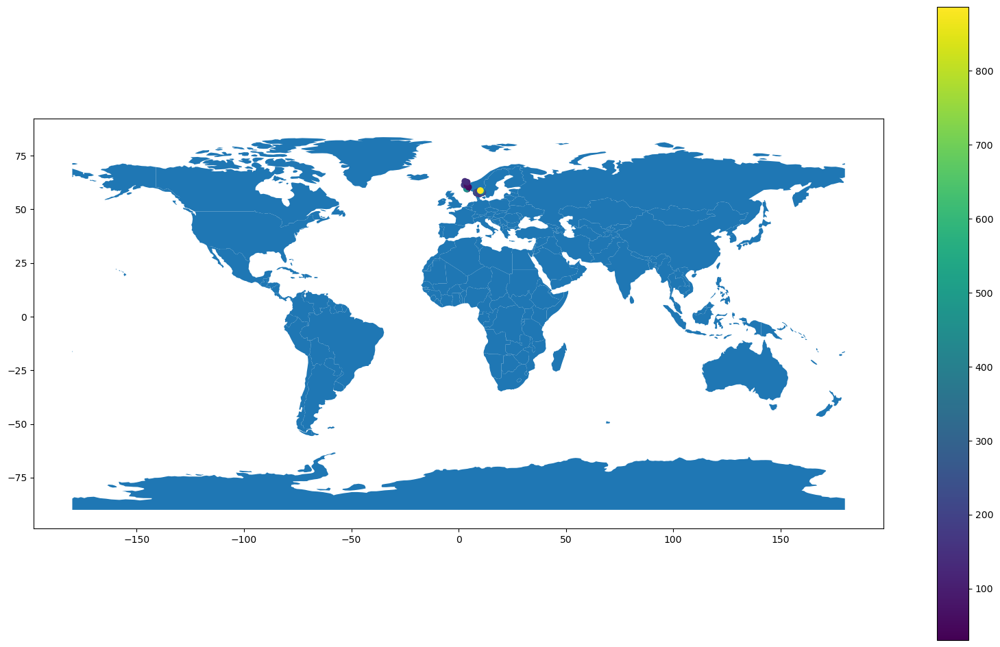

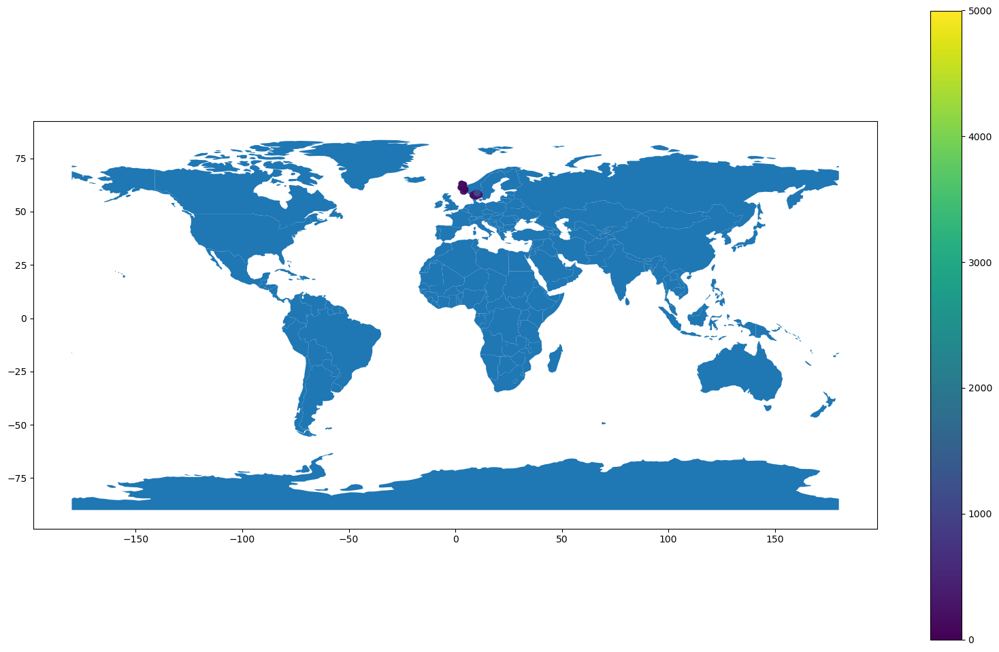

In [38]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_2['Longitude'], df_2['Latitude'])]
gdf_2 = GeoDataFrame(df_2, geometry=geometry)  
gdf_2.plot(ax = world.plot(figsize = (20, 12)), column = df_2["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_2['Longitude'], df_2['Latitude'])]
gdf_2 = GeoDataFrame(df_2, geometry=geometry)  
gdf_2.plot(ax = world.plot(figsize = (20, 12)), column = df_2["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 5000,legend = True);#"Sedimentation rate [cm/ka]"

df_2.describe()

### df_3

In [39]:
#data_path = Path().resolve().parents[3] / "work_old/work/toc-neural-nets/SelectFeaturesRun/pyfiles/" 
sedrate_labels_file3 = "sedRateData_Catubig_1998.csv"

In [40]:
df_3 = pd.read_csv(Path(data_path / sedrate_labels_file3), sep= "\t")

In [41]:
df_3

,Event,Method/Device,Latitude,Longitude,Elevation [m],Age [ka BP],CaCO3 [%],bSiO2 [%],MAR [g/cm**2/ka],Acc rate non CaCO3 [g/cm**2/ka],Reference
0,RC13-227,Piston corer,-21.8800,8.8720,-4301.0,21,66.0,NaN,0.60,0.21,"Balsam, 1988"
1,RE5-036,NaN,46.9167,-18.5833,-4500.0,21,11.0,NaN,1.40,1.25,"Balsam, 1988"
2,ERDC-079BX,Box corer,2.7850,156.2300,-2766.0,21,83.0,NaN,1.15,0.19,"Berger and Killingly, 1982"
3,ERDC-092BX,Box corer,-2.2250,156.9980,-1598.0,21,82.0,NaN,0.62,0.11,"Berger and Killingly, 1982"
4,ERDC-102BX,Box corer,-3.6050,161.3180,-2300.0,21,87.0,NaN,0.84,0.11,"Berger and Killingly, 1982"
...,...,...,...,...,...,...,...,...,...,...,...
102,RC13-259,Piston corer,-53.8800,-4.9300,-1754.0,21,0.0,50.0,1.05,0.52,"Yu , 1994; Murray et al., 1993"
103,RC13-271,Piston corer,-51.9900,4.5220,-3634.0,21,0.0,53.0,1.50,0.70,"Yu , 1994; Murray et al., 1993"
104,RC15-93,Piston corer,-46.1000,-13.2300,-2714.0,21,0.0,53.0,2.30,1.08,"Yu , 1994; Murray et al., 1993"
105,RC15-94,Piston corer,-42.9800,-20.8600,-3762.0,21,0.0,8.5,1.37,1.25,"Yu , 1994; Murray et al., 1993"


In [42]:
df_3 = df_3[["Latitude","Longitude","MAR [g/cm**2/ka]"]]

In [43]:
"""
df_3 = df_3[["Lat N","Long E","Sedimentation rate (cm/yr)"]]
df_3 = df_3[df_3["Long E"]>-180]
df_3["Sedimentation rate (cm/yr)"] = df_3["Sedimentation rate (cm/yr)"]*1e3
df_3 = df_3.dropna(how="any")
"""

'\ndf_3 = df_3[["Lat N","Long E","Sedimentation rate (cm/yr)"]]\ndf_3 = df_3[df_3["Long E"]>-180]\ndf_3["Sedimentation rate (cm/yr)"] = df_3["Sedimentation rate (cm/yr)"]*1e3\ndf_3 = df_3.dropna(how="any")\n'

In [44]:

df_3 = df_3.rename(columns={
    "MAR [g/cm**2/ka]": "MAR(g/cm**2/ka)"
})
df_3["MAR(g/cm**2/ka)"] = df_3["MAR(g/cm**2/ka)"]


In [45]:
import pandas as pd

# Group by Latitude and Longitude and filter groups with more than one entry
df_3 = df_3.groupby(['Latitude', 'Longitude']).filter(lambda x: len(x) > 0)

# Display the filtered DataFrame
print("Filtered DataFrame:")
print(df_3)

# Group the data by Latitude and Longitude and calculate the mean of each group
df_3 = df_3.groupby(['Latitude', 'Longitude'], as_index=False).mean()

# Display the resulting DataFrame with averaged locations
print("DataFrame after averaging:")
print(df_3)

Filtered DataFrame:
     Latitude  Longitude  MAR(g/cm**2/ka)
0    -21.8800     8.8720             0.60
1     46.9167   -18.5833             1.40
2      2.7850   156.2300             1.15
3     -2.2250   156.9980             0.62
4     -3.6050   161.3180             0.84
..        ...        ...              ...
102  -53.8800    -4.9300             1.05
103  -51.9900     4.5220             1.50
104  -46.1000   -13.2300             2.30
105  -42.9800   -20.8600             1.37
106  -43.1800    -3.2500             0.90

[107 rows x 3 columns]
DataFrame after averaging:
     Latitude  Longitude  MAR(g/cm**2/ka)
0    -63.0020   120.0500             3.26
1    -59.9970   105.0000             0.95
2    -55.0700   110.0180             0.99
3    -54.5500    75.8300             1.06
4    -54.3800   -22.1300             2.31
..        ...        ...              ...
101   44.4830  -163.4000              NaN
102   45.8280   155.7100             0.80
103   46.9167   -18.5833             1.40
104  

In [46]:
df_3

,Latitude,Longitude,MAR(g/cm**2/ka)
0,-63.0020,120.0500,3.26
1,-59.9970,105.0000,0.95
2,-55.0700,110.0180,0.99
3,-54.5500,75.8300,1.06
4,-54.3800,-22.1300,2.31
...,...,...,...
101,44.4830,-163.4000,NaN
102,45.8280,155.7100,0.80
103,46.9167,-18.5833,1.40
104,49.4270,-132.7670,0.47


In [47]:


latitudes = np.linspace(-90, 90, 2161)      # from -90 to +90, every 0.1°
longitudes = np.linspace(-180, 180, 4321)   # from -180 to +180, every 0.1°
sedrate_list = []

for idx, row in df_3.iterrows():
    lat, lon, MAR = row["Latitude"], row["Longitude"], row["MAR(g/cm**2/ka)"]
    lat_idx = find_nearest(lat, latitudes)
    lon_idx = find_nearest(lon, longitudes)
    porosity = int(dataset_numpy_porosity_graw[lat_idx, lon_idx])
    sedrate = convertMAR2SR(MAR, porosity, ds)
    sedrate_list.append(sedrate)

df_3["Sedimentation rate [cm/ka]"] = sedrate_list

In [48]:
df_3.head(n=10)

,Latitude,Longitude,MAR(g/cm**2/ka),Sedimentation rate [cm/ka]
0,-63.0020,120.0500,3.26,4.478022
1,-59.9970,105.0000,0.95,1.739927
2,-55.0700,110.0180,0.99,1.813187
3,-54.5500,75.8300,1.06,2.038462
4,-54.3800,-22.1300,2.31,4.442308
5,-53.8800,-4.9300,1.05,2.243590
6,-53.6700,-123.1000,NaN,NaN
7,-53.4370,114.2570,1.32,2.307692
8,-52.9005,109.8697,0.88,1.611722
9,-52.4830,114.0900,1.06,1.698718


/tmp/ipykernel_3264220/2564962304.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/2564962304.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,MAR(g/cm**2/ka),Sedimentation rate [cm/ka]
count,106.000000,106.000000,96.000000,96.000000
mean,-3.189621,-5.983758,1.478125,2.295894
std,31.554320,89.112051,1.462987,2.212057
min,-63.002000,-163.400000,0.070000,0.207101
25%,-31.897500,-43.631750,0.700000,1.110140
50%,2.471000,-20.742500,1.000000,1.561772
75%,6.692500,65.071000,1.520000,2.407576
max,57.000000,166.980000,8.480000,12.544379


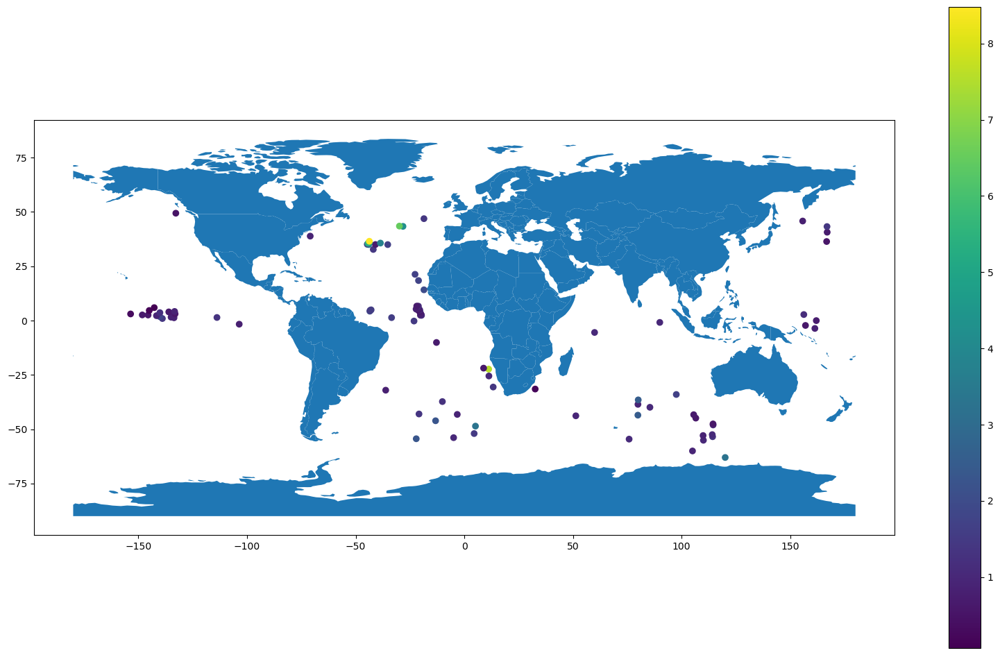

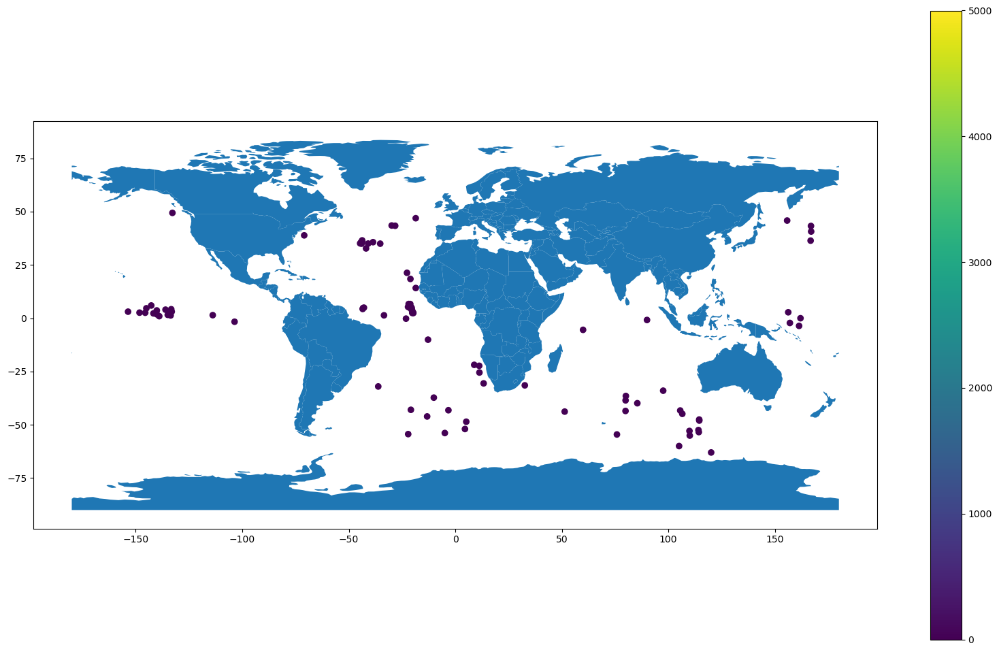

In [49]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_3['Longitude'], df_3['Latitude'])]
gdf_3 = GeoDataFrame(df_3, geometry=geometry)  
gdf_3.plot(ax = world.plot(figsize = (20, 12)), column = df_3["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_3['Longitude'], df_3['Latitude'])]
gdf_3 = GeoDataFrame(df_3, geometry=geometry)  
gdf_3.plot(ax = world.plot(figsize = (20, 12)), column = df_3["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 5000,legend = True);#"Sedimentation rate [cm/ka]"

df_3.describe()

### df_4

In [50]:
#data_path = Path().resolve().parents[3] / "work_old/work/toc-neural-nets/SelectFeaturesRun/pyfiles/" 
sedrate_labels_file4 = "sedRateData_Hohmann_2024.csv"

In [51]:
df_4 = pd.read_csv(Path(data_path / sedrate_labels_file4), sep= ",")

In [52]:
df_4

,boxModelID,dataContributors,coreName,S(cm/a),SMin,SMax,STracer,SComment,M1,M2,...,long1,long2,coordSource,coordComment,coringYear,coringMonth,coringYearEarliest,coringMonthEarliest,coringYearLatest,coringMonthLatest
0,BMID0001,Alperin et al. (1999),A,0.100,NaN,NaN,239240Pu + 210Pb,NaN,0.55,NaN,...,-75.0,-74.5,Fig 1 in alperin1999,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,BMID0002,Alperin et al. (1999),B,0.125,NaN,NaN,239240Pu + 210Pb,NaN,1.20,NaN,...,-75.0,-74.5,Fig 1 in alperin1999,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,BMID0003,Alperin et al. (1999),C,0.125,NaN,NaN,239240Pu + 210Pb,NaN,1.25,NaN,...,-75.0,-74.5,Fig 1 in alperin1999,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,BMID0004,Alperin et al. (1999),D,0.010,NaN,NaN,239240Pu + 210Pb,NaN,0.55,NaN,...,-75.0,-74.5,Fig 1 in alperin1999,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,BMID0005,Alperin et al. (1999),1,0.035,NaN,NaN,239240Pu + 210Pb,NaN,50.50,0.45,...,-75.0,-74.5,Fig 1 in alperin2002,NaN,1993.0,5.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
291,BMID0292,Zuo et al. (1991),8917,0.200,NaN,NaN,210Pb,NaN,1.33,NaN,...,3.0,6.0,map in zuo1991,NaN,1989.0,NaN,NaN,NaN,NaN,NaN
292,BMID0293,Zuo et al (1997),90-1,0.400,NaN,NaN,210Pb,NaN,7.00,NaN,...,NaN,NaN,NaN,NaN,1990.0,NaN,NaN,NaN,NaN,NaN
293,BMID0294,Zuo et al (1997),90-4,0.200,NaN,NaN,210Pb,NaN,6.00,NaN,...,NaN,NaN,NaN,NaN,1990.0,NaN,NaN,NaN,NaN,NaN
294,BMID0295,Zuo et al (1997),90-9,0.200,NaN,NaN,210Pb,NaN,2.00,NaN,...,NaN,NaN,NaN,NaN,1990.0,NaN,NaN,NaN,NaN,NaN


In [53]:
df_4 = df_4[["lat","long","S(cm/a)"]]

In [54]:
"""
df_3 = df_3[["Lat N","Long E","Sedimentation rate (cm/yr)"]]
df_3 = df_3[df_3["Long E"]>-180]
df_3["Sedimentation rate (cm/yr)"] = df_3["Sedimentation rate (cm/yr)"]*1e3
df_3 = df_3.dropna(how="any")
"""

'\ndf_3 = df_3[["Lat N","Long E","Sedimentation rate (cm/yr)"]]\ndf_3 = df_3[df_3["Long E"]>-180]\ndf_3["Sedimentation rate (cm/yr)"] = df_3["Sedimentation rate (cm/yr)"]*1e3\ndf_3 = df_3.dropna(how="any")\n'

In [55]:

df_4 = df_4.rename(columns={
    "lat": "Latitude",
    "long": "Longitude",
    "S(cm/a)": "Sedimentation rate [cm/ka]"
})
df_4["Sedimentation rate [cm/ka]"] = df_4["Sedimentation rate [cm/ka]"]*1e3


In [56]:
df_4

,Latitude,Longitude,Sedimentation rate [cm/ka]
0,36.333,-74.750,100.0
1,36.333,-74.750,125.0
2,36.333,-74.750,125.0
3,36.333,-74.750,10.0
4,36.067,-74.750,35.0
...,...,...,...
291,42.750,4.500,200.0
292,43.217,4.850,400.0
293,43.150,4.667,200.0
294,40.967,1.067,200.0


In [57]:
import pandas as pd

# Group by Latitude and Longitude and filter groups with more than one entry
df_4 = df_4.groupby(['Latitude', 'Longitude']).filter(lambda x: len(x) > 0)

# Display the filtered DataFrame
print("Filtered DataFrame:")
print(df_4)

# Group the data by Latitude and Longitude and calculate the mean of each group
df_4 = df_4.groupby(['Latitude', 'Longitude'], as_index=False).mean()

# Display the resulting DataFrame with averaged locations
print("DataFrame after averaging:")
print(df_4)

Filtered DataFrame:
     Latitude  Longitude  Sedimentation rate [cm/ka]
0      36.333    -74.750                       100.0
1      36.333    -74.750                       125.0
2      36.333    -74.750                       125.0
3      36.333    -74.750                        10.0
4      36.067    -74.750                        35.0
..        ...        ...                         ...
291    42.750      4.500                       200.0
292    43.217      4.850                       400.0
293    43.150      4.667                       200.0
294    40.967      1.067                       200.0
295    40.983      2.150                        70.0

[296 rows x 3 columns]
DataFrame after averaging:
     Latitude  Longitude  Sedimentation rate [cm/ka]
0     -63.333    -61.383                  156.000000
1     -63.167    -59.333                  117.000000
2     -62.933    -60.000                   57.000000
3     -53.267     35.900                    2.000000
4     -53.000     35.633    

In [58]:
df_4

,Latitude,Longitude,Sedimentation rate [cm/ka]
0,-63.333,-61.383,156.000000
1,-63.167,-59.333,117.000000
2,-62.933,-60.000,57.000000
3,-53.267,35.900,2.000000
4,-53.000,35.633,2.000000
...,...,...,...
153,76.500,-69.250,223.793103
154,76.739,-71.844,70.000000
155,77.483,39.433,130.000000
156,77.983,26.833,100.000000


In [59]:
MAR_list = []
latitudes = np.linspace(-90, 90, 2161)      # from -90 to +90, every 0.1°
longitudes = np.linspace(-180, 180, 4321)   # from -180 to +180, every 0.1°
for idx, row in df_4.iterrows():
    lat, lon, sedrate = row["Latitude"], row["Longitude"], row["Sedimentation rate [cm/ka]"]
    lat_idx = find_nearest(lat, latitudes)
    lon_idx = find_nearest(lon, longitudes)
    porosity = int(dataset_numpy_porosity_graw[lat_idx, lon_idx])
    MAR = convertSR2MAR(sedrate, porosity, ds)
    MAR_list.append(MAR)

# Add MAR to the DataFrame
df_4["MAR(g/cm**2/ka)"] = MAR_list

In [60]:
df_4.head(n=10)

,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,-63.333,-61.383,156.0,133.848
1,-63.167,-59.333,117.0,97.344
2,-62.933,-60.000,57.0,44.460
3,-53.267,35.900,2.0,1.040
4,-53.000,35.633,2.0,1.040
5,-52.983,35.717,2.0,1.144
6,-45.017,132.750,1.0,0.650
7,-41.367,114.133,1.0,0.650
8,-39.517,83.717,3.0,2.184
9,-39.383,104.367,3.0,2.184


/tmp/ipykernel_3264220/1237863893.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/1237863893.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
count,158.000000,158.000000,138.000000,138.000000
mean,31.393832,-27.486092,104.644897,90.238522
std,33.987052,58.746907,129.693174,116.949334
min,-63.333000,-151.190000,0.000000,0.000000
25%,19.058250,-71.233000,7.000000,3.822000
50%,40.900000,-13.083000,75.000000,66.582286
75%,49.024750,3.408500,140.000000,123.825000
max,78.233000,156.998000,900.000000,842.400000


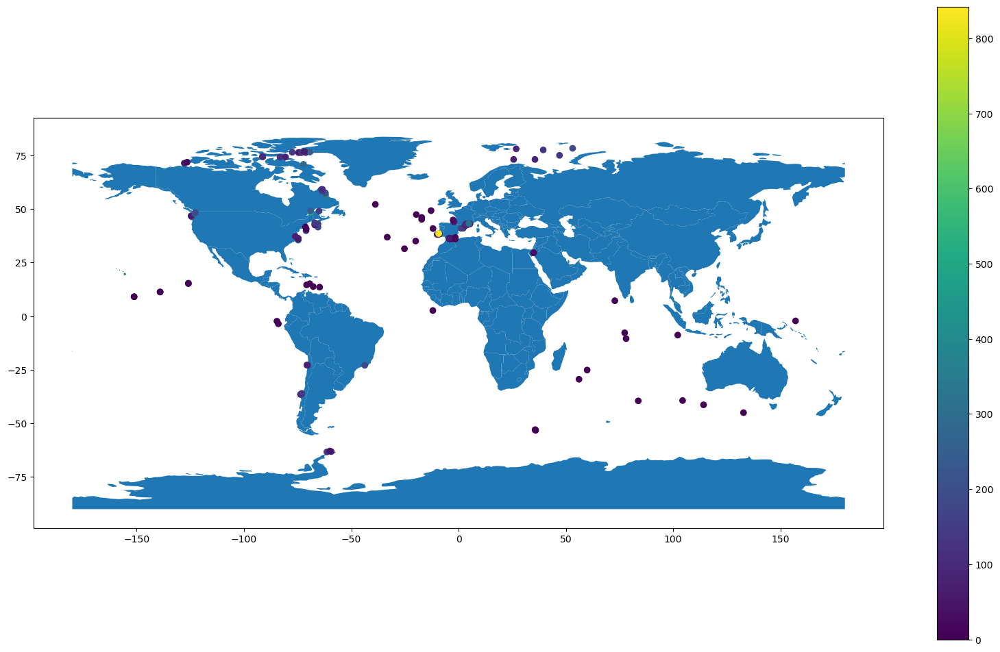

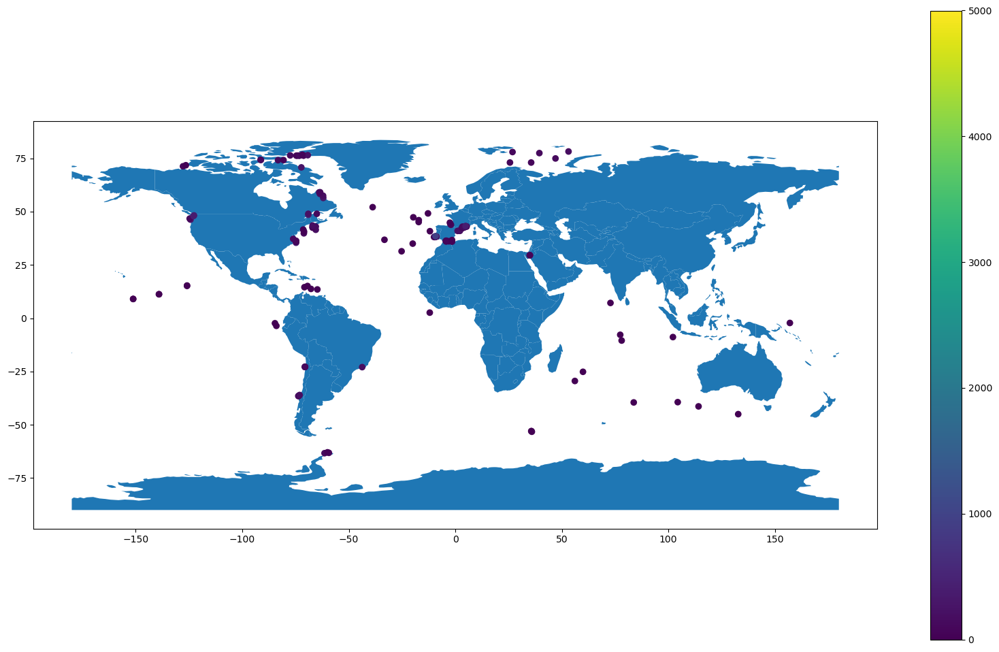

In [61]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_4['Longitude'], df_4['Latitude'])]
gdf_4 = GeoDataFrame(df_4, geometry=geometry)  
gdf_4.plot(ax = world.plot(figsize = (20, 12)), column = df_4["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_4['Longitude'], df_4['Latitude'])]
gdf_4 = GeoDataFrame(df_4, geometry=geometry)  
gdf_4.plot(ax = world.plot(figsize = (20, 12)), column = df_4["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 5000,legend = True);#"Sedimentation rate [cm/ka]"

df_4.describe()

### df_5

In [62]:
#data_path = Path().resolve().parents[3] / "work_old/work/toc-neural-nets/SelectFeaturesRun/pyfiles/" 
sedrate_labels_file5 = "sedRateData_MAR_Costa_2021.xlsx"

In [63]:
df_5 = pd.read_excel(Path(data_path / sedrate_labels_file5))

In [64]:
df_5

,INDEX,OCEAN,CoreName,Reference,Lat ˚N,Long ˚E,Water Depth (m),Lithogenic U/Th,Mean Holocene (0-5ka) Mass Flux (g/cm2kyr),Mean Holocene (0-5ka) 230Thxs0 (dpm/g),...,LGM/Hol(0-5ka) mass flux ratio,Holocene (0-5ka) Focusing Factor,LGM (18.5-23.5ka) Focusing Factor,Distance to Land (km),"Flag:AgeModel (1=14C or d18O constrained, 0=other)","Flag:Data (1=Raw Cncns or 230Thxs0 provided, 0=only Mass Flux provided)","Flag:Data (1=Errors provided, 0=No errors provided)",Quality Score (3=best),Comment,Full Citation
0,1,Atlantic,ODP1063,Lippold2009;Bohm2015,33.7000,-57.600000,4584.0,0.5,NaN,NaN,...,NaN,NaN,16.486791,1543.386490,1,1,1,3,NaN,"Lippold, J., Grützner, J., Winter, D., Lahaye,..."
1,2,Atlantic,GeoB3722,Lippold2012,-25.2500,12.023333,3506.0,0.6,1.393466,6.457077,...,0.660741,1.272196,3.221821,283.339130,1,1,1,3,NaN,"Lippold, J., Mulitza, S., Mollenhauer, G., Wey..."
2,3,Atlantic,GeoB1711,Lippold2012,-23.3400,12.380000,1967.0,0.6,1.242773,4.054832,...,0.676849,NaN,16.152888,217.040938,1,1,1,3,NaN,"Lippold, J., Mulitza, S., Mollenhauer, G., Wey..."
3,4,Atlantic,GeoB9508,Lippold2012;Mulitza2008,15.4995,-17.947000,2384.0,0.6,1.555817,3.995559,...,1.116220,4.956064,4.633839,100.726084,1,1,1,3,NaN,"Lippold, J., Mulitza, S., Mollenhauer, G., Wey..."
4,5,Atlantic,MD3242,Lippold2011,-4.2200,-37.830000,1008.0,0.5,1.686406,1.531295,...,NaN,NaN,NaN,31.134579,1,1,1,3,NaN,"Lippold, J., Gherardi, J. M., & Luo, Y. (2011)..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1162,1163,Southern,PS35-2715-3,Wengler2019,-57.0400,-88.010000,5190.0,0.4,0.286188,46.459746,...,NaN,NaN,NaN,1766.085716,0,1,1,2,NaN,"Wengler, M., Lamy, F., Struve, T., Borunda, A...."
1163,1164,Southern,PS35-2716-2,Wengler2019,-56.0200,-84.910000,5277.0,0.4,0.209260,64.604242,...,NaN,NaN,NaN,750.224027,0,1,1,2,NaN,"Wengler, M., Lamy, F., Struve, T., Borunda, A...."
1164,1165,Atlantic,OCE205-2 103GGC,Williams2016,26.0703,-78.056170,965.0,0.6,2.420851,1.030250,...,0.398706,3.143102,1.680381,62.129258,1,1,1,3,NaN,"Williams, R. H., McGee, D., Kinsley, C. W., Ri..."
1165,1166,Atlantic,OCE205-2 100GGC,Williams2016,26.0612,-78.027700,1057.0,0.6,2.509939,1.097854,...,NaN,3.182991,NaN,62.317084,1,1,1,3,NaN,"Williams, R. H., McGee, D., Kinsley, C. W., Ri..."


In [65]:
df_5 = df_5[["Lat ˚N","Long ˚E","Mean Holocene (0-5ka) Mass Flux (g/cm2kyr)"]]

In [66]:
"""
df_3 = df_3[["Lat N","Long E","Sedimentation rate (cm/yr)"]]
df_3 = df_3[df_3["Long E"]>-180]
df_3["Sedimentation rate (cm/yr)"] = df_3["Sedimentation rate (cm/yr)"]*1e3
df_3 = df_3.dropna(how="any")
"""

'\ndf_3 = df_3[["Lat N","Long E","Sedimentation rate (cm/yr)"]]\ndf_3 = df_3[df_3["Long E"]>-180]\ndf_3["Sedimentation rate (cm/yr)"] = df_3["Sedimentation rate (cm/yr)"]*1e3\ndf_3 = df_3.dropna(how="any")\n'

In [67]:

df_5 = df_5.rename(columns={
    "Lat ˚N": "Latitude",
    "Long ˚E": "Longitude",
    "Mean Holocene (0-5ka) Mass Flux (g/cm2kyr)": "MAR(g/cm**2/ka)"
})
df_5["MAR(g/cm**2/ka)"] = df_5["MAR(g/cm**2/ka)"]


In [68]:
df_5

,Latitude,Longitude,MAR(g/cm**2/ka)
0,33.7000,-57.600000,NaN
1,-25.2500,12.023333,1.393466
2,-23.3400,12.380000,1.242773
3,15.4995,-17.947000,1.555817
4,-4.2200,-37.830000,1.686406
...,...,...,...
1162,-57.0400,-88.010000,0.286188
1163,-56.0200,-84.910000,0.209260
1164,26.0703,-78.056170,2.420851
1165,26.0612,-78.027700,2.509939


In [69]:
import pandas as pd

# Group by Latitude and Longitude and filter groups with more than one entry
df_5 = df_5.groupby(['Latitude', 'Longitude']).filter(lambda x: len(x) > 0)

# Display the filtered DataFrame
print("Filtered DataFrame:")
print(df_5)

# Group the data by Latitude and Longitude and calculate the mean of each group
df_5 = df_5.groupby(['Latitude', 'Longitude'], as_index=False).mean()

# Display the resulting DataFrame with averaged locations
print("DataFrame after averaging:")
print(df_5)

Filtered DataFrame:
      Latitude  Longitude  MAR(g/cm**2/ka)
0      33.7000 -57.600000              NaN
1     -25.2500  12.023333         1.393466
2     -23.3400  12.380000         1.242773
3      15.4995 -17.947000         1.555817
4      -4.2200 -37.830000         1.686406
...        ...        ...              ...
1162  -57.0400 -88.010000         0.286188
1163  -56.0200 -84.910000         0.209260
1164   26.0703 -78.056170         2.420851
1165   26.0612 -78.027700         2.509939
1166    5.3300 -33.030000         0.777593

[1167 rows x 3 columns]
DataFrame after averaging:
      Latitude  Longitude  MAR(g/cm**2/ka)
0     -76.4000   -30.4000         1.137668
1     -71.1000   -20.8000         0.974409
2     -71.0956   -20.7793         0.917787
3     -70.1316   -14.2536         0.619066
4     -70.1000   -14.3000         0.643495
...        ...        ...              ...
1138   88.8000   143.4800         0.489135
1139   88.8000   143.5000         0.427257
1140   88.8700   140.1800

In [70]:
df_5["Longitude"].max()

179.8478

In [71]:
# from -180 to +180, every 0.1°
latitudes = np.linspace(-90, 90, 2161)      # from -90 to +90, every 0.1°
longitudes = np.linspace(-180, 180, 4321)   # from -180 to +180, every 0.1°
sedrate_list = []

for idx, row in df_5.iterrows():
    lat, lon, MAR = row["Latitude"], row["Longitude"], row["MAR(g/cm**2/ka)"]
    lat_idx = find_nearest(lat, latitudes)
    lon_idx = find_nearest(lon, longitudes)
    #print(lat_idx)
    #print(lon_idx)
    porosity = int(dataset_numpy_porosity_graw[lat_idx-1, lon_idx-1])
    sedrate = convertMAR2SR(MAR, porosity, ds)
    sedrate_list.append(sedrate)

df_5["Sedimentation rate [cm/ka]"] = sedrate_list

In [72]:
df_5

,Latitude,Longitude,MAR(g/cm**2/ka),Sedimentation rate [cm/ka]
0,-76.4000,-30.4000,1.137668,1.017592
1,-71.1000,-20.8000,0.974409,1.499091
2,-71.0956,-20.7793,0.917787,1.411980
3,-70.1316,-14.2536,0.619066,0.915779
4,-70.1000,-14.3000,0.643495,0.951915
...,...,...,...,...
1138,88.8000,143.4800,0.489135,0.648720
1139,88.8000,143.5000,0.427257,0.566654
1140,88.8700,140.1800,0.735416,1.010187
1141,89.0000,137.7000,0.859036,1.270764


/tmp/ipykernel_3264220/2520936693.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/2520936693.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,MAR(g/cm**2/ka),Sedimentation rate [cm/ka]
count,1143.000000,1143.000000,972.000000,972.000000
mean,-6.936336,-26.684310,1.636897,2.421092
std,45.301922,89.039747,2.602526,3.606454
min,-76.400000,-179.849200,0.075588,0.121134
25%,-51.691650,-91.165000,0.699969,1.060619
50%,-1.908300,-35.380000,1.141826,1.747029
75%,30.000000,10.096992,1.870310,2.756904
max,90.000000,179.847800,40.712994,62.635376


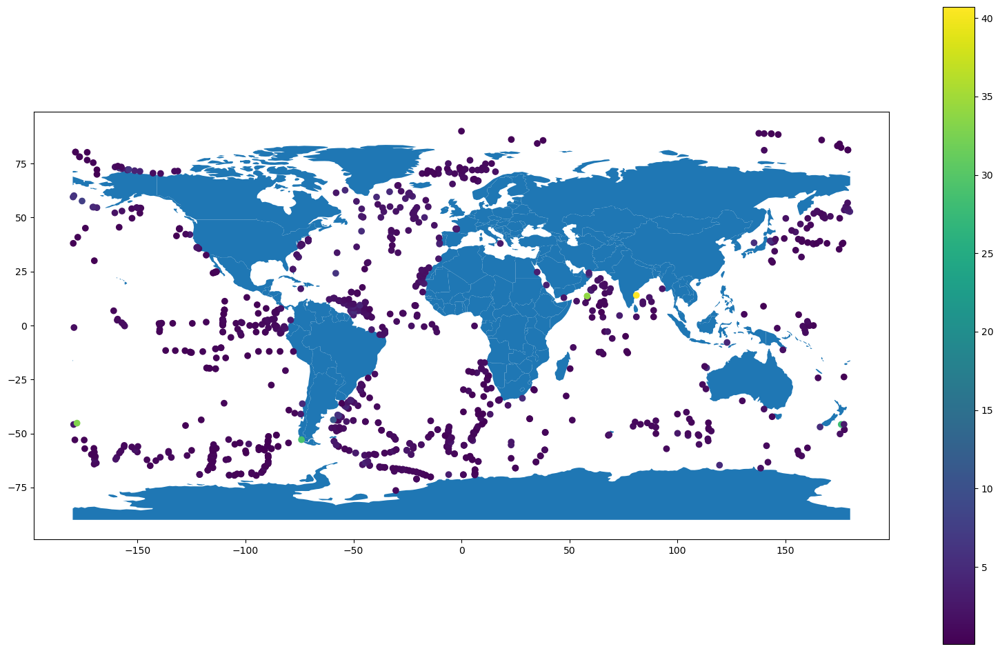

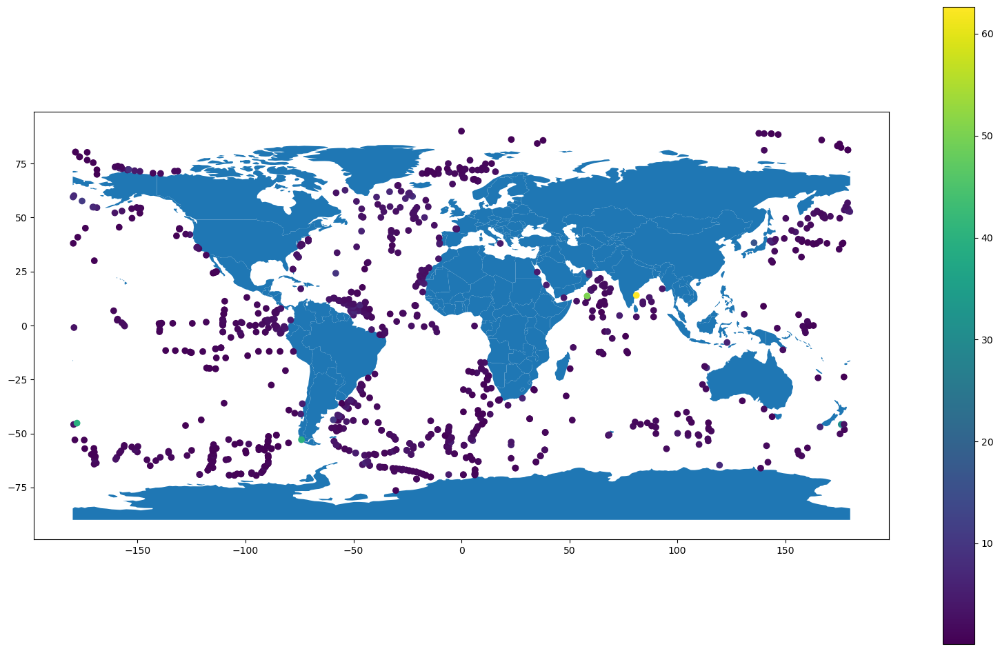

In [73]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_5['Longitude'], df_5['Latitude'])]
gdf_5 = GeoDataFrame(df_5, geometry=geometry)  
gdf_5.plot(ax = world.plot(figsize = (20, 12)), column = df_5["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_5['Longitude'], df_5['Latitude'])]
gdf_5 = GeoDataFrame(df_5, geometry=geometry)  
gdf_5.plot(ax = world.plot(figsize = (20, 12)), column = df_5["Sedimentation rate [cm/ka]"],legend = True);#"Sedimentation rate [cm/ka]"

df_5.describe()

### df_6

In [74]:
#data_path = Path().resolve().parents[3] / "work_old/work/toc-neural-nets/SelectFeaturesRun/pyfiles/" 
sedrate_labels_file6 = "sedRateData_Stahl_2004.csv"

In [75]:
df_6 = pd.read_csv(Path(data_path / sedrate_labels_file6), sep= ",")

In [76]:
df_6

,Latitude,Longitude,Station,Source,Unnamed: 4,MAR
0,58.750,10.622,K1,"Stahl et al., 2004",NaN,0.33
1,58.707,10.365,K2,"Stahl et al., 2004",NaN,0.63
2,58.657,10.260,K3,"Stahl et al., 2004",NaN,0.23
3,58.025,9.597,H2,"Stahl et al., 2004",NaN,0.22
4,58.037,9.585,H3,"Stahl et al., 2004",NaN,0.15
5,58.707,10.365,K2,"Stahl et al., 2004",NaN,0.63
6,58.657,10.260,K3,"Stahl et al., 2004",NaN,0.23
7,58.008,9.615,H1,"Stahl et al., 2004",NaN,0.40
8,58.037,9.587,H3,"Stahl et al., 2004",NaN,0.15
9,58.432,10.050,T1,"Stahl et al., 2004",NaN,0.12


In [77]:
df_6 = df_6[["Latitude","Longitude","MAR"]]

In [78]:
"""
df_3 = df_3[["Lat N","Long E","Sedimentation rate (cm/yr)"]]
df_3 = df_3[df_3["Long E"]>-180]
df_3["Sedimentation rate (cm/yr)"] = df_3["Sedimentation rate (cm/yr)"]*1e3
df_3 = df_3.dropna(how="any")
"""

'\ndf_3 = df_3[["Lat N","Long E","Sedimentation rate (cm/yr)"]]\ndf_3 = df_3[df_3["Long E"]>-180]\ndf_3["Sedimentation rate (cm/yr)"] = df_3["Sedimentation rate (cm/yr)"]*1e3\ndf_3 = df_3.dropna(how="any")\n'

In [79]:

df_6 = df_6.rename(columns={
    "MAR": "MAR(g/cm**2/ka)"
})
df_6["MAR(g/cm**2/ka)"] = df_6["MAR(g/cm**2/ka)"]*1e3


In [80]:
df_6

,Latitude,Longitude,MAR(g/cm**2/ka)
0,58.750,10.622,330.0
1,58.707,10.365,630.0
2,58.657,10.260,230.0
3,58.025,9.597,220.0
4,58.037,9.585,150.0
5,58.707,10.365,630.0
6,58.657,10.260,230.0
7,58.008,9.615,400.0
8,58.037,9.587,150.0
9,58.432,10.050,120.0


In [81]:
import pandas as pd

# Group by Latitude and Longitude and filter groups with more than one entry
df_6 = df_6.groupby(['Latitude', 'Longitude']).filter(lambda x: len(x) > 0)

# Display the filtered DataFrame
print("Filtered DataFrame:")
print(df_6)

# Group the data by Latitude and Longitude and calculate the mean of each group
df_6 = df_6.groupby(['Latitude', 'Longitude'], as_index=False).mean()

# Display the resulting DataFrame with averaged locations
print("DataFrame after averaging:")
print(df_6)

Filtered DataFrame:
   Latitude  Longitude  MAR(g/cm**2/ka)
0    58.750     10.622            330.0
1    58.707     10.365            630.0
2    58.657     10.260            230.0
3    58.025      9.597            220.0
4    58.037      9.585            150.0
5    58.707     10.365            630.0
6    58.657     10.260            230.0
7    58.008      9.615            400.0
8    58.037      9.587            150.0
9    58.432     10.050            120.0
DataFrame after averaging:
   Latitude  Longitude  MAR(g/cm**2/ka)
0    58.008      9.615            400.0
1    58.025      9.597            220.0
2    58.037      9.585            150.0
3    58.037      9.587            150.0
4    58.432     10.050            120.0
5    58.657     10.260            230.0
6    58.707     10.365            630.0
7    58.750     10.622            330.0


In [82]:
df_6

,Latitude,Longitude,MAR(g/cm**2/ka)
0,58.008,9.615,400.0
1,58.025,9.597,220.0
2,58.037,9.585,150.0
3,58.037,9.587,150.0
4,58.432,10.050,120.0
5,58.657,10.260,230.0
6,58.707,10.365,630.0
7,58.750,10.622,330.0


In [83]:
latitudes = np.linspace(-90, 90, 2161)      # from -90 to +90, every 0.1°
longitudes = np.linspace(-180, 180, 4321)   # from -180 to +180, every 0.1°
sedrate_list = []

for idx, row in df_6.iterrows():
    lat, lon, MAR = row["Latitude"], row["Longitude"], row["MAR(g/cm**2/ka)"]
    lat_idx = find_nearest(lat, latitudes)
    lon_idx = find_nearest(lon, longitudes)
    porosity = int(dataset_numpy_porosity_graw[lat_idx, lon_idx])
    sedrate = convertMAR2SR(MAR, porosity, ds)
    sedrate_list.append(sedrate)

df_6["Sedimentation rate [cm/ka]"] = sedrate_list

In [84]:
df_6.head(n=10)

,Latitude,Longitude,MAR(g/cm**2/ka),Sedimentation rate [cm/ka]
0,58.008,9.615,400.0,415.800416
1,58.025,9.597,220.0,228.690229
2,58.037,9.585,150.0,155.925156
3,58.037,9.587,150.0,155.925156
4,58.432,10.050,120.0,131.868132
5,58.657,10.260,230.0,268.065268
6,58.707,10.365,630.0,781.637717
7,58.750,10.622,330.0,396.634615


/tmp/ipykernel_3264220/1841961586.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/1841961586.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,MAR(g/cm**2/ka),Sedimentation rate [cm/ka]
count,8.000000,8.000000,8.000000,8.000000
mean,58.331625,9.960125,278.750000,316.818336
std,0.338958,0.419339,171.083731,216.580035
min,58.008000,9.585000,120.000000,131.868132
25%,58.034000,9.594500,150.000000,155.925156
50%,58.234500,9.832500,225.000000,248.377748
75%,58.669500,10.286250,347.500000,401.426065
max,58.750000,10.622000,630.000000,781.637717


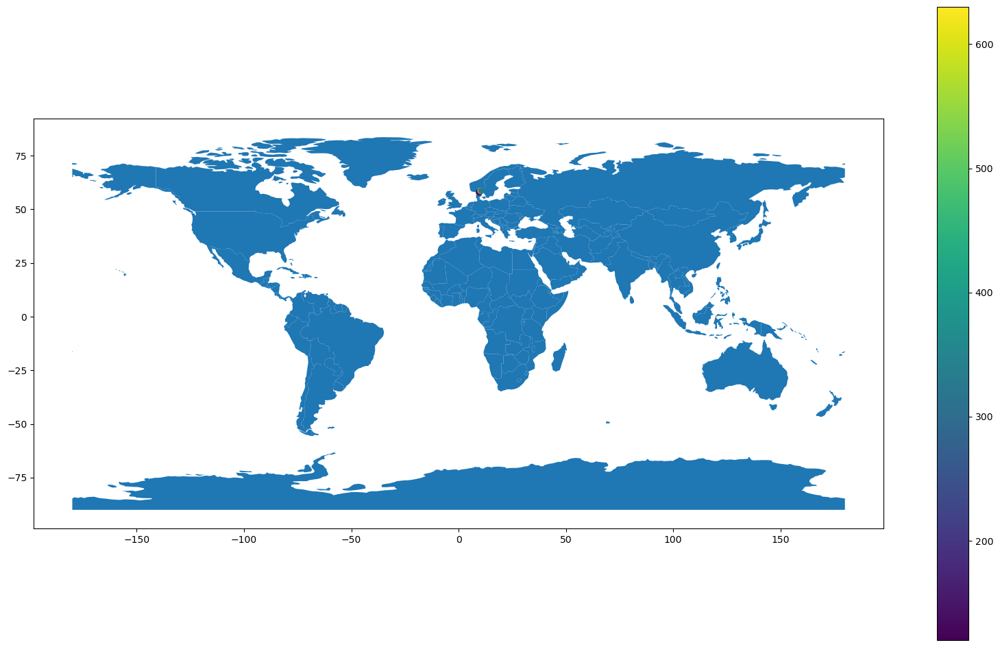

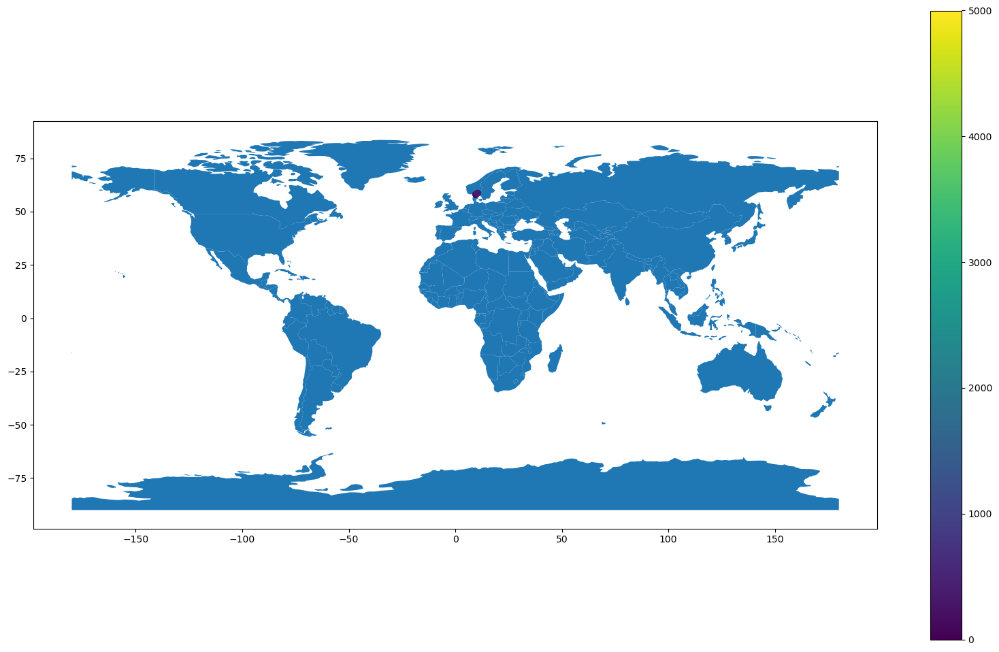

In [85]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_6['Longitude'], df_6['Latitude'])]
gdf_6 = GeoDataFrame(df_6, geometry=geometry)  
gdf_6.plot(ax = world.plot(figsize = (20, 12)), column = df_6["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_6['Longitude'], df_6['Latitude'])]
gdf_6 = GeoDataFrame(df_6, geometry=geometry)  
gdf_6.plot(ax = world.plot(figsize = (20, 12)), column = df_6["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 5000,legend = True);#"Sedimentation rate [cm/ka]"

df_6.describe()

### df_7

In [86]:
#data_path = Path().resolve().parents[3] / "work_old/work/toc-neural-nets/SelectFeaturesRun/pyfiles/" 
sedrate_labels_file7 = "sedRateData_diesing_2021.xlsx"

In [87]:
df_7 = pd.read_excel(Path(data_path / sedrate_labels_file7))

In [88]:
df_7

,FID,StnNo,Latitude,Longitude,SedRate,Unit,Method,Remarks,Source,POINT_X,POINT_Y,Unnamed: 11
0,54.0,,58.072000,10.000000,0.38000,cm/yr,210Pb,,"Anton et al. (1993) Mar. Geol., 111: 287-297.",4.320918e+06,3.885544e+06,NaN
1,63.0,,57.970000,9.352167,0.54000,cm/yr,210Pb,,"Anton et al. (1993) Mar. Geol., 111: 287-297.",4.282521e+06,3.874374e+06,NaN
2,16.0,4,58.918000,10.481000,0.09000,cm/yr,210Pb,,Bøe et al. (1996) NGU Bulletin. 430: 75-84.,4.348685e+06,3.979711e+06,NaN
3,17.0,11,58.807000,9.960000,0.05000,cm/yr,210Pb,,Bøe et al. (1996) NGU Bulletin. 430: 75-84.,4.318602e+06,3.967277e+06,NaN
4,20.0,21,58.675000,9.729000,0.25000,cm/yr,210Pb,,Bøe et al. (1996) NGU Bulletin. 430: 75-84.,4.305167e+06,3.952629e+06,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
386,NaN,NaN,53.992752,4.411802,0.00001,NaN,NaN,NaN,NaN,NaN,NaN,0.01
387,NaN,NaN,54.242752,4.411802,0.00001,NaN,NaN,NaN,NaN,NaN,NaN,0.01
388,NaN,NaN,54.492752,4.411802,0.00001,NaN,NaN,NaN,NaN,NaN,NaN,0.01
389,NaN,NaN,54.742752,4.411802,0.00001,NaN,NaN,NaN,NaN,NaN,NaN,0.01


In [89]:
df_7 = df_7[["Latitude","Longitude","SedRate"]]
df_7 = df_7[df_7["Longitude"]>-180]
df_7["SedRate"] = df_7["SedRate"]*1e3
df_7 = df_7.dropna(how="any")

In [90]:
df_7 = df_7.rename(columns={
    "SedRate": "Sedimentation rate [cm/ka]"
})

In [91]:
# 1. Extract rows with Sedimentation rate = 0.01
df_zero = df_7[df_7["Sedimentation rate [cm/ka]"] == 0.01]

# 2. Keep every 10th row (0, 10, 20, 30, ...)
df_zero_reduced = df_zero.iloc[::5]

# 3. Keep all other points normally
df_other = df_7[df_7["Sedimentation rate [cm/ka]"] != 0.01]

# 4. Combine reduced cluster + remaining points
df_thinned = pd.concat([df_other, df_zero_reduced], ignore_index=True)

# 5. Optional: sort by index or coordinates if needed
df_thinned = df_thinned.sort_values(["Latitude", "Longitude"]).reset_index(drop=True)

north_sea_bounds = {
    "lon_min": -5,
    "lon_max": 10,
    "lat_min": 51,
    "lat_max": 62
}





In [92]:
df_7 = df_thinned
import pandas as pd

# Group by Latitude and Longitude and filter groups with more than one entry
df_7 = df_7.groupby(['Latitude', 'Longitude']).filter(lambda x: len(x) > 0)

# Display the filtered DataFrame
print("Filtered DataFrame:")
print(df_7)

# Group the data by Latitude and Longitude and calculate the mean of each group
df_7 = df_7.groupby(['Latitude', 'Longitude'], as_index=False).mean()

# Display the resulting DataFrame with averaged locations
print("DataFrame after averaging:")
print(df_7)

Filtered DataFrame:
      Latitude  Longitude  Sedimentation rate [cm/ka]
0    52.242752   2.911802                        0.01
1    52.446333   3.208167                        0.00
2    52.492752   2.661802                        0.01
3    52.714500   4.000167                        0.00
4    52.742752   2.411802                        0.01
..         ...        ...                         ...
169  60.343300   4.655300                       60.00
170  60.499500   0.000000                        0.00
171  60.711800   4.171300                      280.00
172  60.724800   3.348200                       60.00
173  60.725000   4.495000                       30.00

[174 rows x 3 columns]
DataFrame after averaging:
      Latitude  Longitude  Sedimentation rate [cm/ka]
0    52.242752   2.911802                        0.01
1    52.446333   3.208167                        0.00
2    52.492752   2.661802                        0.01
3    52.714500   4.000167                        0.00
4    52.742

In [93]:
df_7

,Latitude,Longitude,Sedimentation rate [cm/ka]
0,52.242752,2.911802,0.01
1,52.446333,3.208167,0.00
2,52.492752,2.661802,0.01
3,52.714500,4.000167,0.00
4,52.742752,2.411802,0.01
...,...,...,...
167,60.343300,4.655300,60.00
168,60.499500,0.000000,0.00
169,60.711800,4.171300,280.00
170,60.724800,3.348200,60.00


In [94]:
MAR_list = []
latitudes = np.linspace(-90, 90, 2161)      # from -90 to +90, every 0.1°
longitudes = np.linspace(-180, 180, 4321)   # from -180 to +180, every 0.1°
for idx, row in df_7.iterrows():
    lat, lon, sedrate = row["Latitude"], row["Longitude"], row["Sedimentation rate [cm/ka]"]
    lat_idx = find_nearest(lat, latitudes)
    lon_idx = find_nearest(lon, longitudes)
    porosity = int(dataset_numpy_porosity_graw[lat_idx, lon_idx])
    MAR = convertSR2MAR(sedrate, porosity, ds)
    MAR_list.append(MAR)

# Add MAR to the DataFrame
df_7["MAR(g/cm**2/ka)"] = MAR_list

In [95]:
df_7.head(n=10)

,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,52.242752,2.911802,0.01,0.00936
1,52.446333,3.208167,0.00,0.00000
2,52.492752,2.661802,0.01,0.00962
3,52.714500,4.000167,0.00,0.00000
4,52.742752,2.411802,0.01,0.00988
5,52.992752,2.161802,0.01,0.00988
6,52.992752,3.661802,0.01,0.00884
7,53.006167,3.912667,0.00,0.00000
8,53.482500,0.647833,100.00,96.20000
9,53.492752,2.911802,0.01,0.00988


/tmp/ipykernel_3264220/1988729991.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/1988729991.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
count,172.000000,172.000000,172.000000,172.000000
mean,56.952834,5.966258,141.631105,131.369769
std,1.958115,3.336192,204.636154,183.290137
min,52.242752,-0.707647,0.000000,0.000000
25%,55.493992,3.274567,0.010000,0.009880
50%,57.696833,6.504000,80.000000,74.750000
75%,58.167917,9.182750,220.000000,203.970000
max,60.725000,10.843330,1100.000000,942.760000


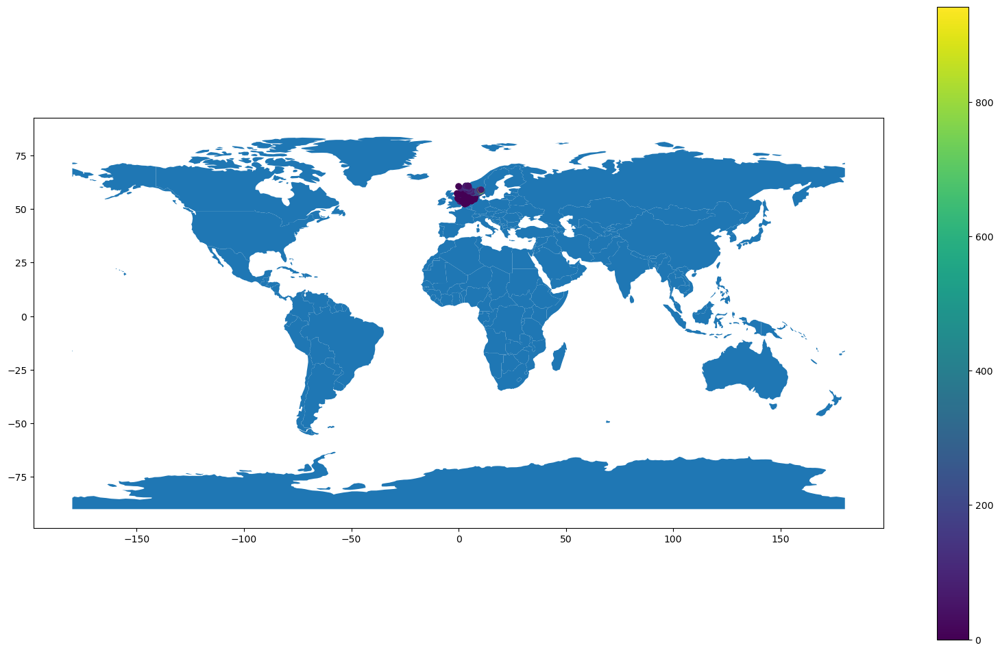

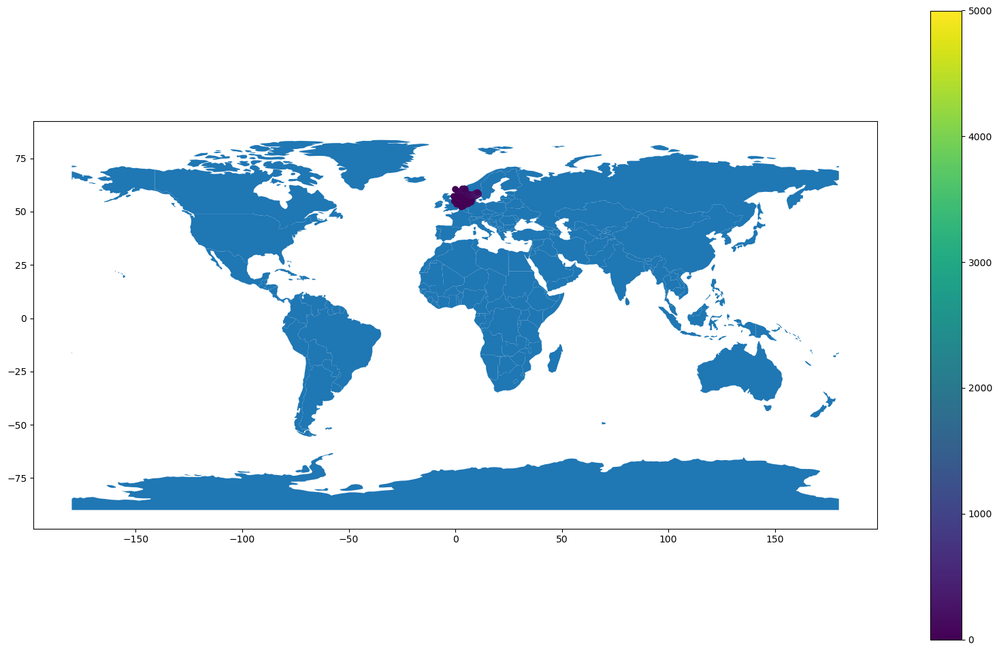

In [96]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_7['Longitude'], df_7['Latitude'])]
gdf_7 = GeoDataFrame(df_7, geometry=geometry)  
gdf_7.plot(ax = world.plot(figsize = (20, 12)), column = df_7["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_7['Longitude'], df_7['Latitude'])]
gdf_7 = GeoDataFrame(df_7, geometry=geometry)  
gdf_7.plot(ax = world.plot(figsize = (20, 12)), column = df_7["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 5000,legend = True);#"Sedimentation rate [cm/ka]"

df_7.describe()

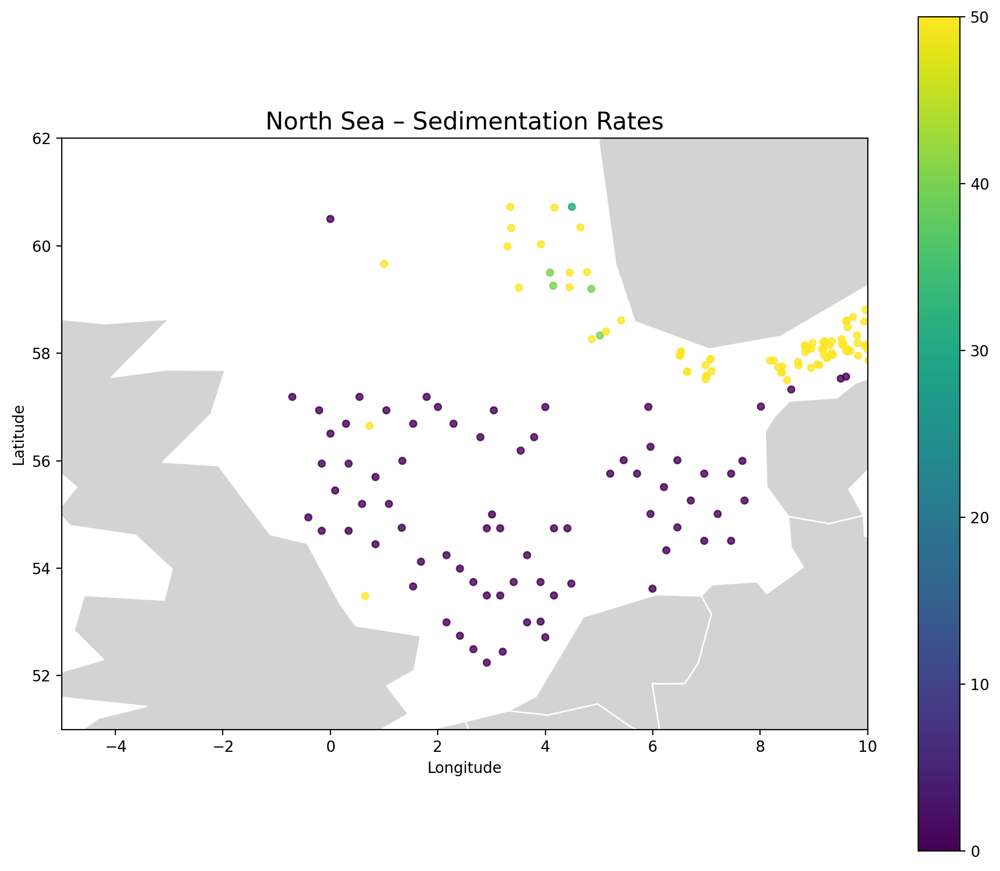

In [97]:
fig, ax = plt.subplots(figsize=(12, 10), dpi=200)

# Plot world boundaries
world.plot(ax=ax, color="lightgray", edgecolor="white")

# Plot only points in the North Sea region
gdf_7.plot(
    ax=ax,
    column=df_7["Sedimentation rate [cm/ka]"],  # or MAR(g/cm**2/ka)
    cmap="viridis",
    vmin=0,
    vmax=50,
    legend=True,
    markersize=20,
    alpha=0.8
)

# Set map limits (zooms into North Sea)
ax.set_xlim(north_sea_bounds["lon_min"], north_sea_bounds["lon_max"])
ax.set_ylim(north_sea_bounds["lat_min"], north_sea_bounds["lat_max"])

ax.set_title("North Sea – Sedimentation Rates", fontsize=16)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()


In [98]:
df_7

,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,52.242752,2.911802,0.01,0.00936
1,52.446333,3.208167,0.00,0.00000
2,52.492752,2.661802,0.01,0.00962
3,52.714500,4.000167,0.00,0.00000
4,52.742752,2.411802,0.01,0.00988
...,...,...,...,...
167,60.343300,4.655300,60.00,65.52000
168,60.499500,0.000000,0.00,0.00000
169,60.711800,4.171300,280.00,291.20000
170,60.724800,3.348200,60.00,63.96000


### df_8

In [99]:
#data_path = Path().resolve().parents[3] / "work_old/work/toc-neural-nets/SelectFeaturesRun/pyfiles/" 
sedrate_labels_file8 = "sedRateData_pandarinath_et_al_2004.xlsx"

In [100]:
df_8 = pd.read_excel(Path(data_path / sedrate_labels_file8))

In [101]:
df_8

,Area,Core no.,Location (water depth),Depth in the core,Dating technique (dated material),Age (yr BP),Sedimentation rate (mm/yr),Reference,Location (water depth).1,Sedimentation rate (mm/yr).1,Latitude,Longitude
0,Off Saurashtra,2502,(280 m) 21.87° N: 67.99° E,0.22-0.26 m,AMS 14C (p.f.),337±39,0.77,"Somayajulu et al., 1999",(280 m) 21.87° N: 67.99° E,0.77,21.935540,68.086962
1,Off Saurashtra,NaN,Shelf region,Top few mm,Excess 210Pb (sediment),NaN,1.8 to 19.0 (337 yr BP to present),"Borole, 1988",Shelf region,NaN,NaN,NaN
2,Off Mumbai,2586,Slope region (52 m) 23° N 71.2° E(?),Top few min,Excess 210PL (sediment),NaN,2.5,"Dilli, 1986",Slope region (52 m) 23° N 71.2° E(?),2.50,19.230835,72.113410
3,Off Vengurla,NaN,Inner shelf,Top few mm,Excess 210Pb (sediment),NaN,0.85: 1.00,"Nigam et al., 1995",Inner shelf,0.90,15.911487,73.237999
4,Off Karwar,GV 3713,(20 m),Top few mm,Excess 210pb (sediment),NaN,2.6,"Subbaraju et al., 1991",(20 m),2.60,14.350738,73.910279
5,Off Mulki,GC,(50 m),0-90,Excess 210Pb (sediment),NaN,0.72,"Karbassi, 1989",(50 m),0.72,13.177995,74.410983
6,Off Mangalore,SS/MC/02,(45 m),0-70,Excess 210Pb (sediment),NaN,0.56,"Manjunatha and Shankar, 1992",(45 m),0.56,12.873765,74.363132
7,Off Mangalore,SS/MG/04,-,0-60,Excess 210Pb,NaN,0.72,NaN,-,0.72,12.850627,74.560690
8,Off Mangalore,RVG/207,(35 m),0.50-0.60 m,14C (o.m.),1330±80,0.45 (1330 yr BP to present),"Pandarinath et al., 1998",(35 m),0.45,12.872469,74.448493
9,Off Mangalore,3104G,(1680 m) 12.83° N: 71.76° E,20-30,AMS C (p.f.),1357±90,0.02,"Agnihotri et al., 2003",(1680 m) 12.83° N: 71.76° E,0.02,12.830000,71.760000


In [102]:
df_8 = df_8[["Latitude","Longitude","Sedimentation rate (mm/yr).1"]]
df_8 = df_8[df_8["Longitude"]>-180]
df_8["Sedimentation rate (mm/yr).1"] = df_8["Sedimentation rate (mm/yr).1"]*100
df_8 = df_8.dropna(how="any")

In [103]:
df_8 = df_8.rename(columns={
    "Sedimentation rate (mm/yr).1": "Sedimentation rate [cm/ka]"
})
#df_8["Sedimentation rate [cm/ka]"] = df_8["Sedimentation rate [cm/ka]"]*100


In [104]:
import pandas as pd

# Group by Latitude and Longitude and filter groups with more than one entry
df_8 = df_8.groupby(['Latitude', 'Longitude']).filter(lambda x: len(x) > 0)

# Display the filtered DataFrame
print("Filtered DataFrame:")

print(df_8)

# Group the data by Latitude and Longitude and calculate the mean of each group
df_8 = df_8.groupby(['Latitude', 'Longitude'], as_index=False).mean()

# Display the resulting DataFrame with averaged locations
print("DataFrame after averaging:")
print(df_8)

Filtered DataFrame:
     Latitude  Longitude  Sedimentation rate [cm/ka]
0   21.935540  68.086962                        77.0
2   19.230835  72.113410                       250.0
3   15.911487  73.237999                        90.0
4   14.350738  73.910279                       260.0
5   13.177995  74.410983                        72.0
6   12.873765  74.363132                        56.0
7   12.850627  74.560690                        72.0
8   12.872469  74.448493                        45.0
9   12.830000  71.760000                         2.0
10  12.530000  74.170000                         2.0
11  12.520000  74.160000                         2.0
12   8.276703  75.999445                         3.0
13  10.380000  75.570000                        22.0
14   8.730000  76.030000                         1.0
15   8.200000  76.470000                        19.0
16   6.000000  74.000000                         1.0
DataFrame after averaging:
     Latitude  Longitude  Sedimentation rate [cm/ka]

In [105]:
df_8

,Latitude,Longitude,Sedimentation rate [cm/ka]
0,6.000000,74.000000,1.0
1,8.200000,76.470000,19.0
2,8.276703,75.999445,3.0
3,8.730000,76.030000,1.0
4,10.380000,75.570000,22.0
5,12.520000,74.160000,2.0
6,12.530000,74.170000,2.0
7,12.830000,71.760000,2.0
8,12.850627,74.560690,72.0
9,12.872469,74.448493,45.0


In [106]:
MAR_list = []
latitudes = np.linspace(-90, 90, 2161)      # from -90 to +90, every 0.1°
longitudes = np.linspace(-180, 180, 4321)   # from -180 to +180, every 0.1°
for idx, row in df_8.iterrows():
    lat, lon, sedrate = row["Latitude"], row["Longitude"], row["Sedimentation rate [cm/ka]"]
    lat_idx = find_nearest(lat, latitudes)
    lon_idx = find_nearest(lon, longitudes)
    porosity = int(dataset_numpy_porosity_graw[lat_idx, lon_idx])
    MAR = convertSR2MAR(sedrate, porosity, ds)
    MAR_list.append(MAR)

# Add MAR to the DataFrame
df_8["MAR(g/cm**2/ka)"] = MAR_list

In [107]:
df_8

,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,6.000000,74.000000,1.0,0.676
1,8.200000,76.470000,19.0,16.302
2,8.276703,75.999445,3.0,1.794
3,8.730000,76.030000,1.0,0.728
4,10.380000,75.570000,22.0,18.304
5,12.520000,74.160000,2.0,1.664
6,12.530000,74.170000,2.0,1.664
7,12.830000,71.760000,2.0,1.352
8,12.850627,74.560690,72.0,52.416
9,12.872469,74.448493,45.0,42.120


/tmp/ipykernel_3264220/2848008710.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/2848008710.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
count,16.000000,16.000000,16.00000,16.000000
mean,12.666885,73.955712,60.87500,50.142625
std,4.059608,2.027370,82.15179,71.404965
min,6.000000,68.086962,1.00000,0.676000
25%,9.967500,73.742209,2.00000,1.664000
50%,12.840314,74.266566,33.50000,30.212000
75%,13.471181,74.813018,73.25000,52.825500
max,21.935540,76.470000,260.00000,236.600000


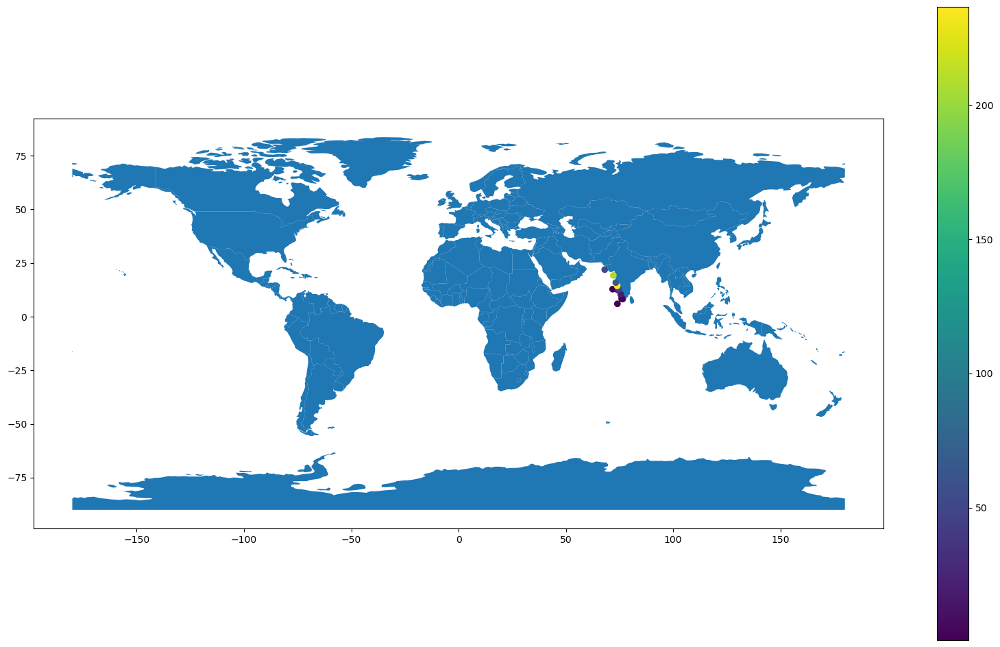

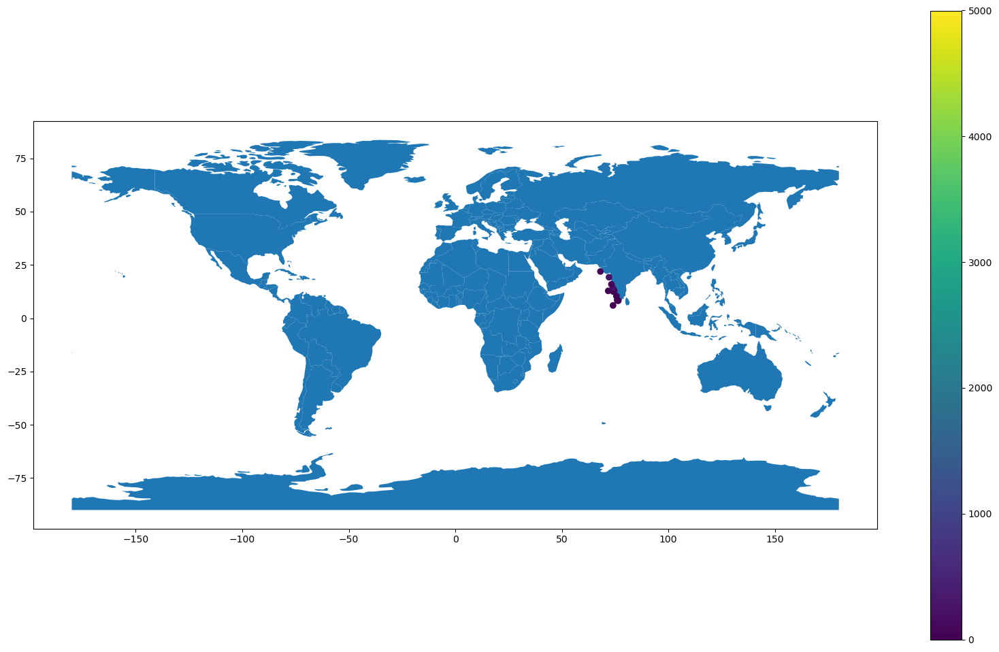

In [108]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_8['Longitude'], df_8['Latitude'])]
gdf_8 = GeoDataFrame(df_8, geometry=geometry)  
gdf_8.plot(ax = world.plot(figsize = (20, 12)), column = df_8["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_8['Longitude'], df_8['Latitude'])]
gdf_8 = GeoDataFrame(df_8, geometry=geometry)  
gdf_8.plot(ax = world.plot(figsize = (20, 12)), column = df_8["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 5000,legend = True);#"Sedimentation rate [cm/ka]"

df_8.describe()

### df_9

In [109]:
#data_path = Path().resolve().parents[3] / "work_old/work/toc-neural-nets/SelectFeaturesRun/pyfiles/" 
sedrate_labels_file9 = "sedRateData_srisuksawad_et_al_1997.xlsx"

In [110]:
df_9 = pd.read_excel(Path(data_path / sedrate_labels_file9))

In [111]:
df_9

,Region,Station,Latitude,Longitude,Depth (m),Accum. Rate (mg/cm²/yr),SR @ Interface (cm/yr),SR @ Depth (cm/yr),Mixed Layer Depth (cm),Surface Mixing Coeff. (cm²/yr),Particle Residence (yr),Depositional Activity (dpm/g),Steady State Flux (dpm/cm²/yr),Total Inventory (dpm/cm²),Decimal Latitude,Decimal Longitude
0,Upper Gulf,Chula 8a,13°20′N,100°40′E,18,270,0.78,0.35,16.0,48,32,3.1,0.83,27.0,13.3333,100.6667
1,NaN,Chula 12a,13°02′N,100°31′E,20,270,0.31,0.25,7.4,≥21,27,2.1,0.55,18.0,13.0333,100.5167
2,NaN,Chula 17a,12°59′N,100°30′E,24,490,0.41,0.47,5.9,≥24,14,1.7,0.78,25.0,12.9833,100.5000
3,NaN,Chula 23a,12°45′N,100°30′E,25,310,0.21,0.18,3.1,≥6.2,14,2.3,0.68,22.0,12.7500,100.5000
4,NaN,Chula 35a,12°36′N,100°30′E,23,307,0.24,0.22,2.8,≥6.4,12,1.7,0.49,16.0,12.6000,100.5000
5,NaN,Average,—,—,22,330,0.39,0.29,7.0,≥21,20,2.2,0.67,21.0,NaN,NaN
6,Western Margin,Chula 2,11°55′N,100°20′E,30,310,0.44,0.29,13.0,4,41,1.6,0.47,15.0,11.9167,100.3333
7,NaN,Chula 6,11°10′N,99°55′E,46,170,0.27,0.14,8.7,3.5,31,4.5,0.74,24.0,11.1667,99.9167
8,NaN,Chula 20,9°50′N,99°35′E,23,260,0.41,0.35,14.0,5.1,29,2.2,0.54,17.0,9.8333,99.5833
9,NaN,Suk 44,7°45′N,101°15′E,48,350,0.62,0.42,18.0,≥89,36,4.2,1.50,47.0,7.7500,101.2500


In [112]:
df_9 = df_9[["Decimal Latitude","Decimal Longitude","SR @ Interface (cm/yr)"]]
df_9 = df_9[df_9["Decimal Longitude"]>-180]
df_9["SR @ Interface (cm/yr)"] = df_9["SR @ Interface (cm/yr)"]*1000
df_9 = df_9.dropna(how="any")

In [113]:
df_9 = df_9.rename(columns={
    "SR @ Interface (cm/yr)": "Sedimentation rate [cm/ka]",
    "Decimal Latitude": "Latitude",
    "Decimal Longitude": "Longitude"
})
#df_8["Sedimentation rate [cm/ka]"] = df_8["Sedimentation rate [cm/ka]"]*100


In [114]:
import pandas as pd

# Group by Latitude and Longitude and filter groups with more than one entry
df_9 = df_9.groupby(['Latitude', 'Longitude']).filter(lambda x: len(x) > 0)

# Display the filtered DataFrame
print("Filtered DataFrame:")
print(df_9)

# Group the data by Latitude and Longitude and calculate the mean of each group
df_9 = df_9.groupby(['Latitude', 'Longitude'], as_index=False).mean()

# Display the resulting DataFrame with averaged locations
print("DataFrame after averaging:")
print(df_9)

Filtered DataFrame:
    Latitude  Longitude  Sedimentation rate [cm/ka]
0    13.3333   100.6667                       780.0
1    13.0333   100.5167                       310.0
2    12.9833   100.5000                       410.0
3    12.7500   100.5000                       210.0
4    12.6000   100.5000                       240.0
6    11.9167   100.3333                       440.0
7    11.1667    99.9167                       270.0
8     9.8333    99.5833                       410.0
9     7.7500   101.2500                       620.0
10    7.0833   102.1667                       410.0
12   12.5500   101.2167                       250.0
13   12.1667   101.7500                       150.0
15   11.4167   101.4167                       330.0
16   11.6667   102.8333                       430.0
17   10.3333   100.7500                       240.0
18   10.3333   101.7500                       150.0
19    9.0000   101.3333                       160.0
20    9.2500   101.7500                     

In [115]:
df_9

,Latitude,Longitude,Sedimentation rate [cm/ka]
0,7.0833,102.1667,410.0
1,7.3333,102.5833,190.0
2,7.5833,103.0000,400.0
3,7.7500,101.2500,620.0
4,8.0167,101.6333,170.0
5,8.2500,102.0833,370.0
6,9.0000,101.3333,160.0
7,9.2500,101.7500,170.0
8,9.8333,99.5833,410.0
9,10.3333,100.7500,240.0


In [116]:
MAR_list = []
latitudes = np.linspace(-90, 90, 2161)      # from -90 to +90, every 0.1°
longitudes = np.linspace(-180, 180, 4321)   # from -180 to +180, every 0.1°
for idx, row in df_9.iterrows():
    lat, lon, sedrate = row["Latitude"], row["Longitude"], row["Sedimentation rate [cm/ka]"]
    lat_idx = find_nearest(lat, latitudes)
    lon_idx = find_nearest(lon, longitudes)
    porosity = int(dataset_numpy_porosity_graw[lat_idx, lon_idx])
    MAR = convertSR2MAR(sedrate, porosity, ds)
    MAR_list.append(MAR)

# Add MAR to the DataFrame
df_9["MAR(g/cm**2/ka)"] = MAR_list

In [117]:
df_9.head(n=10)

,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,7.0833,102.1667,410.0,266.50
1,7.3333,102.5833,190.0,123.50
2,7.5833,103.0000,400.0,280.80
3,7.7500,101.2500,620.0,403.00
4,8.0167,101.6333,170.0,106.08
5,8.2500,102.0833,370.0,230.88
6,9.0000,101.3333,160.0,104.00
7,9.2500,101.7500,170.0,114.92
8,9.8333,99.5833,410.0,266.50
9,10.3333,100.7500,240.0,156.00


/tmp/ipykernel_3264220/430915439.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/430915439.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
count,22.000000,22.000000,22.000000,22.000000
mean,10.470450,101.274241,323.181818,220.775455
std,2.127059,0.926154,160.189958,108.779100
min,7.083300,99.583300,150.000000,101.400000
25%,8.437500,100.504175,195.000000,128.115000
50%,10.750000,101.291650,290.000000,212.810000
75%,12.454175,101.750000,410.000000,277.225000
max,13.333300,103.000000,780.000000,527.280000


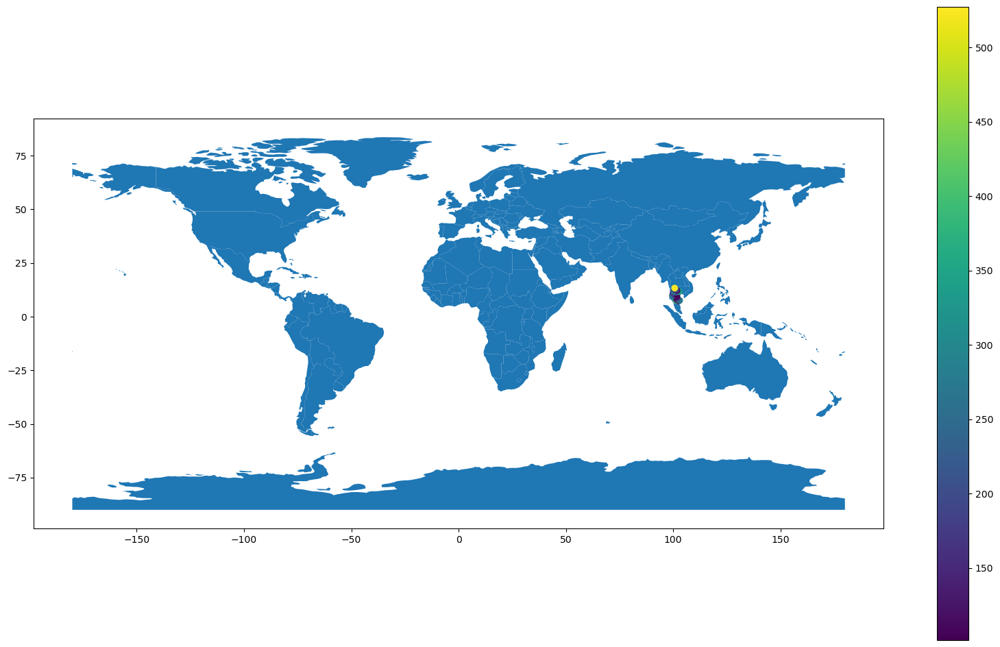

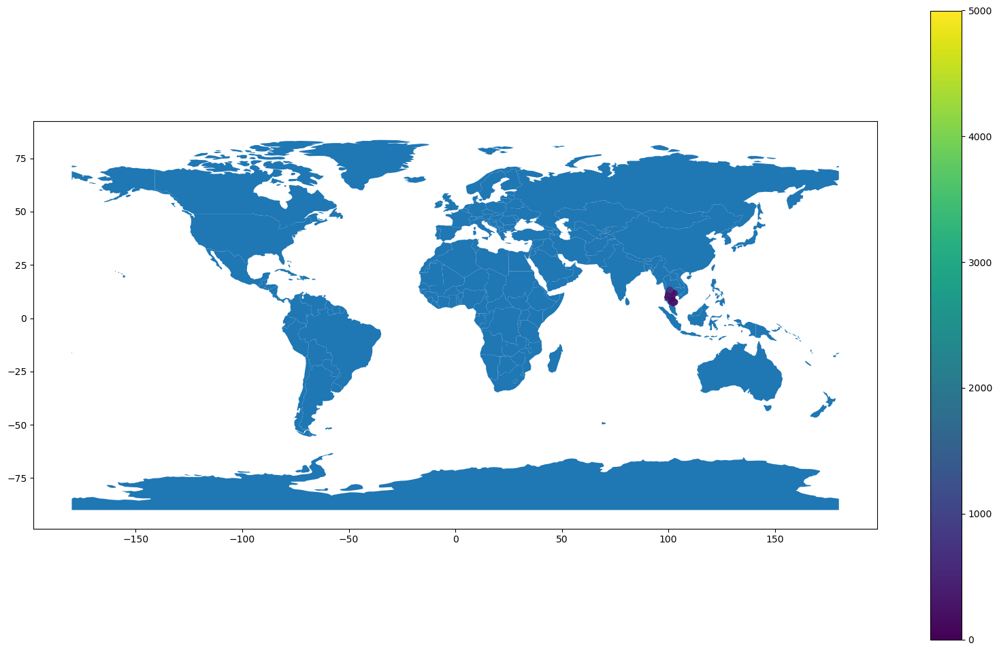

In [118]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_9['Longitude'], df_9['Latitude'])]
gdf_9 = GeoDataFrame(df_9, geometry=geometry)  
gdf_9.plot(ax = world.plot(figsize = (20, 12)), column = df_9["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_9['Longitude'], df_9['Latitude'])]
gdf_9 = GeoDataFrame(df_9, geometry=geometry)  
gdf_9.plot(ax = world.plot(figsize = (20, 12)), column = df_9["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 5000,legend = True);#"Sedimentation rate [cm/ka]"

df_9.describe()

### df_10

In [119]:
#data_path = Path().resolve().parents[3] / "work_old/work/toc-neural-nets/SelectFeaturesRun/pyfiles/" 
sedrate_labels_file10 = "sedRateData_Munoz_et_al_2004.xlsx"

In [120]:
df_10 = pd.read_excel(Path(data_path / sedrate_labels_file10), sheet_name="Sheet2")

In [121]:
df_10

,Region,Station,Bulk Density (g/cm³),Accum. Rate Param,Sed. Mixed Layer (cm),Accum. Rate (g/cm²/yr) with std,SR (cm/yr) with std,Model r²,CPE (µg/g),Unnamed: 9,Unnamed: 10,Latitude (DMS),Longitude (DMS),Decimal Latitude,Decimal Longitude,Accum. Rate (g/cm²/yr),SR (cm/yr)
0,Callao,Sta. A,—,—,4–8,0.06 ± 0.03,0.13 ± 0.02ᵇ,0.96,99.4 ± 2.3ᵇ,NaN,12°22.7′S–77°29.1′W,12°22.7′S,77°29.1′W,-12.3783,-77.4850,0.06,0.13
1,NaN,Sta. B,—,—,—,—,—,—,11.2 ± 0.6ᵇ,NaN,12°32.5′S–77°29.6′W,12°32.5′S,77°29.6′W,-12.5417,-77.4933,,
2,NaN,Sta. C,0.91,0.51,c,0.04 ± 0.01,0.10 ± 0.01ᵇ,0.98,23.3 ± 2.0ᵇ,NaN,12°32.8′S–77°34.8′W,12°32.8′S,77°34.8′W,-12.5467,-77.5800,0.04,0.1
3,Iquique,Sta. 6,—,—,c,0.05 ± 0.01,0.10 ± 0.01,0.97,n.a.,NaN,21°03.82′S–70°12.99′W,21°03.82′S,70°12.99′W,-21.0637,-70.2165,0.05,0.1
4,NaN,Sta. 7,3.06,2.85,—,0.04 ± 0.01,0.08 ± 0.01,0.95,n.a.,NaN,21°03.82′S–70°16.79′W,21°03.82′S,70°16.79′W,-21.0637,-70.2798,0.04,0.08
5,Mejillones,GEOB 7104,—,—,c,0.05 ± 0.01,0.04 ± 0.01,0.88,42.0 ± 4.0ᵈ,99.4±2.3b,22°52.03′S–70° 29.39′W,22°52.03′S,70°29.39′W,-22.8672,-70.4898,0.05,0.04
6,NaN,GEOB 7106,1.29,0.61,c,0.12 ± 0.02,0.17 ± 0.03,0.85,25.1 ± 0.6ᵈ,11.2±0.6b,22°48.02′S–70° 36.71′W,22°48.02′S,70°36.71′W,-22.8003,-70.6118,0.12,0.17
7,Concepción,5d,1.33,0.52,4,0.18 ± 0.04,0.24 ± 0.05,0.98,n.a.,23.3±2.0b,35°44.34′S–73°04.49′W,35°44.34′S,73°04.49′W,-35.7390,-73.0748,0.18,0.24
8,NaN,4c,1.88,1.46,8,0.11 ± 0.01,0.26 ± 0.03,0.99,n.a.,NaN,36°02.38′S–73°05.10′W,36°02.38′S,73°05.10′W,-36.0397,-73.0850,0.11,0.26
9,NaN,GEOB 7160,1.14,0.73,4,0.10 ± 0.03,0.24 ± 0.07,0.96,29.9 ± 0.7ᵈ,n.a.,36°02.34′S–73°04.39′W,36°02.34′S,73°04.39′W,-36.0390,-73.0732,0.1,0.24


In [122]:
MAR_list = df_10["Accum. Rate (g/cm²/yr) "]*1000
df_10 = df_10[["Decimal Latitude","Decimal Longitude","SR (cm/yr)"]]
df_10 = df_10[df_10["Decimal Longitude"]>-180]
df_10["SR (cm/yr)"] = df_10["SR (cm/yr)"]*1000
df_10 = df_10.dropna(how="any")


In [123]:
df_10 = df_10.rename(columns={
    "SR (cm/yr)": "Sedimentation rate [cm/ka]",
    "Decimal Latitude": "Latitude",
    "Decimal Longitude": "Longitude"
})
#df_8["Sedimentation rate [cm/ka]"] = df_8["Sedimentation rate [cm/ka]"]*100


In [124]:
df_10 = df_10.drop(index=[1])
MAR_list = MAR_list.drop(index=[1])

In [125]:
df_10

,Latitude,Longitude,Sedimentation rate [cm/ka]
0,-12.3783,-77.4850,130.0
2,-12.5467,-77.5800,100.0
3,-21.0637,-70.2165,100.0
4,-21.0637,-70.2798,80.0
5,-22.8672,-70.4898,40.0
6,-22.8003,-70.6118,170.0
7,-35.7390,-73.0748,240.0
8,-36.0397,-73.0850,260.0
9,-36.0390,-73.0732,240.0
10,-36.4255,-73.3887,90.0


In [126]:
import pandas as pd

# Group by Latitude and Longitude and filter groups with more than one entry
df_10 = df_10.groupby(['Latitude', 'Longitude']).filter(lambda x: len(x) > 0)

# Display the filtered DataFrame
print("Filtered DataFrame:")
print(df_10)

# Group the data by Latitude and Longitude and calculate the mean of each group
df_10 = df_10.groupby(['Latitude', 'Longitude'], as_index=False).mean()

# Display the resulting DataFrame with averaged locations
print("DataFrame after averaging:")
print(df_10)

Filtered DataFrame:
    Latitude  Longitude Sedimentation rate [cm/ka]
0   -12.3783   -77.4850                      130.0
2   -12.5467   -77.5800                      100.0
3   -21.0637   -70.2165                      100.0
4   -21.0637   -70.2798                       80.0
5   -22.8672   -70.4898                       40.0
6   -22.8003   -70.6118                      170.0
7   -35.7390   -73.0748                      240.0
8   -36.0397   -73.0850                      260.0
9   -36.0390   -73.0732                      240.0
10  -36.4255   -73.3887                       90.0
11  -36.4278   -73.3890                      140.0
12  -36.4253   -73.3890                      150.0
13  -36.5395   -73.6710                      260.0
14  -36.5570   -73.6742                      250.0
15  -36.4665   -73.7747                      180.0
16  -36.4517   -73.9080                      180.0
17  -42.5827   -74.8368                      220.0
18  -42.5443   -75.0183                      220.0
19  -42.452

In [127]:
df_10["Sedimentation rate [cm/ka]"] = pd.to_numeric(df_10["Sedimentation rate [cm/ka]"], errors='coerce')

In [128]:
"""
MAR_list = []
latitudes = np.linspace(-90, 90, 2161)      # from -90 to +90, every 0.1°
longitudes = np.linspace(-180, 180, 4321)   # from -180 to +180, every 0.1°
for idx, row in df_10.iterrows():
    lat, lon, sedrate = row["Latitude"], row["Longitude"], row["Sedimentation rate [cm/ka]"]
    lat_idx = find_nearest(lat, latitudes)
    lon_idx = find_nearest(lon, longitudes)
    porosity = int(dataset_numpy_porosity_graw[lat_idx, lon_idx])
    MAR = convertSR2MAR(sedrate, porosity, ds)
    MAR_list.append(MAR)
"""

# Add MAR to the DataFrame
df_10["MAR(g/cm**2/ka)"] = MAR_list


In [129]:
df_10.head(n=10)

,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,-42.5827,-74.8368,220.0,60.0
1,-42.5443,-75.0183,220.0,NaN
2,-42.4520,-75.2108,290.0,40.0
3,-36.5570,-73.6742,250.0,50.0
4,-36.5395,-73.6710,260.0,40.0
5,-36.4665,-73.7747,180.0,50.0
6,-36.4517,-73.9080,180.0,120.0
7,-36.4278,-73.3890,140.0,180.0
8,-36.4255,-73.3887,90.0,110.0
9,-36.4253,-73.3890,150.0,100.0


In [130]:
df_10["MAR(g/cm**2/ka)"] = pd.to_numeric(df_10["MAR(g/cm**2/ka)"], errors='coerce')

/tmp/ipykernel_3264220/148523548.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/148523548.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
count,19.000000,19.000000,19.000000,18.000000
mean,-31.758416,-73.481916,175.789474,72.777778
std,9.685408,2.094534,72.825193,39.378339
min,-42.582700,-77.580000,40.000000,40.000000
25%,-36.503000,-74.372400,115.000000,50.000000
50%,-36.425300,-73.389000,180.000000,50.000000
75%,-22.833750,-73.074000,240.000000,95.000000
max,-12.378300,-70.216500,290.000000,180.000000


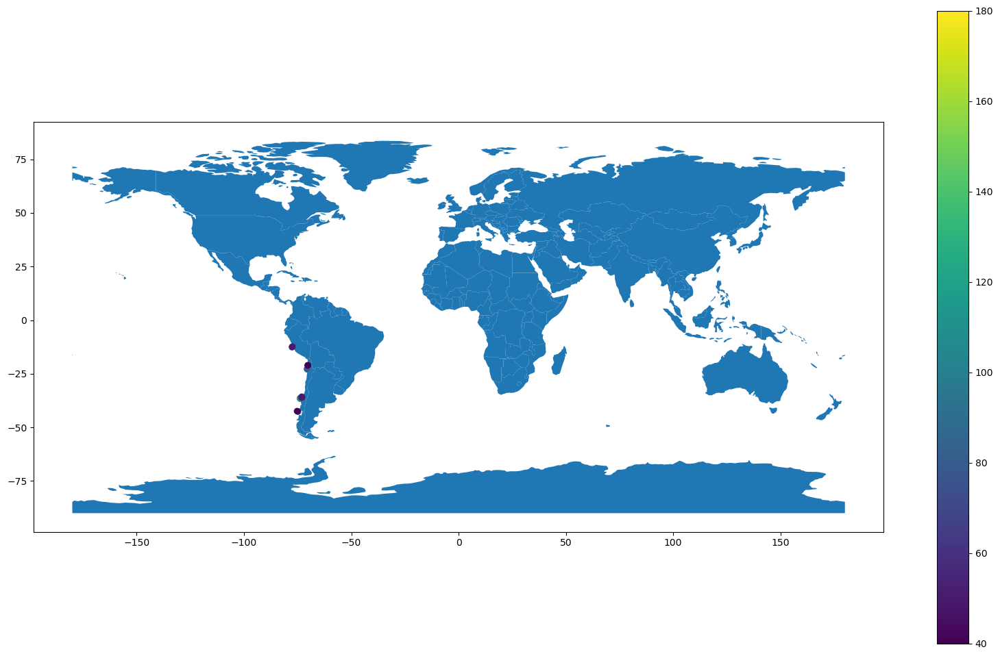

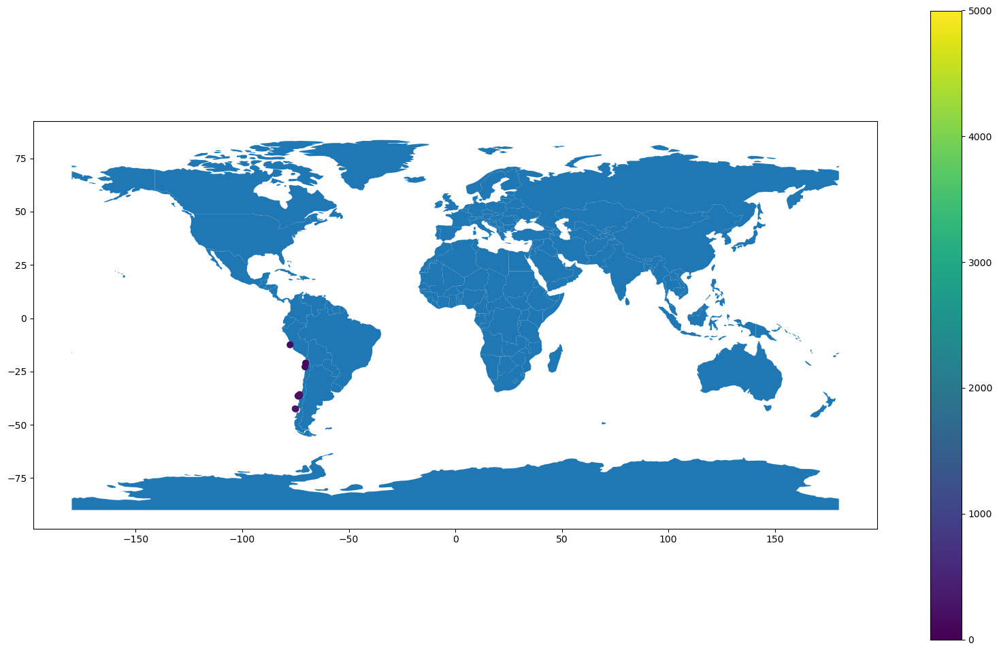

In [131]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_10['Longitude'], df_10['Latitude'])]
gdf_10 = GeoDataFrame(df_10, geometry=geometry)  
gdf_10.plot(ax = world.plot(figsize = (20, 12)), column = df_10["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_10['Longitude'], df_10['Latitude'])]
gdf_10 = GeoDataFrame(df_10, geometry=geometry)  
gdf_10.plot(ax = world.plot(figsize = (20, 12)), column = df_10["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 5000,legend = True);#"Sedimentation rate [cm/ka]"

df_10.describe()

### df_11

In [132]:
#data_path = Path().resolve().parents[3] / "work_old/work/toc-neural-nets/SelectFeaturesRun/pyfiles/" 
sedrate_labels_file11 = "sedRateData_singh_et_al_2017.xlsx"

In [133]:
df_11 = pd.read_excel(Path(data_path / sedrate_labels_file11), sheet_name="Sheet2")

In [134]:
df_11

,Sr. No.,Reference,Core,Latitude (N),Longitude (E),Depth (m),Sedimentation rate (cm/ka)
0,1,"Rao et al., 2012",GC-4/SK-148/32,20.50,69.40,111,37.5
1,2,NaN,GC-3/SK-148/30,21.10,69.20,121,13.0
2,3,"Thamban et al., 2001",GC-05,10.38,75.56,280,13.5
3,4,"Staubwasser et al., 2002",63 KA/41KL,24.60,65.91,316,64.0
4,5,"Tiwari et al., 2005",SK145 GC09,13.00,74.00,400,20.0
5,6,"Thamban et al., 2007",SK148 GC55,17.75,70.86,500,43.0
6,7,"Sarkar et al., 1990",SK20/185,10.00,71.83,523,3.0
7,8,"Schulz et al., 1998",136KL,23.11,66.50,568,24.0
8,9,"Von Rod et al., 1995",SO90-137KL,23.12,66.49,573,34.0
9,10,"Sarkar et al., 2000",3268G5,12.53,74.16,600,8.0


In [135]:
df_11 = df_11[["Latitude (N)","Longitude (E)","Sedimentation rate (cm/ka)"]]
df_11 = df_11[df_11["Longitude (E)"]>-180]
#df_11["Sedimentation rate (cm/ka)"] = df_11["Sedimentation rate (cm/ka)"]*1000
df_11 = df_11.dropna(how="any")

In [136]:
df_11 = df_11.rename(columns={
    "Sedimentation rate (cm/ka)": "Sedimentation rate [cm/ka]",
    "Latitude (N)": "Latitude",
    "Longitude (E)": "Longitude"
})
#df_8["Sedimentation rate [cm/ka]"] = df_8["Sedimentation rate [cm/ka]"]*100


In [137]:
import pandas as pd

# Group by Latitude and Longitude and filter groups with more than one entry
df_11 = df_11.groupby(['Latitude', 'Longitude']).filter(lambda x: len(x) > 0)

# Display the filtered DataFrame
print("Filtered DataFrame:")
print(df_11)

# Group the data by Latitude and Longitude and calculate the mean of each group
df_11 = df_11.groupby(['Latitude', 'Longitude'], as_index=False).mean()

# Display the resulting DataFrame with averaged locations
print("DataFrame after averaging:")
print(df_11)

Filtered DataFrame:
    Latitude  Longitude  Sedimentation rate [cm/ka]
0      20.50      69.40                        37.5
1      21.10      69.20                        13.0
2      10.38      75.56                        13.5
3      24.60      65.91                        64.0
4      13.00      74.00                        20.0
5      17.75      70.86                        43.0
6      10.00      71.83                         3.0
7      23.11      66.50                        24.0
8      23.12      66.49                        34.0
9      12.53      74.16                         8.0
11     23.10      66.48                         9.0
12      8.27      76.54                        16.5
13     11.50      74.62                        11.0
14     24.80      64.00                        57.0
15     22.54      64.04                         5.0
16     23.33      65.57                        15.0
18     15.53      72.56                         9.0
19     10.97      74.99                     

In [138]:
df_11

,Latitude,Longitude,Sedimentation rate [cm/ka]
0,3.70,75.90,5.0
1,6.00,74.00,4.0
2,6.38,78.65,4.0
3,6.50,75.98,4.0
4,7.50,76.00,6.0
5,7.50,76.71,64.5
6,8.03,76.05,5.0
7,8.27,76.54,16.5
8,8.58,75.33,6.0
9,8.77,73.70,3.5


In [139]:
MAR_list = []
latitudes = np.linspace(-90, 90, 2161)      # from -90 to +90, every 0.1°
longitudes = np.linspace(-180, 180, 4321)   # from -180 to +180, every 0.1°
for idx, row in df_11.iterrows():
    lat, lon, sedrate = row["Latitude"], row["Longitude"], row["Sedimentation rate [cm/ka]"]
    lat_idx = find_nearest(lat, latitudes)
    lon_idx = find_nearest(lon, longitudes)
    porosity = int(dataset_numpy_porosity_graw[lat_idx, lon_idx])
    MAR = convertSR2MAR(sedrate, porosity, ds)
    MAR_list.append(MAR)

# Add MAR to the DataFrame
df_11["MAR(g/cm**2/ka)"] = MAR_list

In [140]:
df_11.head(n=10)

,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,3.70,75.90,5.0,3.380
1,6.00,74.00,4.0,2.704
2,6.38,78.65,4.0,2.704
3,6.50,75.98,4.0,2.600
4,7.50,76.00,6.0,3.900
5,7.50,76.71,64.5,55.341
6,8.03,76.05,5.0,3.250
7,8.27,76.54,16.5,14.586
8,8.58,75.33,6.0,3.744
9,8.77,73.70,3.5,2.275


/tmp/ipykernel_3264220/1224815390.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/1224815390.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
count,47.000000,47.000000,47.000000,47.000000
mean,15.466596,70.531915,13.734043,9.924809
std,6.202048,4.535743,15.763142,11.434998
min,3.700000,63.090000,2.500000,1.820000
25%,10.190000,66.485000,4.500000,3.029000
50%,15.510000,71.680000,7.000000,4.368000
75%,21.440000,74.390000,14.500000,11.193000
max,24.800000,78.650000,64.500000,55.341000


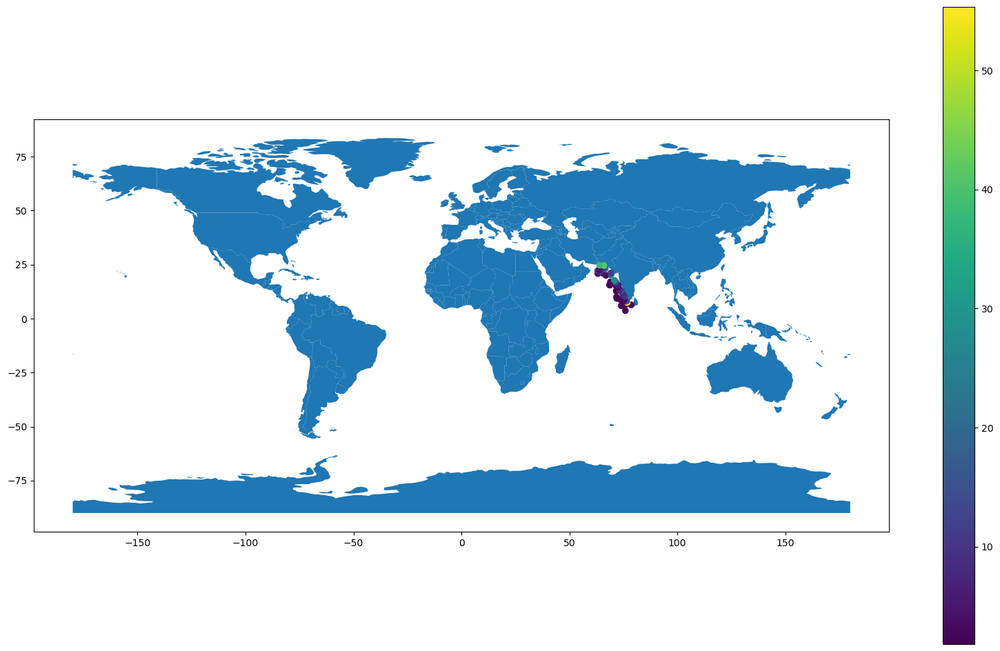

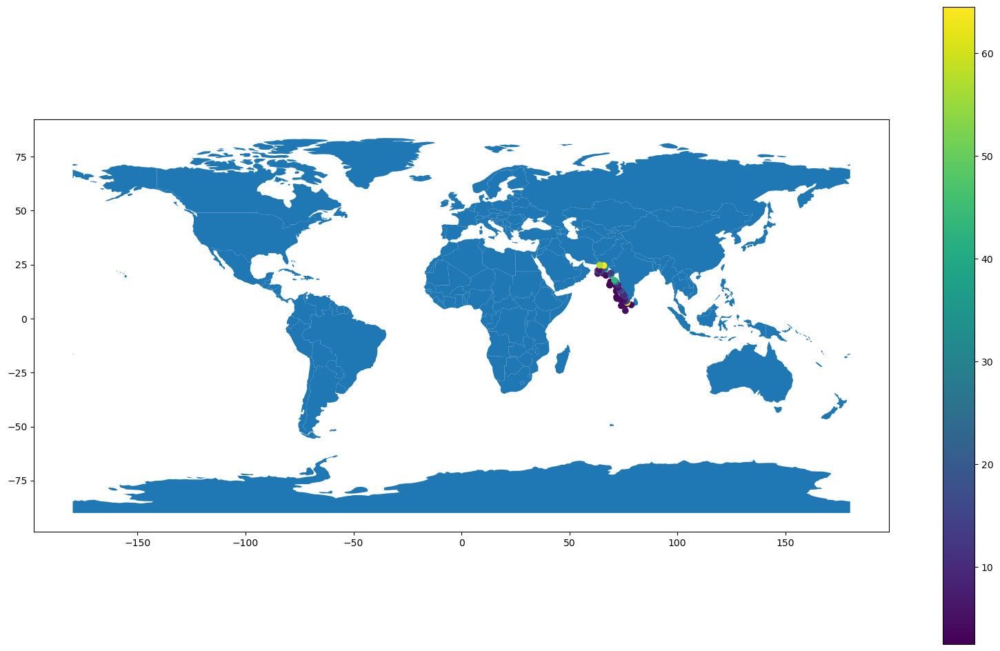

In [141]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_11['Longitude'], df_11['Latitude'])]
gdf_11 = GeoDataFrame(df_11, geometry=geometry)  
gdf_11.plot(ax = world.plot(figsize = (20, 12)), column = df_11["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_11['Longitude'], df_11['Latitude'])]
gdf_11 = GeoDataFrame(df_11, geometry=geometry)  
gdf_11.plot(ax = world.plot(figsize = (20, 12)), column = df_11["Sedimentation rate [cm/ka]"],legend = True);#"Sementation rate [cm/ka]"

df_11.describe()

### df_12

In [142]:
#data_path = Path().resolve().parents[3] / "work_old/work/toc-neural-nets/SelectFeaturesRun/pyfiles/" 
sedrate_labels_file12 = "sedRateData_oguri_et_al_2022.xlsx"

In [143]:
df_12 = pd.read_excel(Path(data_path / sedrate_labels_file12), sheet_name="Sheet1")

In [144]:
df_12

,Trench,Site,SR (mm y−1),MAR (g cm−2 y−1),Applied interval (cm),TOC (%)a,OCDR (gC m−2 y−1),MARmw (g cm−2 y−1)b,MARtot (g cm−2 y−1),Net primary productivity (gC m−2 y−1),Water depth (m),Latitude,Longitude,Core length (cm),Sampling equipment,Decimal Latitude,Decimal Longitude
0,Atacama,A1,0.74,0.037,0.5–9.5,2.32,8.6,–,–,449.0,2560,23° 48.72′S,70° 50.04′W,20,MUC,-23.8120,-70.8340
1,NaN,A1-E,0.53,0.028,0.5–7.5,2.32,6.4,–,–,449.0,2560,23° 48.72′S,70° 50.04′W,20,MUC,-23.8120,-70.8340
2,NaN,A9,0.33,0.018,6.5–9.5,1.01,1.8,–,–,342.0,4050,20° 19.97′S,70° 58.70′W,18,MUC,-20.3328,-70.9783
3,NaN,A7,0.65,0.024,0.5–9.5,0.67,1.6,–,–,308.0,5500,22° 56.22′S,71° 37.08′W,24,MUC,-22.9370,-71.6180
4,NaN,A10,0.29,0.012,2.5–6.5,0.94,1.2,–,–,306.0,7770,20° 19.14′S,71° 17.46′W,38,MUC,-20.3190,-71.2910
5,NaN,A2,0.29,0.028,3.5–5.5,0.39,1.1,–,–,306.0,7995,21° 46.86′S,71° 12.48′W,24,MUC,-21.7810,-71.2080
6,NaN,A2-E,0.45,0.042,0.5–4.5,0.39,1.6,0.033,0.07,306.0,7995,21° 46.86′S,71° 12.48′W,24,MUC,-21.7810,-71.2080
7,NaN,A3,0.79,0.093,5.5–9.5,0.57,5.3,–,–,341.0,7915,23° 02.94′S,71° 18.12′W,26,MUC,-23.0490,-71.3020
8,NaN,A4,0.56,0.055,0.5–6.5,0.58,3.2,0.015,0.07,335.0,8085,23° 21.78′S,71° 20.60′W,34,MUC,-23.3630,-71.3433
9,NaN,A4-E,0.67,0.062,0.5–6.5,0.58,3.6,0.013,0.08,335.0,8085,23° 21.78′S,71° 20.60′W,34,MUC,-23.3630,-71.3433


In [145]:
MAR_list = df_12["MAR (g\xa0cm−2\xa0y−1)"]
df_12 = df_12[["Decimal Latitude","Decimal Longitude","SR (mm\xa0y−1)"]]
df_12 = df_12[df_12["Decimal Longitude"]>-180]
df_12["SR (mm\xa0y−1)"] = df_12["SR (mm\xa0y−1)"]*100
df_12 = df_12.dropna(how="any")

In [146]:
df_12.columns

Index(['Decimal Latitude', 'Decimal Longitude', 'SR (mm y−1)'], dtype='object')

In [147]:
df_12 = df_12.rename(columns={
    "SR (mm\xa0y−1)": "Sedimentation rate [cm/ka]",
    "Decimal Latitude": "Latitude",
    "Decimal Longitude": "Longitude"
})
#df_8["Sedimentation rate [cm/ka]"] = df_8["Sedimentation rate [cm/ka]"]*100


In [148]:
import pandas as pd

# Group by Latitude and Longitude and filter groups with more than one entry
df_12 = df_12.groupby(['Latitude', 'Longitude']).filter(lambda x: len(x) > 0)

# Display the filtered DataFrame
print("Filtered DataFrame:")
print(df_12)

# Group the data by Latitude and Longitude and calculate the mean of each group
df_12 = df_12.groupby(['Latitude', 'Longitude'], as_index=False).mean()

# Display the resulting DataFrame with averaged locations
print("DataFrame after averaging:")
print(df_12)

Filtered DataFrame:
    Latitude  Longitude  Sedimentation rate [cm/ka]
0   -23.8120   -70.8340                        74.0
1   -23.8120   -70.8340                        53.0
2   -20.3328   -70.9783                        33.0
3   -22.9370   -71.6180                        65.0
4   -20.3190   -71.2910                        29.0
5   -21.7810   -71.2080                        29.0
6   -21.7810   -71.2080                        45.0
7   -23.0490   -71.3020                        79.0
8   -23.3630   -71.3433                        56.0
9   -23.3630   -71.3433                        67.0
10  -23.8170   -71.3720                        39.0
11  -23.8170   -71.3720                        51.0
12  -24.2660   -71.4230                        43.0
13  -24.2660   -71.4230                        45.0
14   45.8480   153.8000                        80.0
15   45.4792   153.1942                       179.0
16   44.6647   151.4685                        28.0
17   44.2065   150.6002                     

In [149]:
df_12

,Latitude,Longitude,Sedimentation rate [cm/ka]
0,-32.1870,-176.5610,31.0
1,-32.1488,-177.3985,39.0
2,-31.1402,-176.8080,30.0
3,-24.2660,-71.4230,44.0
4,-23.8170,-71.3720,45.0
5,-23.8120,-70.8340,63.5
6,-23.3630,-71.3433,61.5
7,-23.0490,-71.3020,79.0
8,-22.9370,-71.6180,65.0
9,-21.7810,-71.2080,37.0


In [150]:
"""
MAR_list = []
latitudes = np.linspace(-90, 90, 2161)      # from -90 to +90, every 0.1°
longitudes = np.linspace(-180, 180, 4321)   # from -180 to +180, every 0.1°
for idx, row in df_12.iterrows():
    lat, lon, sedrate = row["Latitude"], row["Longitude"], row["Sedimentation rate [cm/ka]"]
    lat_idx = find_nearest(lat, latitudes)
    lon_idx = find_nearest(lon, longitudes)
    porosity = int(dataset_numpy_porosity_graw[lat_idx, lon_idx])
    MAR = convertSR2MAR(sedrate, porosity, ds)
    MAR_list.append(MAR)
"""
# Add MAR to the DataFrame
df_12["MAR(g/cm**2/ka)"] = MAR_list
df_12["MAR(g/cm**2/ka)"] = df_12["MAR(g/cm**2/ka)"]*1e3

In [151]:
df_12.head(n=10)

,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,-32.1870,-176.5610,31.0,37.0
1,-32.1488,-177.3985,39.0,28.0
2,-31.1402,-176.8080,30.0,18.0
3,-24.2660,-71.4230,44.0,24.0
4,-23.8170,-71.3720,45.0,12.0
5,-23.8120,-70.8340,63.5,28.0
6,-23.3630,-71.3433,61.5,42.0
7,-23.0490,-71.3020,79.0,93.0
8,-22.9370,-71.6180,65.0,55.0
9,-21.7810,-71.2080,37.0,62.0


/tmp/ipykernel_3264220/946084608.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/946084608.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
count,17.000000,17.000000,17.000000,17.000000
mean,-6.328747,-24.743894,56.000000,39.529412
std,30.856597,123.043430,36.329654,22.564124
min,-32.187000,-177.398500,28.000000,12.000000
25%,-23.817000,-71.423000,33.000000,27.000000
50%,-22.937000,-71.291000,44.000000,36.000000
75%,11.365700,142.428000,65.000000,43.000000
max,45.848000,153.800000,179.000000,93.000000


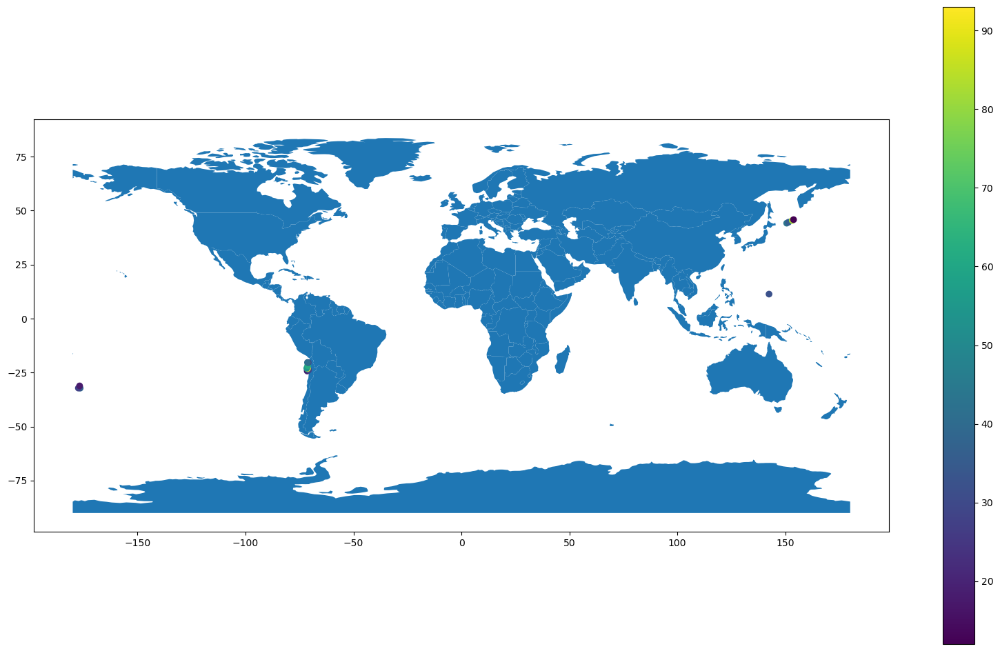

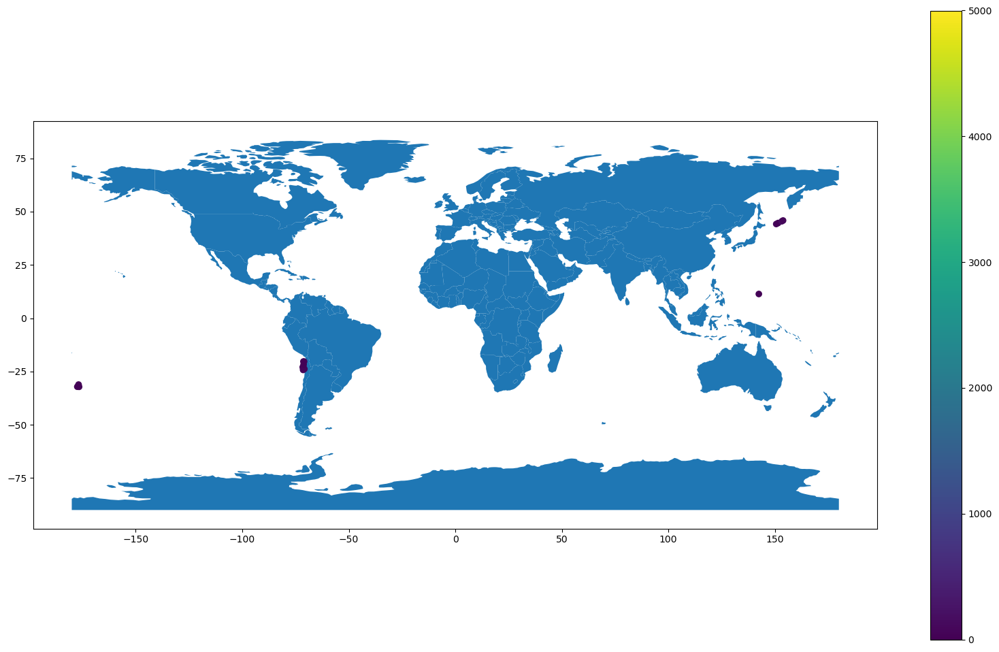

In [152]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_12['Longitude'], df_12['Latitude'])]
gdf_12 = GeoDataFrame(df_12, geometry=geometry)  
gdf_12.plot(ax = world.plot(figsize = (20, 12)), column = df_12["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_12['Longitude'], df_12['Latitude'])]
gdf_12 = GeoDataFrame(df_12, geometry=geometry)  
gdf_12.plot(ax = world.plot(figsize = (20, 12)), column = df_12["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 5000,legend = True);#"Sedimentation rate [cm/ka]"

df_12.describe()

### df_13

In [153]:
#data_path = Path().resolve().parents[3] / "work_old/work/toc-neural-nets/SelectFeaturesRun/pyfiles/" 
sedrate_labels_file13 = "sedRateData_Ferreira_et_al_2020.xlsx"

In [154]:
df_13 = pd.read_excel(Path(data_path / sedrate_labels_file13), sheet_name="Sheet3")

In [155]:
df_13

,Core,Latitude (°S),Longitude (°W),Water Depth (m),Sedimentation Rate (mm yr⁻¹),Sedimentation Rate (cm ka⁻¹),Unnamed: 6
0,6651,25.85,45.70,256,1.12 ± 0.08,112,1.12
1,6653,25.72,46.04,155,0.49 ± 0.01,49,0.49
2,6654,25.47,46.57,90,2.78 ± 0.20,278,2.78
3,6655,25.44,46.64,80,1.26 ± 0.09,126,1.26
4,6669,24.12,44.61,120,2.35 ± 0.19,235,2.35
5,6670,24.67,44.33,540,1.67 ± 0.12,167,1.67
6,6678,24.77,45.18,100,1.95 ± 0.13,195,1.95
7,6680,25.25,44.88,280,1.71 ± 0.10,171,1.71
8,6683,25.06,45.55,100,1.61 ± 0.12,161,1.61
9,6696,25.56,46.68,92,2.54 ± 0.18,254,2.54


In [156]:
df_13.columns

Index(['Core', 'Latitude (°S)', 'Longitude (°W)', 'Water Depth (m)',
       'Sedimentation Rate (mm yr⁻¹)', 'Sedimentation Rate (cm ka⁻¹)',
       'Unnamed: 6'],
      dtype='object')

In [157]:
df_13 = df_13[["Latitude (°S)","Longitude (°W)","Sedimentation Rate (cm ka⁻¹)"]]
df_13 = df_13[df_13["Longitude (°W)"]>-180]
df_13["Sedimentation Rate (cm ka⁻¹)"] = df_13["Sedimentation Rate (cm ka⁻¹)"]
df_13["Latitude (°S)"] = df_13["Latitude (°S)"]*-1
df_13["Longitude (°W)"] = df_13["Longitude (°W)"]*-1
df_13 = df_13.dropna(how="any")

In [158]:
df_13 = df_13.rename(columns={
    "Sedimentation Rate (cm ka⁻¹)": "Sedimentation rate [cm/ka]",
    "Latitude (°S)": "Latitude",
    "Longitude (°W)": "Longitude"
})
#df_8["Sedimentation rate [cm/ka]"] = df_8["Sedimentation rate [cm/ka]"]*100


In [159]:
import pandas as pd

# Group by Latitude and Longitude and filter groups with more than one entry
df_13 = df_13.groupby(['Latitude', 'Longitude']).filter(lambda x: len(x) > 0)

# Display the filtered DataFrame
print("Filtered DataFrame:")
print(df_13)

# Group the data by Latitude and Longitude and calculate the mean of each group
df_13 = df_13.groupby(['Latitude', 'Longitude'], as_index=False).mean()

# Display the resulting DataFrame with averaged locations
print("DataFrame after averaging:")
print(df_13)

Filtered DataFrame:
    Latitude  Longitude  Sedimentation rate [cm/ka]
0     -25.85     -45.70                         112
1     -25.72     -46.04                          49
2     -25.47     -46.57                         278
3     -25.44     -46.64                         126
4     -24.12     -44.61                         235
5     -24.67     -44.33                         167
6     -24.77     -45.18                         195
7     -25.25     -44.88                         171
8     -25.06     -45.55                         161
9     -25.56     -46.68                         254
10    -25.41     -46.37                         191
11    -25.24     -46.05                         373
12    -23.76     -44.06                         256
13    -23.44     -43.46                         181
14    -23.33     -42.85                         239
15    -23.95     -43.98                         117
DataFrame after averaging:
    Latitude  Longitude  Sedimentation rate [cm/ka]
0     -25.85     

In [160]:
df_13

,Latitude,Longitude,Sedimentation rate [cm/ka]
0,-25.85,-45.70,112.0
1,-25.72,-46.04,49.0
2,-25.56,-46.68,254.0
3,-25.47,-46.57,278.0
4,-25.44,-46.64,126.0
5,-25.41,-46.37,191.0
6,-25.25,-44.88,171.0
7,-25.24,-46.05,373.0
8,-25.06,-45.55,161.0
9,-24.77,-45.18,195.0


In [161]:
MAR_list = []
latitudes = np.linspace(-90, 90, 2161)      # from -90 to +90, every 0.1°
longitudes = np.linspace(-180, 180, 4321)   # from -180 to +180, every 0.1°
for idx, row in df_13.iterrows():
    lat, lon, sedrate = row["Latitude"], row["Longitude"], row["Sedimentation rate [cm/ka]"]
    lat_idx = find_nearest(lat, latitudes)
    lon_idx = find_nearest(lon, longitudes)
    porosity = int(dataset_numpy_porosity_graw[lat_idx, lon_idx])
    MAR = convertSR2MAR(sedrate, porosity, ds)
    MAR_list.append(MAR)

# Add MAR to the DataFrame
df_13["MAR(g/cm**2/ka)"] = MAR_list

In [162]:
df_13.head(n=10)

,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,-25.85,-45.70,112.0,119.392
1,-25.72,-46.04,49.0,53.508
2,-25.56,-46.68,254.0,277.368
3,-25.47,-46.57,278.0,303.576
4,-25.44,-46.64,126.0,144.144
5,-25.41,-46.37,191.0,203.606
6,-25.25,-44.88,171.0,182.286
7,-25.24,-46.05,373.0,397.618
8,-25.06,-45.55,161.0,175.812
9,-24.77,-45.18,195.0,212.940


/tmp/ipykernel_3264220/4178062987.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/4178062987.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
count,16.000000,16.000000,16.000000,16.000000
mean,-24.815000,-45.184375,194.062500,212.840875
std,0.837138,1.206991,77.920873,84.771439
min,-25.850000,-46.680000,49.000000,53.508000
25%,-25.447500,-46.130000,152.250000,167.895000
50%,-25.150000,-45.365000,186.000000,205.335000
75%,-24.077500,-44.262500,242.750000,274.404000
max,-23.330000,-42.850000,373.000000,397.618000


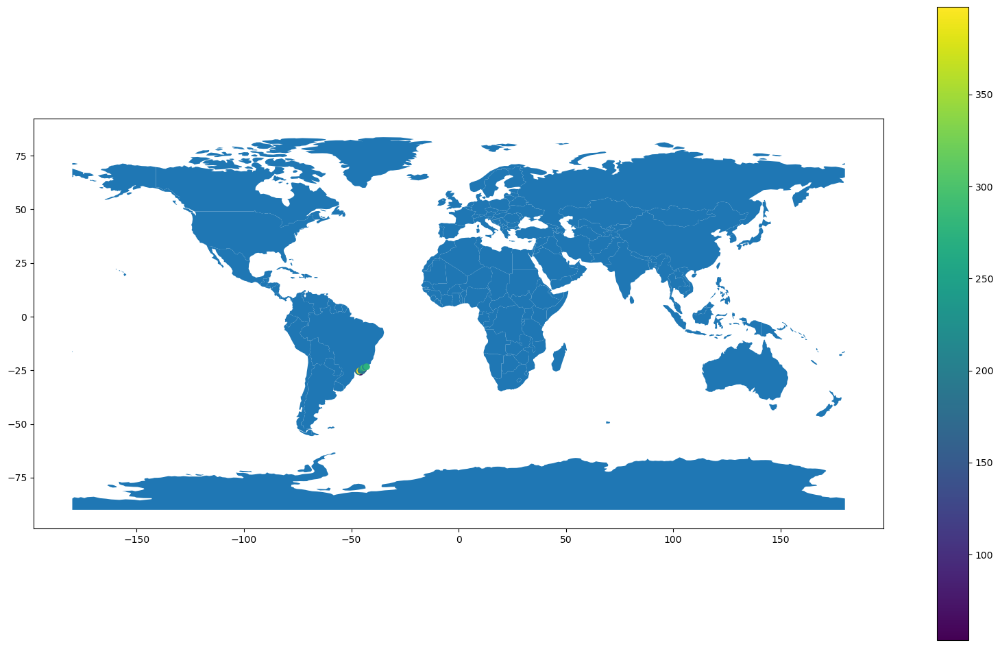

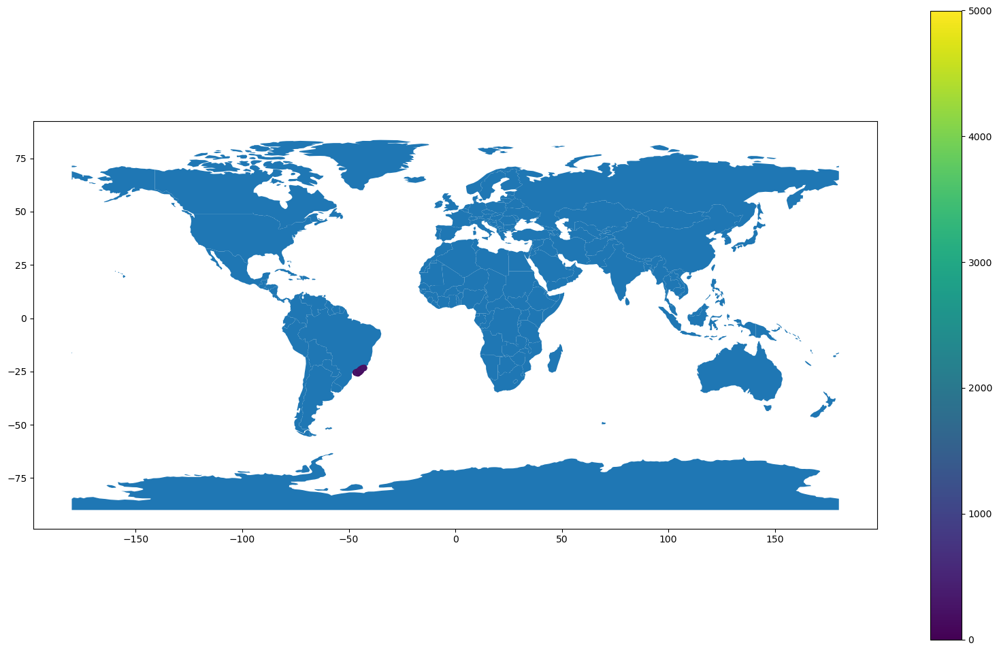

In [163]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_13['Longitude'], df_13['Latitude'])]
gdf_13 = GeoDataFrame(df_13, geometry=geometry)  
gdf_13.plot(ax = world.plot(figsize = (20, 12)), column = df_13["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_13['Longitude'], df_13['Latitude'])]
gdf_13 = GeoDataFrame(df_13, geometry=geometry)  
gdf_13.plot(ax = world.plot(figsize = (20, 12)), column = df_13["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 5000,legend = True);#"Sedimentation rate [cm/ka]"

df_13.describe()

### df_14

In [164]:
#data_path = Path().resolve().parents[3] / "work_old/work/toc-neural-nets/SelectFeaturesRun/pyfiles/" 
sedrate_labels_file14 = "sedRateData_Mollenhauer_et_al_2002.xlsx"

In [165]:
df_14 = pd.read_excel(Path(data_path / sedrate_labels_file14), sheet_name="Sheet3")

In [166]:
df_14

,Core,Latitude (°N),Longitude (°E),Mean TOC (%),Sedimentation Rate (cm kyr⁻¹),Reference
0,GeoB1704-4,-19.407,11.612,1.7,8.0,this study
1,GeoB1705-1,-19.505,11.398,3.5,13.1,"Little et al. [1997, this study]"
2,GeoB1706-2,-19.562,11.175,5.8,9.0,this study
3,GeoB1707-1,-19.690,10.657,5.1,9.4,this study
4,GeoB1028-5,-20.104,9.186,1.2,5.0,"Müller et al. [15], Jahn et al. manuscript, Mo..."
5,ODP 175-1082A,-21.094,11.821,5.5,12.3,this study
6,226920-3,-22.449,12.358,6.4,16.0,Mollenhauer et al.
7,GeoB1710-3,-23.432,11.698,2.7,5.3,Kirst et al. [1999]
8,GeoB1711-4,-23.315,12.377,5.4,10.0,Kirst et al. [1999]
9,GeoB1712-4,-23.257,12.808,6.8,8.0,Kirst et al. [1999]


In [167]:
df_14 = df_14[["Latitude (°N)","Longitude (°E)","Sedimentation Rate (cm kyr⁻¹)"]]
df_14 = df_14[df_14["Longitude (°E)"]>-180]
#df_14["Sedimentation rate (cm/ka)"] = df_14["Sedimentation rate (cm/ka)"]*1000
df_14 = df_14.dropna(how="any")

In [168]:
df_14 = df_14.rename(columns={
    "Sedimentation Rate (cm kyr⁻¹)": "Sedimentation rate [cm/ka]",
    "Latitude (°N)": "Latitude",
    "Longitude (°E)": "Longitude"
})
#df_8["Sedimentation rate [cm/ka]"] = df_8["Sedimentation rate [cm/ka]"]*100


In [169]:
import pandas as pd

# Group by Latitude and Longitude and filter groups with more than one entry
df_14 = df_14.groupby(['Latitude', 'Longitude']).filter(lambda x: len(x) > 0)

# Display the filtered DataFrame
print("Filtered DataFrame:")
print(df_14)

# Group the data by Latitude and Longitude and calculate the mean of each group
df_14 = df_14.groupby(['Latitude', 'Longitude'], as_index=False).mean()

# Display the resulting DataFrame with averaged locations
print("DataFrame after averaging:")
print(df_14)

Filtered DataFrame:
    Latitude  Longitude  Sedimentation rate [cm/ka]
0    -19.407     11.612                         8.0
1    -19.505     11.398                        13.1
2    -19.562     11.175                         9.0
3    -19.690     10.657                         9.4
4    -20.104      9.186                         5.0
5    -21.094     11.821                        12.3
6    -22.449     12.358                        16.0
7    -23.432     11.698                         5.3
8    -23.315     12.377                        10.0
9    -23.257     12.808                         8.0
10   -24.895     13.161                         7.7
11   -25.068     12.666                        10.5
12   -25.250     12.021                         5.2
13   -25.467     13.083                        18.0
14   -25.514     13.028                        24.1
15   -28.927     14.178                         6.5
16   -29.000     13.828                         4.0
17   -29.168     13.082                     

In [170]:
df_14

,Latitude,Longitude,Sedimentation rate [cm/ka]
0,-29.450,11.750,1.9
1,-29.168,13.082,2.9
2,-29.000,13.828,4.0
3,-28.927,14.178,6.5
4,-25.514,13.028,24.1
5,-25.467,13.083,18.0
6,-25.250,12.021,5.2
7,-25.068,12.666,10.5
8,-24.895,13.161,7.7
9,-23.888,14.333,60.0


In [171]:
MAR_list = []
latitudes = np.linspace(-90, 90, 2161)      # from -90 to +90, every 0.1°
longitudes = np.linspace(-180, 180, 4321)   # from -180 to +180, every 0.1°
for idx, row in df_14.iterrows():
    lat, lon, sedrate = row["Latitude"], row["Longitude"], row["Sedimentation rate [cm/ka]"]
    lat_idx = find_nearest(lat, latitudes)
    lon_idx = find_nearest(lon, longitudes)
    porosity = int(dataset_numpy_porosity_graw[lat_idx, lon_idx])
    MAR = convertSR2MAR(sedrate, porosity, ds)
    MAR_list.append(MAR)

# Add MAR to the DataFrame
df_14["MAR(g/cm**2/ka)"] = MAR_list

In [172]:
df_14.head(n=10)

,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,-29.450,11.750,1.9,1.3338
1,-29.168,13.082,2.9,2.1112
2,-29.000,13.828,4.0,2.8080
3,-28.927,14.178,6.5,4.7320
4,-25.514,13.028,24.1,13.7852
5,-25.467,13.083,18.0,10.7640
6,-25.250,12.021,5.2,3.5152
7,-25.068,12.666,10.5,6.5520
8,-24.895,13.161,7.7,4.6046
9,-23.888,14.333,60.0,59.2800


/tmp/ipykernel_3264220/182985890.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/182985890.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
count,21.000000,21.000000,21.000000,21.000000
mean,-23.862333,12.407286,19.185714,15.922895
std,3.331454,1.278760,35.796009,35.997129
min,-29.450000,9.186000,1.900000,1.333800
25%,-25.467000,11.698000,5.300000,3.582800
50%,-23.432000,12.377000,9.000000,5.382000
75%,-21.094000,13.083000,13.100000,8.855600
max,-19.407000,14.333000,166.000000,164.008000


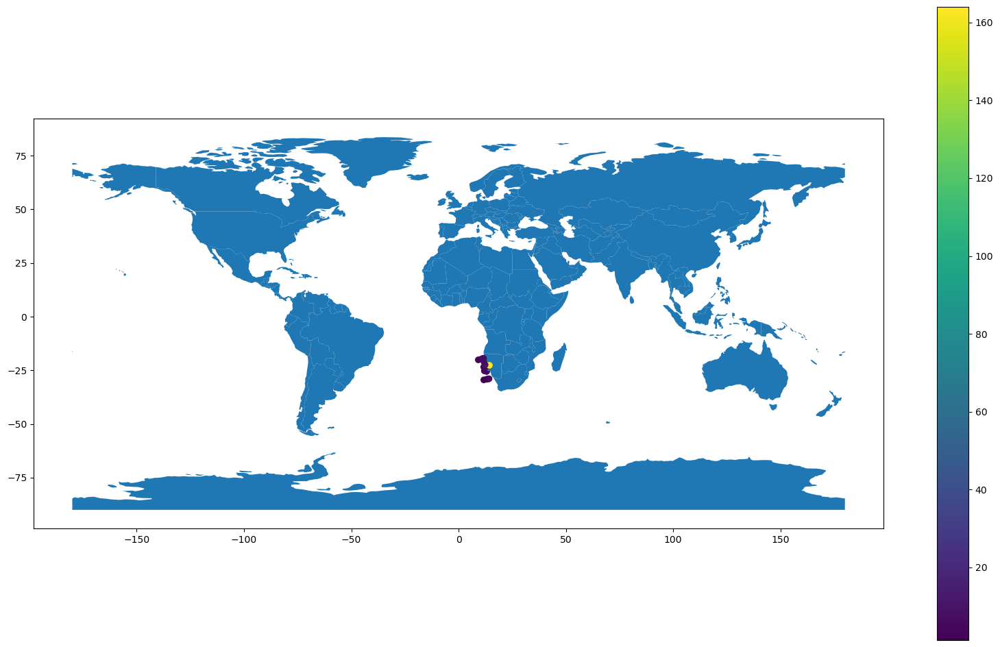

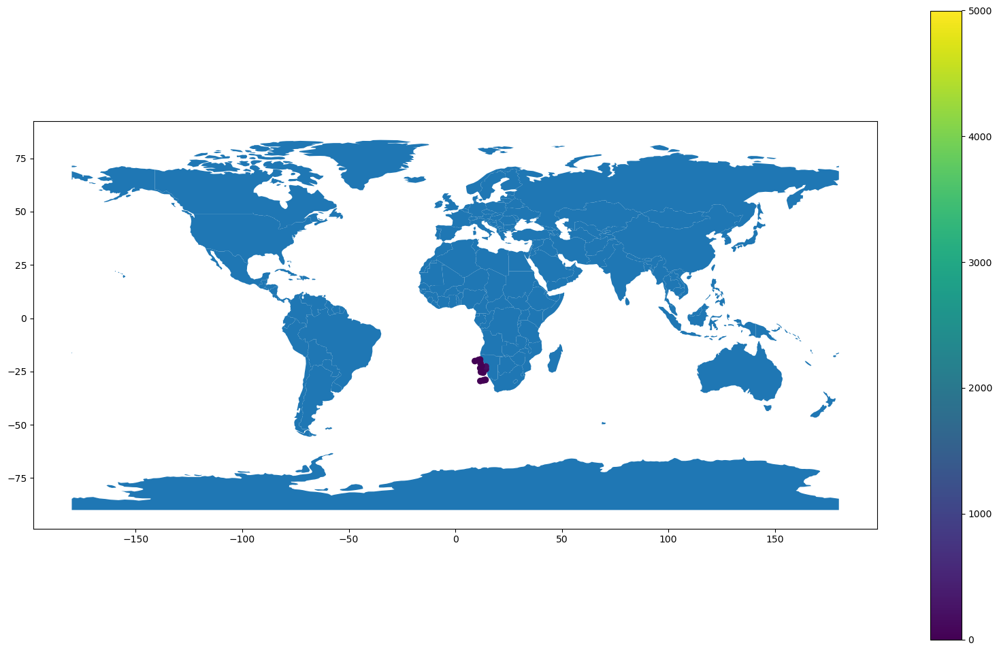

In [173]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_14['Longitude'], df_14['Latitude'])]
gdf_14 = GeoDataFrame(df_14, geometry=geometry)  
gdf_14.plot(ax = world.plot(figsize = (20, 12)), column = df_14["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_14['Longitude'], df_14['Latitude'])]
gdf_14 = GeoDataFrame(df_14, geometry=geometry)  
gdf_14.plot(ax = world.plot(figsize = (20, 12)), column = df_14["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 5000,legend = True);#"Sedimentation rate [cm/ka]"

df_14.describe()

### df_15

In [174]:
#data_path = Path().resolve().parents[3] / "work_old/work/toc-neural-nets/SelectFeaturesRun/pyfiles/" 
sedrate_labels_file15 = "combined_mar_points_wegner_2015.csv"

In [175]:
df_15 = pd.read_csv(Path(data_path / sedrate_labels_file15), sep= ",")

In [176]:
df_15

,lat,lon,SR(cm/ka),MAR(g/cm2/yr)
0,81.857694,52.093297,4.0,NaN
1,81.857694,53.093297,4.0,NaN
2,81.857694,54.093297,4.0,NaN
3,81.857694,55.093297,4.0,NaN
4,82.857694,56.093297,4.0,NaN
...,...,...,...,...
424,76.570092,79.677574,150.0,NaN
425,77.186109,96.633167,150.0,NaN
426,77.186109,97.633167,150.0,NaN
427,77.186109,98.633167,150.0,NaN


In [177]:
#df_6 = df_6[["lat","lon","SR"]]

In [178]:
#"""
df_15 = df_15[["lat","lon","SR(cm/ka)"]]
df_15 = df_15[df_15["lon"]>-180]
df_15 = df_15[df_15["lon"]<180]
df_15 = df_15[df_15["lat"]>-90]
df_15 = df_15[df_15["lat"]<90]
#df_15["Sedimentation rate (cm/yr)"] = df_15["Sedimentation rate (cm/yr)"]*1e3
df_15 = df_15.dropna(how="any")
#"""

In [179]:

df_15 = df_15.rename(columns={
    "SR(cm/ka)": "Sedimentation rate [cm/ka]", 
    "lat": "Latitude", 
    "lon" : "Longitude"
})
#df_6["Sedimentation rate [cm/ka]"] = df_6["Sedimentation rate [cm/ka]"]*1e3


In [180]:
df_15

,Latitude,Longitude,Sedimentation rate [cm/ka]
0,81.857694,52.093297,4.0
1,81.857694,53.093297,4.0
2,81.857694,54.093297,4.0
3,81.857694,55.093297,4.0
4,82.857694,56.093297,4.0
...,...,...,...
424,76.570092,79.677574,150.0
425,77.186109,96.633167,150.0
426,77.186109,97.633167,150.0
427,77.186109,98.633167,150.0


In [181]:
import pandas as pd

# Group by Latitude and Longitude and filter groups with more than one entry
df_15 = df_15.groupby(['Latitude', 'Longitude']).filter(lambda x: len(x) > 0)

# Display the filtered DataFrame
print("Filtered DataFrame:")
print(df_15)

# Group the data by Latitude and Longitude and calculate the mean of each group
df_15 = df_15.groupby(['Latitude', 'Longitude'], as_index=False).mean()

# Display the resulting DataFrame with averaged locations
print("DataFrame after averaging:")
print(df_15)

Filtered DataFrame:
      Latitude  Longitude  Sedimentation rate [cm/ka]
0    81.857694  52.093297                         4.0
1    81.857694  53.093297                         4.0
2    81.857694  54.093297                         4.0
3    81.857694  55.093297                         4.0
4    82.857694  56.093297                         4.0
..         ...        ...                         ...
424  76.570092  79.677574                       150.0
425  77.186109  96.633167                       150.0
426  77.186109  97.633167                       150.0
427  77.186109  98.633167                       150.0
428  77.186109  99.633167                       150.0

[141 rows x 3 columns]
DataFrame after averaging:
      Latitude   Longitude  Sedimentation rate [cm/ka]
0    69.981915 -143.758094                       150.0
1    69.981915 -140.758094                       150.0
2    69.981915 -139.758094                       150.0
3    69.981915 -138.758094                       150.0
4    6

In [182]:
#df_15["Longitude"].max()

In [183]:
MAR_list = []
latitudes = np.linspace(-90, 90, 2161)      # from -90 to +90, every 0.1°
longitudes = np.linspace(-180, 180, 4321)   # from -180 to +180, every 0.1°
for idx, row in df_15.iterrows():
    lat, lon, sedrate = row["Latitude"], row["Longitude"], row["Sedimentation rate [cm/ka]"]
    lat_idx = find_nearest(lat, latitudes)
    lon_idx = find_nearest(lon, longitudes)
    porosity = int(dataset_numpy_porosity_graw[lat_idx, lon_idx])
    MAR = convertSR2MAR(sedrate, porosity, ds)
    MAR_list.append(MAR)

# Add MAR to the DataFrame
df_15["MAR(g/cm**2/ka)"] = MAR_list

In [184]:
df_15.head(n=10)

,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,69.981915,-143.758094,150.0,144.3
1,69.981915,-140.758094,150.0,148.2
2,69.981915,-139.758094,150.0,148.2
3,69.981915,-138.758094,150.0,140.4
4,69.981915,-137.758094,150.0,97.5
5,69.981915,-136.758094,150.0,97.5
6,69.981915,-135.758094,150.0,97.5
7,69.981915,-134.758094,150.0,97.5
8,69.981915,-133.758094,150.0,97.5
9,69.981915,-132.758094,150.0,97.5


/tmp/ipykernel_3264220/728461442.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/728461442.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
count,141.000000,141.000000,141.000000,141.000000
mean,81.802241,-4.748093,31.812057,28.184498
std,5.457460,129.777029,59.064074,53.662338
min,69.981915,-169.804743,0.300000,0.202800
25%,77.857694,-142.804743,0.300000,0.226200
50%,84.857694,63.093297,4.000000,2.808000
75%,86.697003,96.093297,4.000000,3.952000
max,86.697003,179.093297,150.000000,156.000000


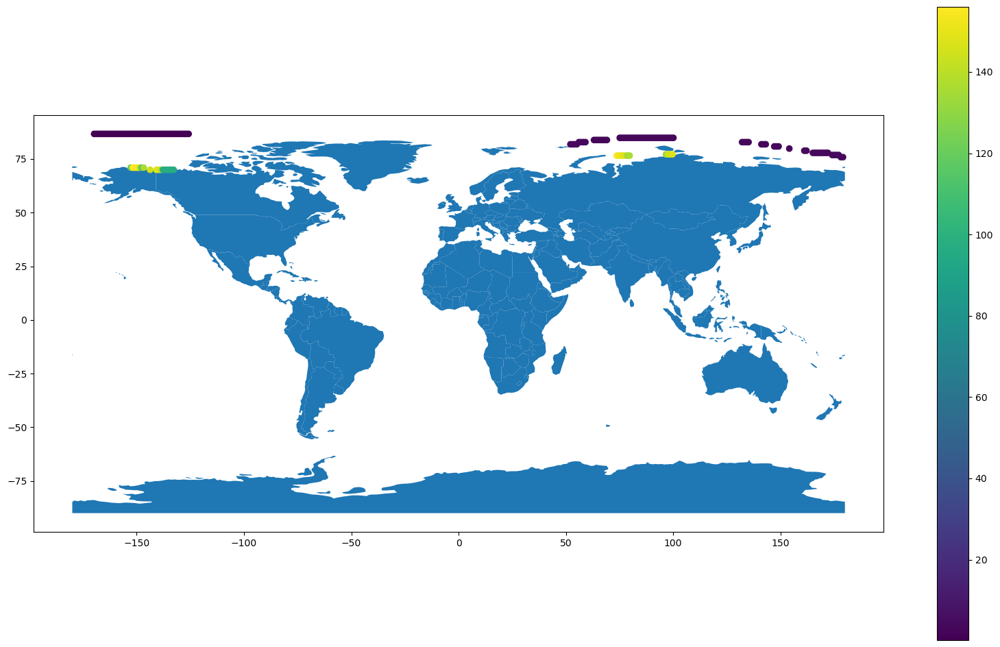

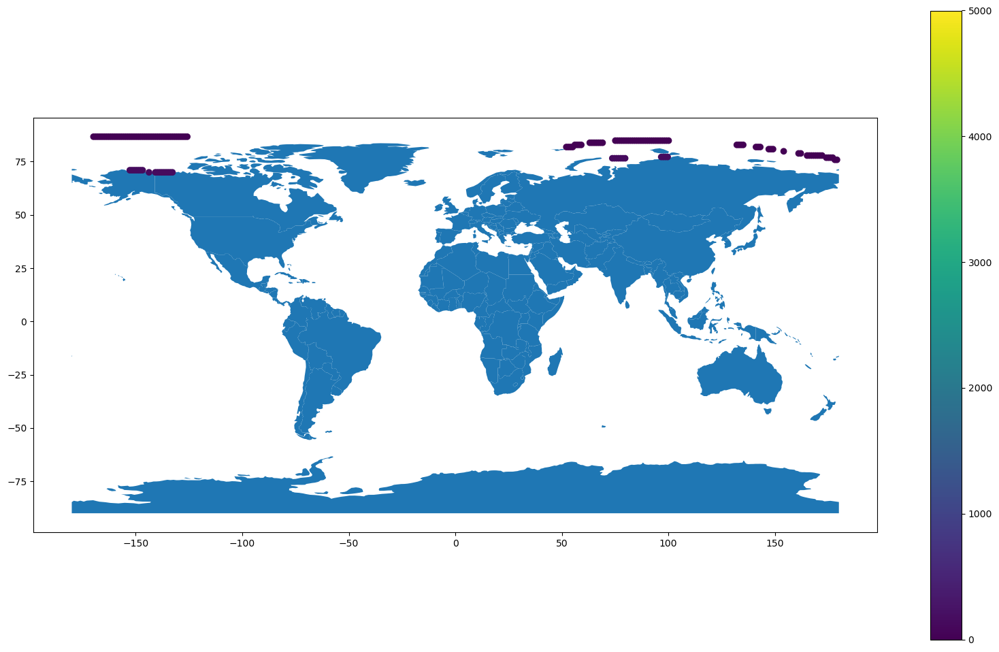

In [185]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_15['Longitude'], df_15['Latitude'])]
gdf_15 = GeoDataFrame(df_15, geometry=geometry)  
gdf_15.plot(ax = world.plot(figsize = (20, 12)), column = df_15["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_15['Longitude'], df_15['Latitude'])]
gdf_15 = GeoDataFrame(df_15, geometry=geometry)  
gdf_15.plot(ax = world.plot(figsize = (20, 12)), column = df_15["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 5000,legend = True);#"Sedimentation rate [cm/ka]"

df_15.describe()

### df_16

In [186]:
#data_path = Path().resolve().parents[3] / "work_old/work/toc-neural-nets/SelectFeaturesRun/pyfiles/" 
sedrate_labels_file16 = "combined_mar_points_deng_2006_filtered.csv"

In [187]:
df_16 = pd.read_csv(Path(data_path / sedrate_labels_file16), sep= ",")

In [188]:
df_16

,lat,lon,MAR(g/cm2/yr)
0,25.465101,121.002201,0.01
1,25.548434,121.002201,0.01
2,25.381767,121.085534,0.01
3,25.465101,121.085534,0.01
4,25.548434,121.085534,0.01
...,...,...,...
6546,29.922902,123.503601,0.75
6547,30.006236,123.503601,0.75
6548,30.089569,123.503601,0.75
6549,29.839569,123.586934,0.75


In [189]:
#df_6 = df_6[["lat","lon","SR"]]

In [190]:
#"""
df_16 = df_16[["lat","lon","MAR(g/cm2/yr)"]]
df_16 = df_16[df_16["lon"]>-180]
df_16 = df_16[df_16["lon"]<180]
df_16["MAR(g/cm2/yr)"] = df_16["MAR(g/cm2/yr)"]*1000
#df_16["Sedimentation rate (cm/yr)"] = df_16["Sedimentation rate (cm/yr)"]*1e3
df_16 = df_16.dropna(how="any")
#"""

In [191]:

df_16 = df_16.rename(columns={
    "MAR(g/cm2/yr)": "MAR(g/cm**2/ka)", 
    "lat": "Latitude", 
    "lon" : "Longitude"
})
#df_6["Sedimentation rate [cm/ka]"] = df_6["Sedimentation rate [cm/ka]"]*1e3


In [192]:
df_16

,Latitude,Longitude,MAR(g/cm**2/ka)
0,25.465101,121.002201,10.0
1,25.548434,121.002201,10.0
2,25.381767,121.085534,10.0
3,25.465101,121.085534,10.0
4,25.548434,121.085534,10.0
...,...,...,...
6546,29.922902,123.503601,750.0
6547,30.006236,123.503601,750.0
6548,30.089569,123.503601,750.0
6549,29.839569,123.586934,750.0


In [193]:
import pandas as pd

# Group by Latitude and Longitude and filter groups with more than one entry
df_16 = df_16.groupby(['Latitude', 'Longitude']).filter(lambda x: len(x) > 0)

# Display the filtered DataFrame
print("Filtered DataFrame:")
print(df_16)

# Group the data by Latitude and Longitude and calculate the mean of each group
df_16 = df_16.groupby(['Latitude', 'Longitude'], as_index=False).mean()

# Display the resulting DataFrame with averaged locations
print("DataFrame after averaging:")
print(df_16)

Filtered DataFrame:
       Latitude   Longitude  MAR(g/cm**2/ka)
0     25.465101  121.002201             10.0
1     25.548434  121.002201             10.0
2     25.381767  121.085534             10.0
3     25.465101  121.085534             10.0
4     25.548434  121.085534             10.0
...         ...         ...              ...
6546  29.922902  123.503601            750.0
6547  30.006236  123.503601            750.0
6548  30.089569  123.503601            750.0
6549  29.839569  123.586934            750.0
6550  29.922902  123.586934            750.0

[6551 rows x 3 columns]
DataFrame after averaging:
       Latitude   Longitude  MAR(g/cm**2/ka)
0     25.131767  121.252201             10.0
1     25.131767  121.335534             10.0
2     25.131767  121.418867             10.0
3     25.135678  121.171608            350.0
4     25.135678  121.921608            350.0
...         ...         ...              ...
3870  32.052345  124.421608            350.0
3871  32.052345  124.504941 

In [194]:
#df_15["Longitude"].max()

In [195]:
latitudes = np.linspace(-90, 90, 2161)      # from -90 to +90, every 0.1°
longitudes = np.linspace(-180, 180, 4321)   # from -180 to +180, every 0.1°
sedrate_list = []

for idx, row in df_16.iterrows():
    lat, lon, MAR = row["Latitude"], row["Longitude"], row["MAR(g/cm**2/ka)"]
    lat_idx = find_nearest(lat, latitudes)
    lon_idx = find_nearest(lon, longitudes)
    porosity = int(dataset_numpy_porosity_graw[lat_idx, lon_idx])
    sedrate = convertMAR2SR(MAR, porosity, ds)
    sedrate_list.append(sedrate)

df_16["Sedimentation rate [cm/ka]"] = sedrate_list

In [196]:
df_16.head(n=10)

,Latitude,Longitude,MAR(g/cm**2/ka),Sedimentation rate [cm/ka]
0,25.131767,121.252201,10.0,13.262599
1,25.131767,121.335534,10.0,12.820513
2,25.131767,121.418867,10.0,12.820513
3,25.135678,121.171608,350.0,464.190981
4,25.135678,121.921608,350.0,517.751479
5,25.135678,122.004941,350.0,560.897436
6,25.135678,122.088274,350.0,560.897436
7,25.135678,122.171608,350.0,560.897436
8,25.135678,122.254941,350.0,560.897436
9,25.215101,121.252201,10.0,14.245014


/tmp/ipykernel_3264220/699697184.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/699697184.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,MAR(g/cm**2/ka),Sedimentation rate [cm/ka]
count,3875.000000,3875.000000,3875.000000,3875.000000
mean,28.290526,123.632035,231.123441,386.362390
std,1.664055,1.570879,385.215278,661.492762
min,25.131767,120.336934,10.000000,12.406948
25%,26.965101,122.466268,10.000000,15.384615
50%,28.215101,123.502201,10.000000,16.025641
75%,29.465101,124.668867,350.000000,585.284281
max,32.135678,127.668867,1450.000000,2788.461538


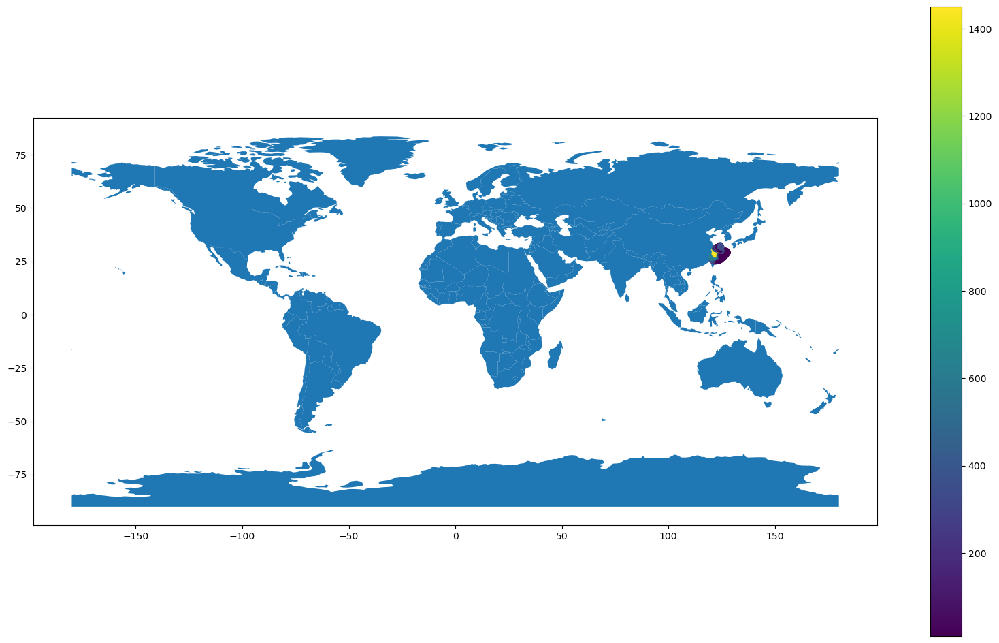

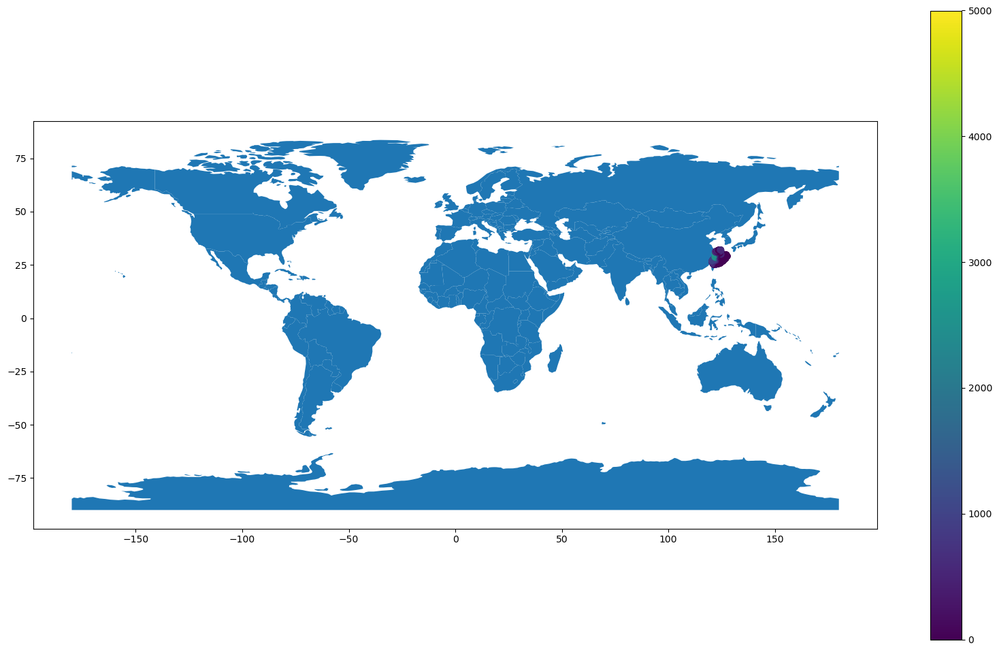

In [197]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_16['Longitude'], df_16['Latitude'])]
gdf_16 = GeoDataFrame(df_16, geometry=geometry)  
gdf_16.plot(ax = world.plot(figsize = (20, 12)), column = df_16["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_16['Longitude'], df_16['Latitude'])]
gdf_16 = GeoDataFrame(df_16, geometry=geometry)  
gdf_16.plot(ax = world.plot(figsize = (20, 12)), column = df_16["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 5000,legend = True);#"Sedimentation rate [cm/ka]"

df_16.describe()

### df_17

In [198]:
#data_path = Path().resolve().parents[3] / "work_old/work/toc-neural-nets/SelectFeaturesRun/pyfiles/" 
sedrate_labels_file17 = "south_china_sea_sheng_et_al_2024.csv"

In [199]:
df_17 = pd.read_csv(Path(data_path / sedrate_labels_file17), sep= ",")

In [200]:
df_17["SR(cm/ka)"][6508]+2

32.39

In [201]:
#df_6 = df_6[["lat","lon","SR"]]

In [202]:
#"""
df_17 = df_17[["lat","lon","SR(cm/ka)"]]
df_17 = df_17[df_17["lon"]>-180]
df_17 = df_17[df_17["lon"]<180]
df_17 = df_17[df_17["lat"]>-90]
df_17 = df_17[df_17["lat"]<90]
#df_17["SR(cm/ka)"] = float(df_17["SR(cm/ka)"])#*1e3
df_17 = df_17.dropna(how="any")
#"""

In [203]:

df_17 = df_17.rename(columns={
    "SR(cm/ka)": "Sedimentation rate [cm/ka]", 
    "lat": "Latitude", 
    "lon" : "Longitude"
})
#df_6["Sedimentation rate [cm/ka]"] = df_6["Sedimentation rate [cm/ka]"]*1e3


In [204]:
df_17

,Latitude,Longitude,Sedimentation rate [cm/ka]
0,17.544097,117.304687,300.0
1,17.627431,117.304687,300.0
2,17.710764,117.304687,300.0
3,17.794097,117.304687,300.0
4,17.460764,117.388020,300.0
...,...,...,...
9079,30.436199,122.812249,800.0
9080,30.186199,122.895582,800.0
9081,30.269533,122.895582,800.0
9082,30.352866,122.895582,800.0


In [205]:
import pandas as pd

# Group by Latitude and Longitude and filter groups with more than one entry
df_17 = df_17.groupby(['Latitude', 'Longitude']).filter(lambda x: len(x) > 0)

# Display the filtered DataFrame
print("Filtered DataFrame:")
print(df_17)

# Group the data by Latitude and Longitude and calculate the mean of each group
df_17 = df_17.groupby(['Latitude', 'Longitude'], as_index=False).mean()

# Display the resulting DataFrame with averaged locations
print("DataFrame after averaging:")
print(df_17)

Filtered DataFrame:
       Latitude   Longitude  Sedimentation rate [cm/ka]
0     17.544097  117.304687                       300.0
1     17.627431  117.304687                       300.0
2     17.710764  117.304687                       300.0
3     17.794097  117.304687                       300.0
4     17.460764  117.388020                       300.0
...         ...         ...                         ...
9079  30.436199  122.812249                       800.0
9080  30.186199  122.895582                       800.0
9081  30.269533  122.895582                       800.0
9082  30.352866  122.895582                       800.0
9083  30.269533  122.978916                       800.0

[9084 rows x 3 columns]
DataFrame after averaging:
       Latitude   Longitude  Sedimentation rate [cm/ka]
0      2.134835  107.388493                       200.0
1      2.134835  107.471826                       200.0
2      2.134835  107.555159                       200.0
3      2.134835  107.638493     

In [206]:
#df_15["Longitude"].max()

In [207]:
MAR_list = []
latitudes = np.linspace(-90, 90, 2161)      # from -90 to +90, every 0.1°
longitudes = np.linspace(-180, 180, 4321)   # from -180 to +180, every 0.1°
for idx, row in df_17.iterrows():
    lat, lon, sedrate = row["Latitude"], row["Longitude"], row["Sedimentation rate [cm/ka]"]
    lat_idx = find_nearest(lat, latitudes)
    lon_idx = find_nearest(lon, longitudes)
    porosity = int(dataset_numpy_porosity_graw[lat_idx, lon_idx])
    MAR = convertSR2MAR(sedrate, porosity, ds)
    MAR_list.append(MAR)

# Add MAR to the DataFrame
df_17["MAR(g/cm**2/ka)"] = MAR_list

In [208]:
df_17.head(n=10)

,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,2.134835,107.388493,200.0,140.4
1,2.134835,107.471826,200.0,145.6
2,2.134835,107.555159,200.0,145.6
3,2.134835,107.638493,200.0,145.6
4,2.134835,107.721826,200.0,140.4
5,2.134835,107.805159,200.0,140.4
6,2.134835,107.888493,200.0,140.4
7,2.134835,107.971826,200.0,140.4
8,2.134835,108.055159,200.0,140.4
9,2.214146,106.834530,300.0,218.4


/tmp/ipykernel_3264220/3554128477.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/3554128477.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
count,9081.000000,9081.000000,9081.000000,9081.000000
mean,18.422162,114.567509,297.742356,186.499921
std,8.662922,8.152244,343.366984,205.876902
min,2.134835,100.091865,0.660000,0.418600
25%,10.142552,105.534214,200.000000,119.600000
50%,19.238065,117.078739,200.000000,135.200000
75%,26.302345,121.838274,300.000000,195.000000
max,39.363032,127.505308,5000.000000,3640.000000


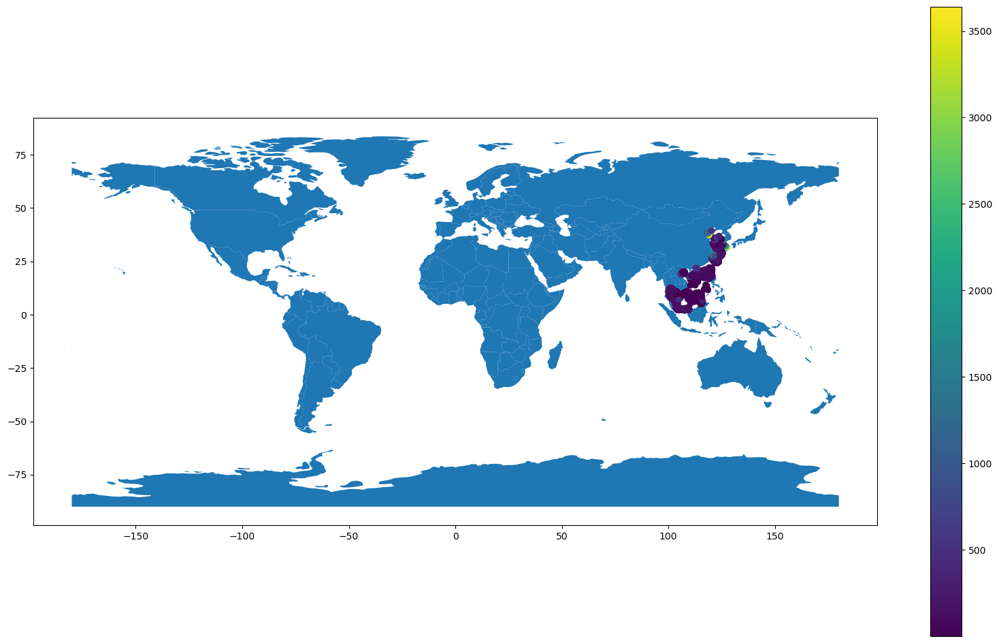

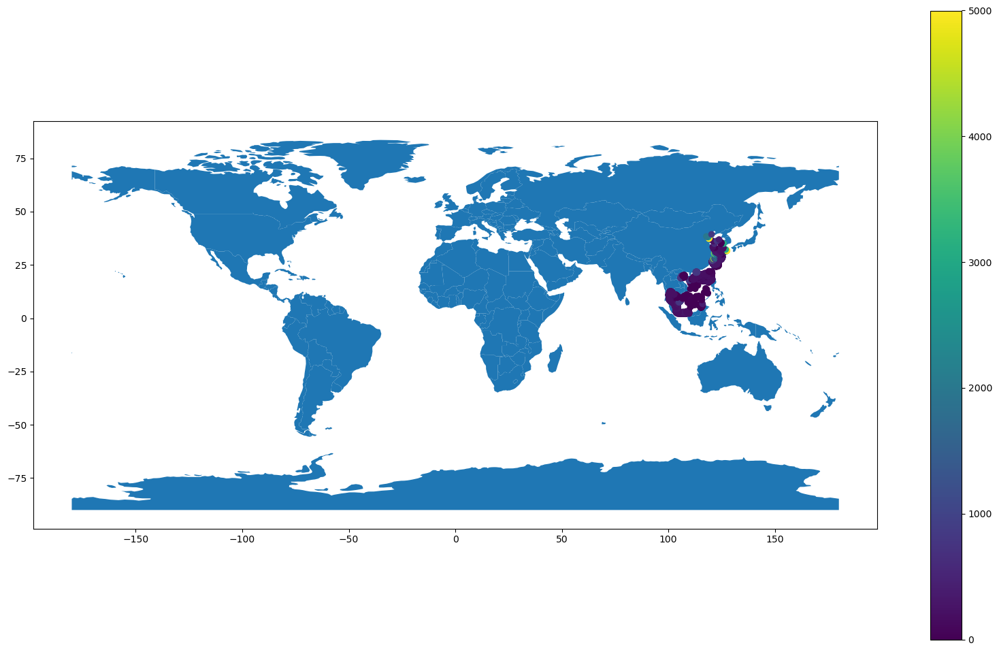

In [209]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_17['Longitude'], df_17['Latitude'])]
gdf_17 = GeoDataFrame(df_17, geometry=geometry)  
gdf_17.plot(ax = world.plot(figsize = (20, 12)), column = df_17["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_17['Longitude'], df_17['Latitude'])]
gdf_17 = GeoDataFrame(df_17, geometry=geometry)  
gdf_17.plot(ax = world.plot(figsize = (20, 12)), column = df_17["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 5000,legend = True);#"Sedimentation rate [cm/ka]"

df_17.describe()

/tmp/ipykernel_3264220/2375122941.py:19: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


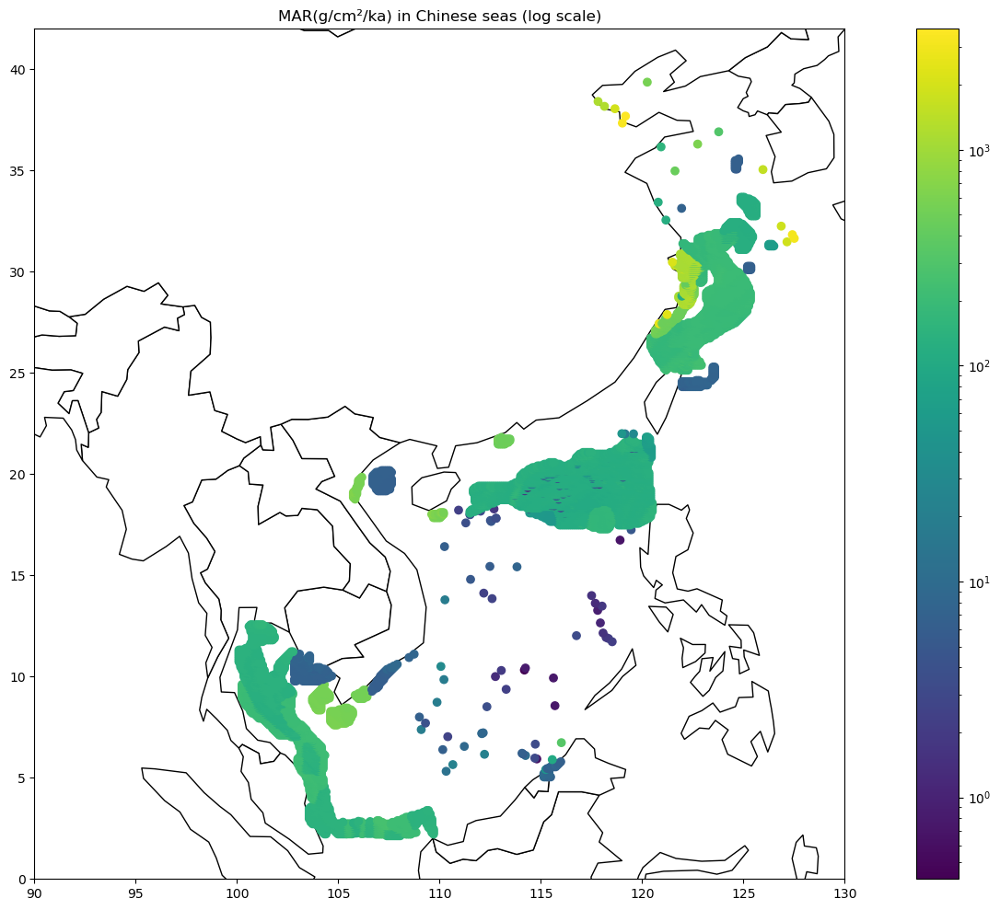

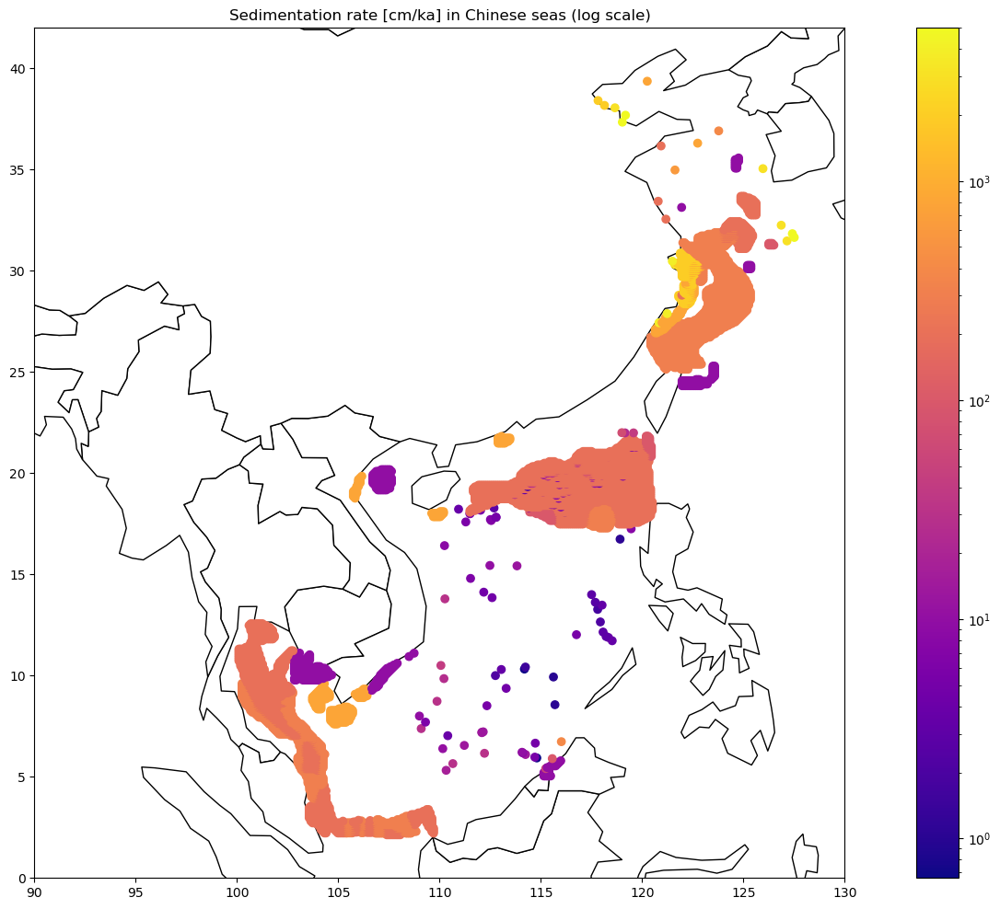

,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
count,9081.000000,9081.000000,9081.000000,9081.000000
mean,18.422162,114.567509,297.742356,186.499921
std,8.662922,8.152244,343.366984,205.876902
min,2.134835,100.091865,0.660000,0.418600
25%,10.142552,105.534214,200.000000,119.600000
50%,19.238065,117.078739,200.000000,135.200000
75%,26.302345,121.838274,300.000000,195.000000
max,39.363032,127.505308,5000.000000,3640.000000


In [210]:
# Plot only data for Chinese seas in log scale

# Define Chinese seas bounding box (approximate extent)
# South China Sea, East China Sea, Yellow Sea, Bohai Sea
lon_min, lon_max = 90, 130   # degrees East
lat_min, lat_max = 0, 42     # degrees North

# Filter the DataFrame for Chinese seas
df_17_cn = df_17[
    (df_17["Longitude"] >= lon_min) & (df_17["Longitude"] <= lon_max) &
    (df_17["Latitude"] >= lat_min) & (df_17["Latitude"] <= lat_max)
].copy()

# Prepare geometry and GeoDataFrame for plotting
geometry = [Point(xy) for xy in zip(df_17_cn['Longitude'], df_17_cn['Latitude'])]
gdf_17_cn = GeoDataFrame(df_17_cn, geometry=geometry)

# Read the world map and clip to the Chinese seas bounding box for clarity
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
bbox = world.cx[lon_min:lon_max, lat_min:lat_max]

# Plot MAR(g/cm**2/ka) in log scale
ax = bbox.plot(figsize=(20, 12), color="white", edgecolor="black")
gdf_17_cn.plot(
    ax=ax, 
    column="MAR(g/cm**2/ka)", 
    legend=True, 
    cmap='viridis', 
    norm=plt.matplotlib.colors.LogNorm(vmin=gdf_17_cn["MAR(g/cm**2/ka)"].replace(0, np.nan).min()+1e-6, vmax=gdf_17_cn["MAR(g/cm**2/ka)"].max()) # avoid 0 for log
)
plt.title("MAR(g/cm²/ka) in Chinese seas (log scale)")
plt.xlim(lon_min, lon_max)
plt.ylim(lat_min, lat_max)
plt.show()

# Plot Sedimentation rate [cm/ka] in log scale
ax = bbox.plot(figsize=(20, 12), color="white", edgecolor="black")
gdf_17_cn.plot(
    ax=ax, 
    column="Sedimentation rate [cm/ka]", 
    legend=True, 
    cmap='plasma', 
    norm=plt.matplotlib.colors.LogNorm(vmin=gdf_17_cn["Sedimentation rate [cm/ka]"].replace(0, np.nan).min()+1e-6, vmax=gdf_17_cn["Sedimentation rate [cm/ka]"].max()) # avoid 0 for log
)
plt.title("Sedimentation rate [cm/ka] in Chinese seas (log scale)")
plt.xlim(lon_min, lon_max)
plt.ylim(lat_min, lat_max)
plt.show()

df_17_cn.describe()

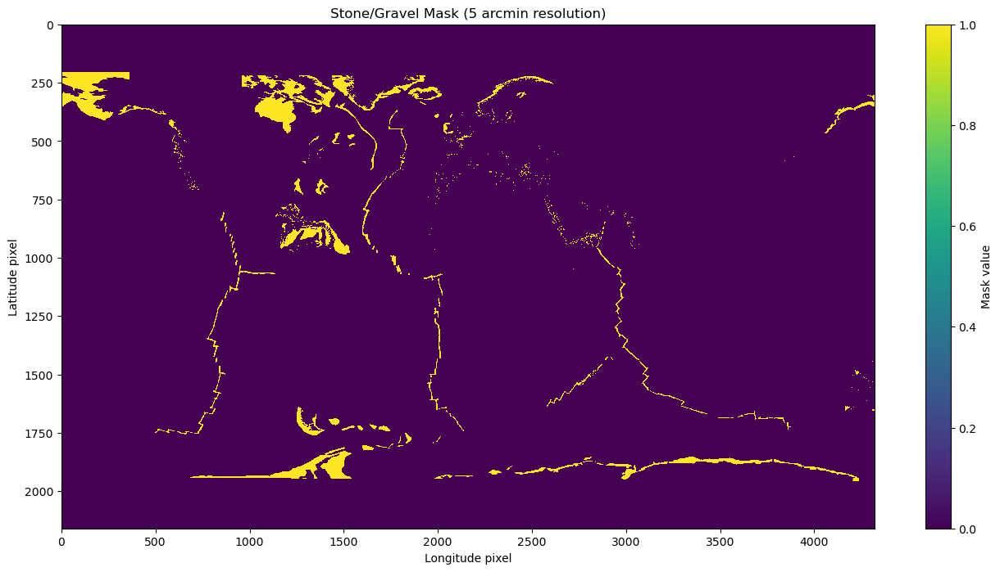

Number of grid points where mask == 1: 235673
    Latitude   Longitude  MAR(g/cm**2/ka)  Sedimentation rate [cm/ka]
0  72.958333 -179.958333          0.00001                     0.00001
1  72.958333 -171.625000          0.00001                     0.00001
2  72.958333 -163.291667          0.00001                     0.00001
3  72.958333 -154.958333          0.00001                     0.00001
4  72.875000 -176.625000          0.00001                     0.00001


In [211]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Load the array (2160, 4320)
mask = np.load(str(Path().resolve().parents[2] / "nn4sedratetoc" / "data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/stone_gravel_mask_5arcmin.npy"))

plt.figure(figsize=(16, 8))
plt.imshow(mask, origin="upper", cmap="viridis", interpolation="none", aspect="auto")
plt.title("Stone/Gravel Mask (5 arcmin resolution)")
plt.xlabel("Longitude pixel")
plt.ylabel("Latitude pixel")
plt.colorbar(label="Mask value")
plt.show()

# Get number of grid points where value==1
num_mask_ones = np.sum(mask == 1)
print(f"Number of grid points where mask == 1: {num_mask_ones}")

# Compute lat and lon for each grid cell (assuming full global grid from -90 to 90, -180 to 180)
n_lat, n_lon = mask.shape
lat_step = 180 / n_lat
lon_step = 360 / n_lon

# Center of each pixel in 5 arcmin resolution
lat_vals = np.linspace(90 - 0.5*lat_step, -90 + 0.5*lat_step, n_lat)
lon_vals = np.linspace(-180 + 0.5*lon_step, 180 - 0.5*lon_step, n_lon)

# Get where mask==1
mask_indices = np.argwhere(mask == 1)

# Downsample: Select every 100th grid point to get a low resolution sample
downsample_indices = mask_indices[::100]
latitudes = lat_vals[downsample_indices[:, 0]]
longitudes = lon_vals[downsample_indices[:, 1]]

# Hudson Bay bounding box (approximate): Lat 50–65N, Lon -95–-75E (converted for this grid convention)
hb_lat_min, hb_lat_max = 50.0, 75.0
hb_lon_min, hb_lon_max = -105.0, -65.0

# Remove points in Hudson Bay
hb_mask = ~(
    (latitudes >= hb_lat_min) & (latitudes <= hb_lat_max) &
    (longitudes >= hb_lon_min) & (longitudes <= hb_lon_max)
)
latitudes_filtered = latitudes[hb_mask]
longitudes_filtered = longitudes[hb_mask]

# Set MAR and Sedimentation rate to zero for all selected points outside Hudson Bay
mar_zero = np.full_like(latitudes_filtered, 1e-5, dtype=float)
sedrate_zero = np.full_like(latitudes_filtered, 1e-5, dtype=float)

# Create DataFrame
df_gravel_mask = pd.DataFrame({
    "Latitude": latitudes_filtered,
    "Longitude": longitudes_filtered,
    "MAR(g/cm**2/ka)": mar_zero,
    "Sedimentation rate [cm/ka]": sedrate_zero,
})
print(df_gravel_mask.head())
df_18 = df_gravel_mask

/tmp/ipykernel_3264220/2288802773.py:1: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_3264220/2288802773.py:5: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


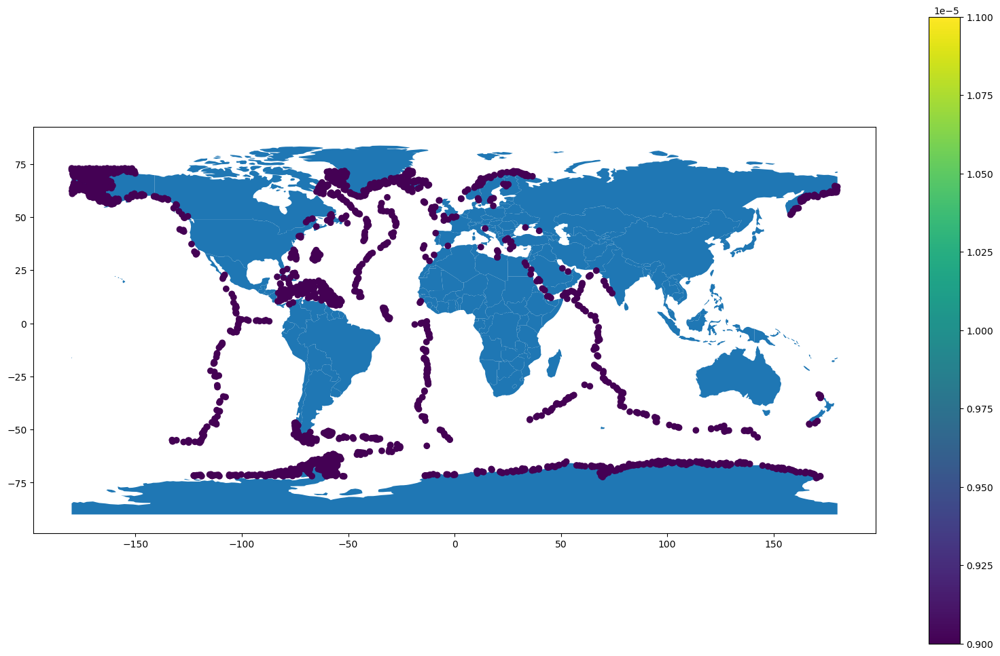

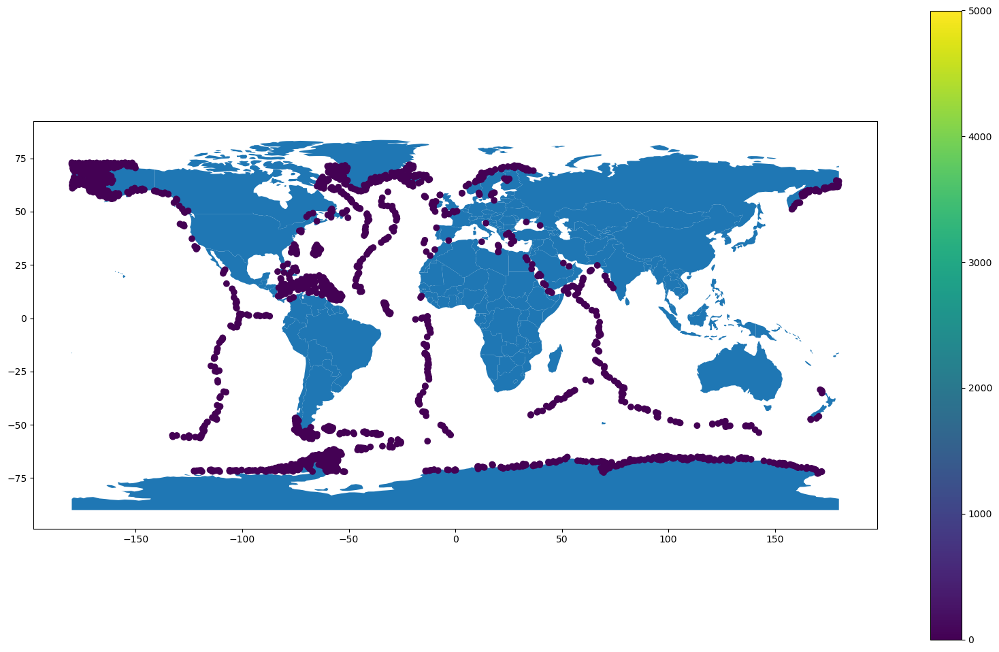

In [212]:
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_18['Longitude'], df_18['Latitude'])]
gdf_18 = GeoDataFrame(df_18, geometry=geometry)  
gdf_18.plot(ax = world.plot(figsize = (20, 12)), column = df_18["MAR(g/cm**2/ka)"],legend = True);#"Sedimentation rate [cm/ka]"
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df_18['Longitude'], df_18['Latitude'])]
gdf_18 = GeoDataFrame(df_18, geometry=geometry)  
gdf_18.plot(ax = world.plot(figsize = (20, 12)), column = df_18["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 5000,legend = True);#"Sedimentation rate [cm/ka]"

In [213]:
df_18

,Latitude,Longitude,MAR(g/cm**2/ka),Sedimentation rate [cm/ka]
0,72.958333,-179.958333,0.00001,0.00001
1,72.958333,-171.625000,0.00001,0.00001
2,72.958333,-163.291667,0.00001,0.00001
3,72.958333,-154.958333,0.00001,0.00001
4,72.875000,-176.625000,0.00001,0.00001
...,...,...,...,...
1992,-72.041667,171.958333,0.00001,0.00001
1993,-72.208333,170.208333,0.00001,0.00001
1994,-72.375000,69.625000,0.00001,0.00001
1995,-72.625000,170.625000,0.00001,0.00001


In [214]:
df_list = [df_1, df_2, df_3, df_4, df_6, df_7, df_8, df_9, df_10, df_11, df_12, df_13, df_14, df_15, df_16, df_17, df_18]
for i in range(17):
    df_list[i]["Sedimentation rate [cm/ka]"].max()
    df_list[i]["Sedimentation rate [cm/ka]"] = pd.to_numeric(df_list[i]["Sedimentation rate [cm/ka]"])
    

In [215]:
df = pd.concat([df_1, df_2, df_3, df_4, df_5, df_6, df_7, df_8, df_9, df_10, df_11, df_12, df_13, df_14, df_15, df_16, df_17, df_18])

In [216]:
df

,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,-68.133000,-126.750000,0.58000,0.36192
1,-68.117000,-130.733000,0.77000,0.50050
2,-68.067000,-106.800000,0.74000,0.46176
3,-68.050000,-159.817000,1.15000,0.74750
4,-68.050000,174.600000,0.97000,0.68094
...,...,...,...,...
1992,-72.041667,171.958333,0.00001,0.00001
1993,-72.208333,170.208333,0.00001,0.00001
1994,-72.375000,69.625000,0.00001,0.00001
1995,-72.625000,170.625000,0.00001,0.00001


In [217]:
#df_with_15 = pd.concat([df_5, df])

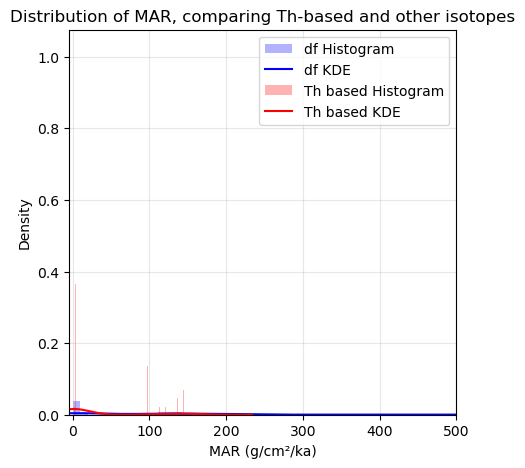

In [218]:
# Create figure
plt.figure(figsize=(5, 5))

# Plot histogram and KDE for df
df["MAR(g/cm**2/ka)"].hist(bins=500, density=True, alpha=0.3, color='blue', label='df Histogram')
df["MAR(g/cm**2/ka)"].plot.kde(color='blue', label='df KDE')

# Plot histogram and KDE for df_15
df_15["MAR(g/cm**2/ka)"].hist(bins=500, density=True, alpha=0.3, color='red', label='Th based Histogram')
df_15["MAR(g/cm**2/ka)"].plot.kde(color='red', label='Th based KDE')

plt.xlabel('MAR (g/cm²/ka)')
plt.ylabel('Density')
plt.title('Distribution of MAR, comparing Th-based and other isotopes')
plt.xlim(-5, 500)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

/tmp/ipykernel_3264220/569473364.py:11: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


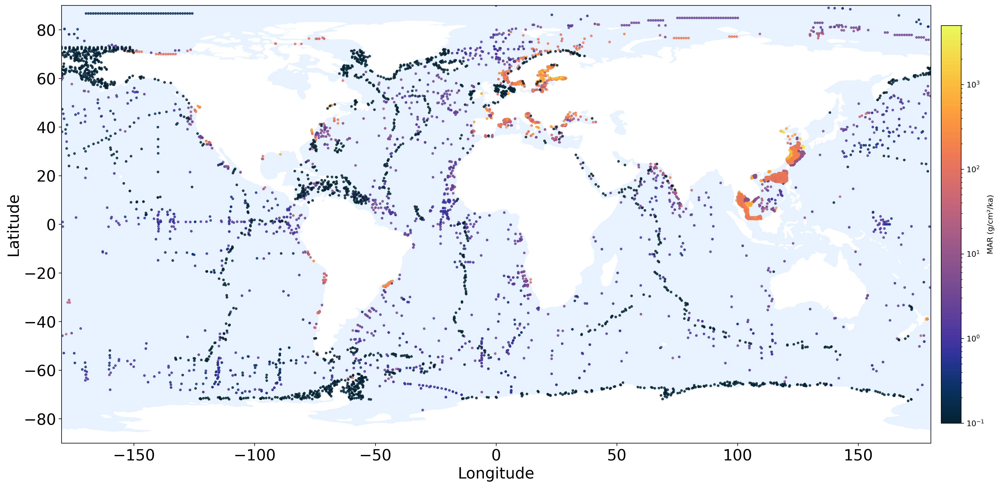

In [219]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
from geopandas import GeoDataFrame
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import cmcrameri.cm as cmc
import cmocean as cmo

# Load world boundaries
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))

# Remove duplicates
df = df.drop_duplicates()

# Create GeoDataFrame for data points
geometry = [Point(xy) for xy in zip(df['Longitude'], df['Latitude'])]
gdf = GeoDataFrame(df, geometry=geometry, crs=world.crs)

# Remove points that lie on land
# Use spatial join to find which points are within any land polygon
gdf_land = gpd.sjoin(gdf, world, how="left", predicate="within")
# Points on land will have a non-null index_right (joined to a country polygon)
gdf_sea = gdf_land[gdf_land["index_right"].isnull()].copy()

# Set up figure and axes
fig, ax = plt.subplots(figsize=(20, 10), dpi=300)

# Set a visually appealing background color (e.g., very light blue)
ax.set_facecolor('#e6f2ff')  # pastel blue

# Plot world boundaries with white fill and light gray edges for contrast
world.plot(ax=ax, alpha=1, color='white', edgecolor='white', linewidth=0.5, zorder=1)

# Plot only the points that are not on land
cax = gdf_sea.plot(
    ax=ax,
    column=gdf_sea["MAR(g/cm**2/ka)"],
    cmap=cmo.cm.thermal,
    norm=LogNorm(vmin=1e-1, vmax=5000),
    legend=True,
    markersize=10,
    marker='o',
    #edgecolor='black',
    linewidth=0.2,
    alpha=0.85,
    legend_kwds={
        "shrink": 0.75,
        "label": "MAR (g/cm²/ka)",
        "pad": 0.01
    },
    zorder=2
)

# Set font size for all elements
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.tight_layout()
plt.show()


/tmp/ipykernel_3264220/915302355.py:9: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


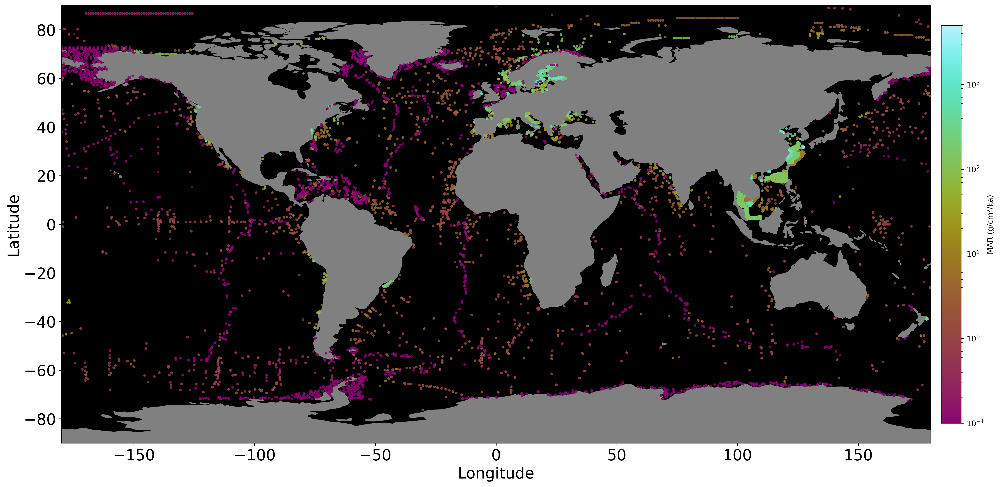

In [220]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
from geopandas import GeoDataFrame
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# Load world boundaries
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))

# Remove duplicates
df = df.drop_duplicates()

# Create GeoDataFrame for data points
geometry = [Point(xy) for xy in zip(df['Longitude'], df['Latitude'])]
gdf = GeoDataFrame(df, geometry=geometry, crs=world.crs)

# Remove points that lie on l
gdf_land = gpd.sjoin(gdf, world, how="left", predicate="within")
gdf_sea = gdf_land[gdf_land["index_right"].isnull()].copy()

# Set up figure and axes with black background
fig, ax = plt.subplots(figsize=(20, 10), dpi=300)
ax.set_facecolor('black')  # black background

# Plot world boundaries with black fill and gray edges for contrast
world.plot(ax=ax, alpha=1, color='gray', edgecolor='gray', linewidth=0.5, zorder=1)

# Plot only the points that are not on land, using cubehelix colormap
cax = gdf_sea.plot(
    ax=ax,
    column=gdf_sea["MAR(g/cm**2/ka)"],
    cmap='cmc.hawaii',
    norm=LogNorm(vmin=1e-1, vmax=5000),
    legend=True,
    markersize=10,
    marker='o',
    linewidth=0.2,
    alpha=0.85,
    legend_kwds={
        "shrink": 0.75,
        "label": "MAR (g/cm²/ka)",
        "pad": 0.01
    },
    zorder=2
)

# Set font size for all elements and white font color for axes labels/ticks
ax.set_xlabel("Longitude", fontsize=20, color='black')
ax.set_ylabel("Latitude", fontsize=20, color='black')
ax.tick_params(axis='x', colors='black', labelsize=20)
ax.tick_params(axis='y', colors='black', labelsize=20)
plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.tight_layout()

# Set legend text color to white for visibility on black background
leg = ax.get_legend()
if leg is not None:
    for text in leg.get_texts():
        text.set_color('black')
    leg.get_title().set_color('black')
    leg.get_frame().set_facecolor('black')
    leg.get_frame().set_edgecolor('gray')

plt.show()


In [221]:
"""
# Filter TOC data for Baltic Sea region
baltic_df = df[
    (df['Latitude'] >= 53) & (df['Latitude'] <= 66) &
    (df['Longitude'] >= 12) & (df['Longitude'] <= 30)
].copy()

print(f"Number of points in Baltic Sea dataset: {len(baltic_df)}")
"""

'\n# Filter TOC data for Baltic Sea region\nbaltic_df = df[\n    (df[\'Latitude\'] >= 53) & (df[\'Latitude\'] <= 66) &\n    (df[\'Longitude\'] >= 12) & (df[\'Longitude\'] <= 30)\n].copy()\n\nprint(f"Number of points in Baltic Sea dataset: {len(baltic_df)}")\n'

In [222]:
"""
# Create a GeoDataFrame for the Baltic Sea
geometry_baltic = [Point(xy) for xy in zip(baltic_df['Longitude'], baltic_df['Latitude'])]
gdf_baltic = GeoDataFrame(baltic_df, geometry=geometry_baltic)
"""

"\n# Create a GeoDataFrame for the Baltic Sea\ngeometry_baltic = [Point(xy) for xy in zip(baltic_df['Longitude'], baltic_df['Latitude'])]\ngdf_baltic = GeoDataFrame(baltic_df, geometry=geometry_baltic)\n"

In [223]:
"""
# Plotting Baltic Sea TOC
fig, ax = plt.subplots(figsize=(12, 8), dpi=300)

# Background color
ax.set_facecolor('black')

# Plot TOC points
cax = gdf_baltic.plot(
    ax=ax,
    column=baltic_df["MAR(g/cm**2/ka)"],
    cmap='cmc.hawaii',
    norm=LogNorm(vmin=1e-1, vmax=5000),
    legend=True,
    markersize=10,
    marker='o',
    linewidth=0.2,
    alpha=0.85,
    legend_kwds={
        "shrink": 0.75,
        "label": "MAR (g/cm²/ka)",
        "pad": 0.01
    }
)

# Plot world map to give context
world.plot(ax=ax, alpha=0.5, color='grey')

# Set limits to Baltic Sea region
plt.xlim(10, 30)
plt.ylim(53, 66)

# Labels and formatting
plt.xlabel("Longitude", fontsize=16)
plt.ylabel("Latitude", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.title("MAR Data in the Baltic Sea", fontsize=18)
plt.tight_layout()

plt.show()
"""

'\n# Plotting Baltic Sea TOC\nfig, ax = plt.subplots(figsize=(12, 8), dpi=300)\n\n# Background color\nax.set_facecolor(\'black\')\n\n# Plot TOC points\ncax = gdf_baltic.plot(\n    ax=ax,\n    column=baltic_df["MAR(g/cm**2/ka)"],\n    cmap=\'cmc.hawaii\',\n    norm=LogNorm(vmin=1e-1, vmax=5000),\n    legend=True,\n    markersize=10,\n    marker=\'o\',\n    linewidth=0.2,\n    alpha=0.85,\n    legend_kwds={\n        "shrink": 0.75,\n        "label": "MAR (g/cm²/ka)",\n        "pad": 0.01\n    }\n)\n\n# Plot world map to give context\nworld.plot(ax=ax, alpha=0.5, color=\'grey\')\n\n# Set limits to Baltic Sea region\nplt.xlim(10, 30)\nplt.ylim(53, 66)\n\n# Labels and formatting\nplt.xlabel("Longitude", fontsize=16)\nplt.ylabel("Latitude", fontsize=16)\nplt.xticks(fontsize=14)\nplt.yticks(fontsize=14)\nplt.title("MAR Data in the Baltic Sea", fontsize=18)\nplt.tight_layout()\n\nplt.show()\n'

In [224]:
"""import pandas as pdimport geopandas as gpdfrom shapely.geometry import Pointfrom geopandas import GeoDataFrameimport matplotlib.pyplot as pltfrom matplotlib.colors import LogNormimport cmcrameri.cm as cmc# Load the ocean GeoDataFrameocean_gdf = gpd.read_file(project_root / "data" / "interim" / "GOaS_v1_20211214" / "goas_v01.shp")# Filter for the Baltic Sea regionbaltic_sea_filtered = ocean_gdf[ocean_gdf["name"] == "Baltic Sea"]# Load the Baltic Sea shapefile#baltic_sea = gpd.read_file(str(Path().resolve().parents[2] / "nn-toc-update" / "data/Baltic sea/World_Seas_IHO_v3.shp"))#baltic_sea = baltic_sea[baltic_sea["NAME"].isin(["Baltic Sea", "Gulf of Finland", "Gulf of Bothnia", "Gulf of Riga"])]#baltic_sea_filtered = baltic_sea[baltic_sea["NAME"].isin(["Baltic Sea", "Gulf of Finland", "Gulf of Bothnia" , "Gulf of Riga"])]# Assuming 'df' is your DataFrame with Latitude, Longitude, and TOC columnsdf = baltic_df.drop_duplicates()# Create a GeoDataFrame for the pointsgeometry = [Point(xy) for xy in zip(df['Longitude'], df['Latitude'])]gdf = GeoDataFrame(df, geometry=geometry)# Ensure both GeoDataFrames are in the same coordinate reference system (CRS)gdf = gdf.set_crs("EPSG:4326")  # Coordinate reference system: WGS84baltic_sea_filtered = baltic_sea_filtered.set_crs("EPSG:4326")# Perform a spatial join to get only points inside the Baltic Sea regiongdf_baltic = gpd.sjoin(gdf, baltic_sea_filtered, how="inner", op="within")# Plottingfig, ax = plt.subplots(figsize=(20, 10), dpi=300)# Plotting the Baltic Sea region (Water)baltic_sea_filtered.plot(ax=ax, color='gray', edgecolor='lightgray', alpha=0.7)# Plotting the points inside the Baltic Sea regioncax = gdf_baltic.plot(ax=ax, column="MAR(g/cm**2/ka)",cmap='cmc.hawaii',    norm=LogNorm(vmin=1e-1, vmax=5000),                      legend=True, markersize=5, legend_kwds={    "shrink": 0.75,    "label": "MAR(g/cm**2/ka)",    "pad": 0.01})# Customize the plotax.set_title("MAR Data Points in the Baltic Sea", fontsize=20)ax.set_xlabel("Longitude", fontsize=15)ax.set_ylabel("Latitude", fontsize=15)ax.set_facecolor('black')  # Set background color to white for contrast# Adjust layoutplt.tight_layout()plt.show()"""

'\nimport pandas as pd\nimport geopandas as gpd\nfrom shapely.geometry import Point\nfrom geopandas import GeoDataFrame\nimport matplotlib.pyplot as plt\nfrom matplotlib.colors import LogNorm\nimport cmcrameri.cm as cmc\n\n# Load the ocean GeoDataFrame\nocean_gdf = gpd.read_file(Path().resolve().parents[1] / "data" / "interim" / "GOaS_v1_20211214" / "goas_v01.shp")\n\n# Filter for the Baltic Sea region\nbaltic_sea_filtered = ocean_gdf[ocean_gdf["name"] == "Baltic Sea"]\n# Load the Baltic Sea shapefile\n#baltic_sea = gpd.read_file(\'/gxfs_work/cau/sunms498/work/nn-toc-update/data/Baltic sea/World_Seas_IHO_v3.shp\')\n#baltic_sea = baltic_sea[baltic_sea["NAME"].isin(["Baltic Sea", "Gulf of Finland", "Gulf of Bothnia", "Gulf of Riga"])]\n#baltic_sea_filtered = baltic_sea[baltic_sea["NAME"].isin(["Baltic Sea", "Gulf of Finland", "Gulf of Bothnia" , "Gulf of Riga"])]\n\n# Assuming \'df\' is your DataFrame with Latitude, Longitude, and TOC columns\ndf = baltic_df.drop_duplicates()\n\n# Create

In [225]:
#df.shape

In [226]:
#max(df["Sedimentation rate [cm/ka]"])

In [227]:
#feature_image_path ="/media/nparameswaran/EXTERNAL_USB/LeeKNNsTOC(Data)/RestrepoFeatureMaps/"
restrepo_features_path = Path().resolve().parents[2] / "nn4sedratetoc" / "data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated"
#restrepo_features_path_flipped = Path("/media/nparameswaran/EXTERNAL_USB/Features_Phrampus_flipped")
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    restrepo_files.extend(filenames)

restrepo_files.sort()
len(restrepo_files)

rootgrp = xr.open_dataset(Path(restrepo_features_path / restrepo_files[0]), format = 'NETCDF4')
latitudes = rootgrp.variables['lat']
longitudes = rootgrp.variables['lon']

restrepo_features = np.empty([len(df),len(restrepo_files[0:len(restrepo_files)])])
restrepo_features[:] = np.nan
restrepo_X_mean = np.empty(0)
restrepo_X_std = np.empty(0)

file_idx = -1
corrupted_files = 0


In [228]:
def find_nearest(value,vector):
    vector = np.float64(vector)-np.float64(value);
    return np.argmin(np.abs(vector))

for file in restrepo_files[0:len(restrepo_files)]:
    if file == "GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd":
        
        try: 
            rootgrp = xr.open_dataset(Path(restrepo_features_path / file), format = 'NETCDF4')
        except:
            restrepo_X_mean = np.append(restrepo_X_mean,np.nan)
            restrepo_X_std = np.append(restrepo_X_std,np.nan)
            corrupted_files = corrupted_files + 1
            continue
    
        
    #     latitudes = rootgrp.variables['lats'] # in theory all the same
    #     longitudes = rootgrp.variables['lons']
        
        dataset = rootgrp.variables['data']
    
        restrepo_X_mean = np.append(restrepo_X_mean,np.nanmean(dataset))
        restrepo_X_std = np.append(restrepo_X_std,np.nanstd(dataset))
        #plt.figure(figsize=([20,10]), dpi=300);plt.imshow(np.rot90(np.rot90(np.fliplr(dataset_numpy))))
        dataset_numpy = dataset.to_numpy()
        #dataset_numpy = np.rot90(np.rot90(np.fliplr(dataset_numpy)))
        # ds = xr.Dataset(
    
        #     data_vars=dict(
    
        #         data=(['lat', 'lon'],dataset_numpy)
    
        #     ),
    
        #     coords=dict(
    
        #         lon=( longitudes),
    
        #         lat=(latitudes)
        #     ),
        #     attrs=dict(description="feature data set for sediment accumulation prediction"),    
        # )
        # ds.to_netcdf(path = "/media/nparameswaran/EXTERNAL_USB/Features_Phrampus_flipped/"+file)
        # plt.figure(figsize=([20,10]), dpi=300)
        # plt.title(file[:-3])
        # plt.imshow(dataset)
        # plt.colorbar()
        # if file[:-3]!='.':
        #     plt.savefig( feature_image_path +file[:-4]+".png")
        # else:
        #     plt.savefig( feature_image_path +file[:-3]+".png")
        # plt.close()
        
        # latitudes_labels=[]
        # longitudes_labels=[]
        filename=file
    else:
        continue

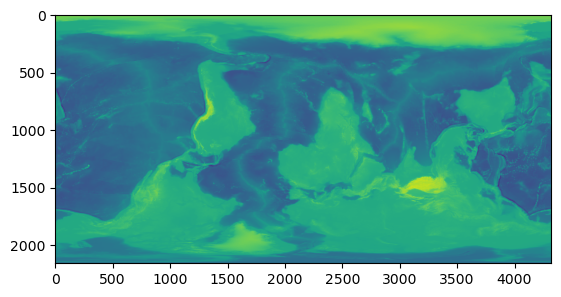

In [229]:
plt.imshow(dataset_numpy)

In [230]:
#mask1 is <-200m#mask2 is >-200ma = dataset_numpy > -200b = dataset_numpy < 0mask1 = np.where(np.logical_and(a, b), 1, np.nan) #255 and 0 are the binary values for true and falsemask2 = np.where(dataset_numpy <= -200 , 1,np.nan) #mask1 = np.rot90(np.rot90(np.fliplr(mask1)))df1 = pd.DataFrame()df2 = pd.DataFrame()lat_idx_shallow = []lon_idx_shallow = []elevation_cs = []dataset = mask1for data_idx in range(0,len(df)):    lat_idx = find_nearest(df.iloc[data_idx,0], latitudes)    lon_idx = find_nearest(df.iloc[data_idx,1], longitudes)    #plt.figure(data_idx)    #plt.imshow(mask1[-10:10,-10:10])    if mask1[lat_idx, lon_idx]==1:        elevation_cs.append(dataset_numpy[lat_idx, lon_idx])        #plt.imshow(mask1[-10:10,-10:10])        if df1.empty:            df1 = df.iloc[data_idx]        else:            df1 = pd.concat([df1, df.iloc[data_idx]], axis=1, ignore_index=True)    if mask2[lat_idx, lon_idx]==1:        if df2.empty:            df2 = df.iloc[data_idx]        else:            df2 = pd.concat([df2, df.iloc[data_idx]], axis=1, ignore_index=True)    if data_idx%1000 == 0:        print(data_idx)    # latitudes_labels.append(latitudes[lat_idx])    # longitudes_labels.append(longitudes[lon_idx])df1 = df1.transpose()df2 = df2.transpose()#df1 = df1[df1.iloc[:,2] < 5000 ]#df2 = df2[df2.iloc[:,2] < 1000 ]np.save(str(project_root / "data" / "interim" / "masks"),mask2)df1 = df1[df1["Longitude"]>-179.5]df1 = df1[df1["Longitude"]<179.5]df1 = df1[df1["Latitude"]>-89.5]df1 = df1[df1["Latitude"]<89.5]df2 = df2[df2["Longitude"]>-179.5]df2 = df2[df2["Longitude"]<179.5]df2 = df2[df2["Latitude"]>-89.5]df2 = df2[df2["Latitude"]<89.5]df1.to_csv(str(Path().resolve().parents[2] / "nn4sedratetoc" / "data/raw/labels/sedrate_continentalshelves.csv")) df2.to_csv(str(Path().resolve().parents[2] / "nn4sedratetoc" / "data/raw/labels/sedrate_deep.csv"))#df1 = df1[df1["Sedimentation rate [cm/ka]"]<1]# Load world mapworld = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))# # Create GeoDataFrame 1# geometry1 = [Point(xy) for xy in zip(df1['Longitude'], df1['Latitude'])]# gdf1 = GeoDataFrame(df1, geometry=geometry1)# # Create GeoDataFrame 2# geometry2 = [Point(xy) for xy in zip(df2['Longitude'], df2['Latitude'])]# gdf2 = GeoDataFrame(df2, geometry=geometry2)# # Plot GeoDataFrame 1 on world map# ax = world.plot(figsize = (20, 12))# gdf1.plot(ax=ax, column='Sedimentation rate [cm/ka]',  color='blue', legend = "Sedimentation rates in locations with elevation>-200m")# # Plot GeoDataFrame 2 on the same world map# gdf2.plot(ax=ax, column='Sedimentation rate [cm/ka]',  color='red', legend = "Sedimentation rates in locations with elevation<-200m")# Show legend# ax.legend()# Show the plot"""plt.figure(figsize = ([20,10]))#, dpi = 200)#plt.title("Continental shelves(elevation of 0  to -200 $m$)")plt.imshow(np.rot90(np.rot90(np.fliplr(mask1))))# plt.show()plt.figure(figsize = ([20,10]))#, dpi = 200)#plt.title("Continental shelves(elevation of 0  to -200 $m$)")# Create a custom colormap for True and False valuescmap = plt.cm.get_cmap('viridis', 2)  # Use 'viridis' colormap with 2 colors (for True and False)# Plot the mask2 arrayplt.imshow(np.rot90(np.rot90(np.fliplr(mask2))), cmap=cmap)# Set the ticks and labels for the colorbarcbar = plt.colorbar(ticks=[0.25, 0.75])cbar.ax.set_yticklabels(['False', 'True'])  # Replace the default ticks (0 and 1) with 'False' and 'True'# Set the colorbar labelcbar.set_label('Mask Value', rotation=270, labelpad=20)# Show the plotplt.show()"""

0
1000
2000
3000
4000
5000
6000
7000
8000
9000
10000
11000
12000
13000
14000
15000
16000
17000
18000
19000


/tmp/ipykernel_3264220/1266755604.py:65: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


'\nplt.figure(figsize = ([20,10]))#, dpi = 200)\n#plt.title("Continental shelves(elevation of 0  to -200 $m$)")\n\nplt.imshow(np.rot90(np.rot90(np.fliplr(mask1))))\n# plt.show()\n\nplt.figure(figsize = ([20,10]))#, dpi = 200)\n#plt.title("Continental shelves(elevation of 0  to -200 $m$)")\n\n# Create a custom colormap for True and False values\ncmap = plt.cm.get_cmap(\'viridis\', 2)  # Use \'viridis\' colormap with 2 colors (for True and False)\n\n# Plot the mask2 array\nplt.imshow(np.rot90(np.rot90(np.fliplr(mask2))), cmap=cmap)\n\n# Set the ticks and labels for the colorbar\ncbar = plt.colorbar(ticks=[0.25, 0.75])\ncbar.ax.set_yticklabels([\'False\', \'True\'])  # Replace the default ticks (0 and 1) with \'False\' and \'True\'\n\n# Set the colorbar label\ncbar.set_label(\'Mask Value\', rotation=270, labelpad=20)\n\n# Show the plot\nplt.show()\n'

In [231]:
# Load the CSV files and combine into a single DataFrame
df1 = pd.read_csv(str(Path().resolve().parents[2] / "nn4sedratetoc" / "data/raw/labels/sedrate_continentalshelves.csv"))
df2 = pd.read_csv(str(Path().resolve().parents[2] / "nn4sedratetoc" / "data/raw/labels/sedrate_deep.csv"))
df = pd.concat([df1, df2], ignore_index=True)


In [232]:
df

,Unnamed: 0,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,0,-38.985700,178.167700,0.00000,0.00000
1,1,-38.982300,178.179000,2620.00000,2316.08000
2,2,-38.982100,178.179600,1690.00000,1493.96000
3,3,-38.982000,178.179500,0.00000,0.00000
4,4,-38.976300,178.167900,2540.00000,2245.36000
...,...,...,...,...,...
18745,7912,-71.958333,171.875000,0.00001,0.00001
18746,7913,-72.041667,-51.875000,0.00001,0.00001
18747,7914,-72.041667,171.958333,0.00001,0.00001
18748,7915,-72.208333,170.208333,0.00001,0.00001


In [233]:
df1["Sedimentation rate [cm/ka]"] = pd.to_numeric(df1["Sedimentation rate [cm/ka]"])
df2["Sedimentation rate [cm/ka]"] = pd.to_numeric(df2["Sedimentation rate [cm/ka]"])

/tmp/ipykernel_3264220/46402595.py:12: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


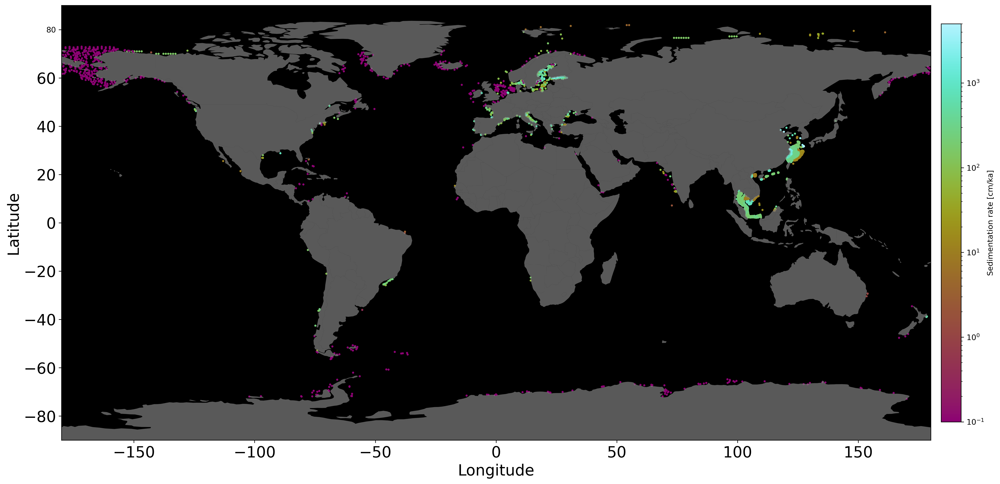

In [234]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
from geopandas import GeoDataFrame
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import cmcrameri.cm as cmc
import cmocean as cmo

# Assuming 'world' is a GeoDataFrame of the world boundaries
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))

# Assuming 'df1' is your DataFrame with Latitude, Longitude, and TOC columns
df1 = df1.drop_duplicates()

# Create a GeoDataFrame
geometry = [Point(xy) for xy in zip(df1['Longitude'], df1['Latitude'])]
gdf = GeoDataFrame(df1, geometry=geometry)

# Plotting
fig, ax = plt.subplots(figsize=(20, 10), dpi=300)

# Plotting the world map with a light blue background
ax.set_facecolor('black')  # Light blue color

# Plotting the GeoDataFrame with log-scale color map and smaller points
#gdf.plot(ax=ax, column=df1["Sedimentation rate [cm/ka]"], cmap='cubehelix', norm=LogNorm(vmin=1e-1, vmax = 15), legend=True, markersize=3, legend_kwds={
#        "shrink":.75, "label": "Sedimentation rate [cm/ka]", "pad" : 0.05})
cax = gdf.plot(ax=ax, column=df1["Sedimentation rate [cm/ka]"], cmap=cmc.hawaii, norm=LogNorm(vmin=1e-1, vmax=5000), legend=True, markersize=3
               , legend_kwds={
    "shrink": 0.75,
    "label": "Sedimentation rate [cm/ka]",
    "pad": 0.01# Title of the color bar
})


world.plot(ax=ax, alpha=0.7, color='grey')


# Set font size for all elements
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
#plt.title("TOC data points", fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
#plt.legend(fontsize=20)
plt.xlim(-180, 180)
plt.ylim(-90, 90)
#plt.title("TOC data points")
plt.tight_layout()
plt.show()



In [235]:
df2["Sedimentation rate [cm/ka]"]

0       0.58000
1       0.77000
2       0.74000
3       1.15000
4       0.97000
         ...   
7904    0.00001
7905    0.00001
7906    0.00001
7907    0.00001
7908    0.00001
Name: Sedimentation rate [cm/ka], Length: 7909, dtype: float64

In [236]:
df1

,Unnamed: 0,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka)
0,0,-38.985700,178.167700,0.00000,0.00000
1,1,-38.982300,178.179000,2620.00000,2316.08000
2,2,-38.982100,178.179600,1690.00000,1493.96000
3,3,-38.982000,178.179500,0.00000,0.00000
4,4,-38.976300,178.167900,2540.00000,2245.36000
...,...,...,...,...,...
10836,10847,-71.875000,-76.125000,0.00001,0.00001
10837,10848,-71.875000,68.958333,0.00001,0.00001
10838,10849,-71.958333,-102.208333,0.00001,0.00001
10839,10850,-71.958333,-80.541667,0.00001,0.00001


/tmp/ipykernel_3264220/918085823.py:12: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


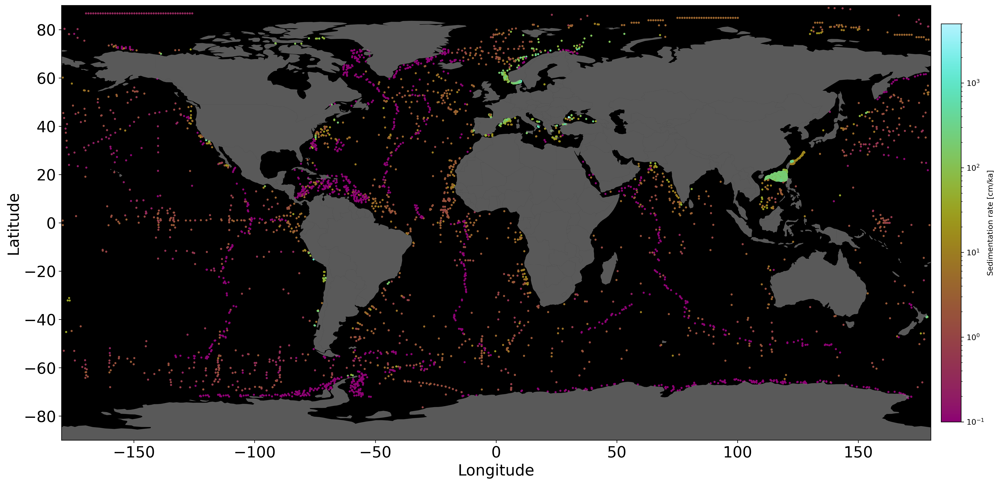

In [237]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
from geopandas import GeoDataFrame
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import cmcrameri.cm as cmc
import cmocean as cmo

# Assuming 'world' is a GeoDataFrame of the world boundaries
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))

# Assuming 'df1' is your DataFrame with Latitude, Longitude, and TOC columns
df1 = df1.drop_duplicates()

# Create a GeoDataFrame
geometry = [Point(xy) for xy in zip(df2['Longitude'], df2['Latitude'])]
gdf = GeoDataFrame(df2, geometry=geometry)

# Plottingdf1
fig, ax = plt.subplots(figsize=(20, 10), dpi=300)

# Plotting the world map with a light blue background
ax.set_facecolor('black')  # Light blue color

# Plotting the GeoDataFrame with log-scale color map and smaller points
#gdf.plot(ax=ax, column=df1["Sedimentation rate [cm/ka]"], cmap='cubehelix', norm=LogNorm(vmin=1e-1, vmax = 15), legend=True, markersize=3, legend_kwds={
#        "shrink":.75, "label": "Sedimentation rate [cm/ka]", "pad" : 0.05})
cax = gdf.plot(ax=ax, column=df2["Sedimentation rate [cm/ka]"], cmap=cmc.hawaii, norm=LogNorm(vmin=1e-1, vmax=5000), legend=True, markersize=3
               , legend_kwds={
    "shrink": 0.75,
    "label": "Sedimentation rate [cm/ka]",
    "pad": 0.01# Title of the color bar
})


world.plot(ax=ax, alpha=0.7, color='grey')


# Set font size for all elements
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
#plt.title("TOC data points", fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
#plt.legend(fontsize=20)
plt.xlim(-180, 180)
plt.ylim(-90, 90)
#plt.title("TOC data points")
plt.tight_layout()
plt.show()



In [238]:
df2["Latitude"].max()

89.0

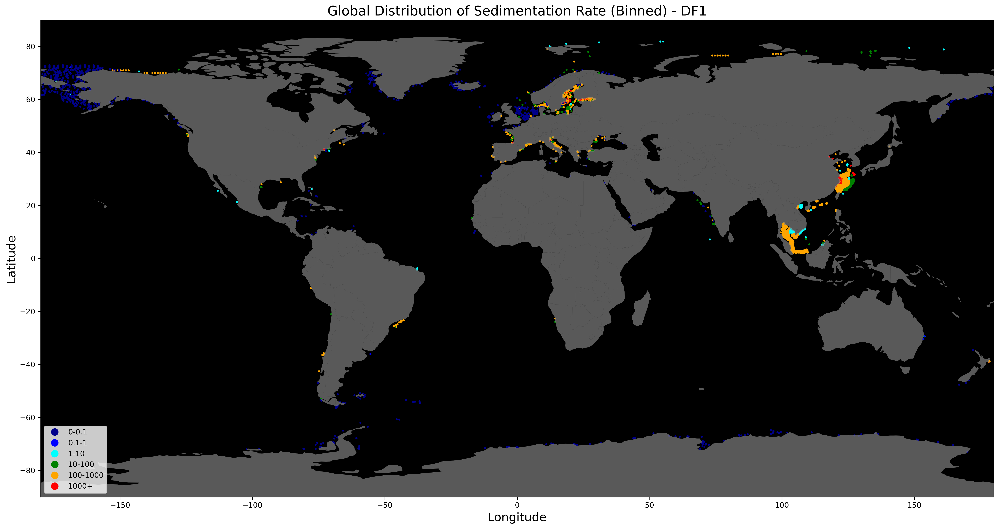

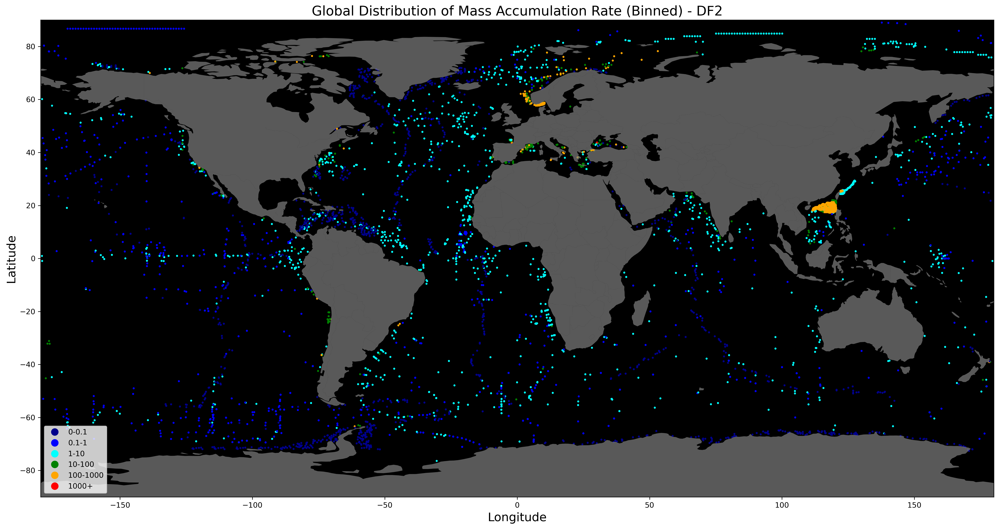

In [239]:
# Only plot the global distributions (world maps) for df1 (sedimentation rate) and df2 (mass accumulation rate), binned and colored

# Remove NaN and inf values for plotting
df1_clean = df1.dropna(subset=['Sedimentation rate [cm/ka]'])
df1_clean = df1_clean[np.isfinite(df1_clean['Sedimentation rate [cm/ka]'])]

df2_clean = df2.dropna(subset=['MAR(g/cm**2/ka)'])
df2_clean = df2_clean[np.isfinite(df2_clean['MAR(g/cm**2/ka)'])]

# Define bins and colors
bins_sr = [0, 0.1, 1, 10, 100, 1000, 10000]
labels_sr = ['0-0.1', '0.1-1', '1-10', '10-100', '100-1000', '1000+']
colors = ['darkblue', 'blue', 'cyan', 'green', 'orange', 'red']
from matplotlib.colors import ListedColormap
cmap = ListedColormap(colors)

# Bin the sedimentation rate for df1
df1_clean['sr_bin'] = pd.cut(df1_clean['Sedimentation rate [cm/ka]'], bins=bins_sr, labels=labels_sr, include_lowest=True)
# Bin the MAR for df2
df2_clean['mar_bin'] = pd.cut(df2_clean['MAR(g/cm**2/ka)'], bins=bins_sr, labels=labels_sr, include_lowest=True)

# Plot 1: Global map for df1 (sedimentation rate, binned)
fig, ax = plt.subplots(figsize=(20, 10), dpi=300)
ax.set_facecolor('black')
geometry1 = [Point(xy) for xy in zip(df1_clean['Longitude'], df1_clean['Latitude'])]
gdf1 = GeoDataFrame(df1_clean, geometry=geometry1)
gdf1.plot(ax=ax, column='sr_bin', cmap=cmap, markersize=3, legend=True)
world.plot(ax=ax, alpha=0.7, color='grey')
ax.set_title('Global Distribution of Sedimentation Rate (Binned) - DF1', fontsize=18)
ax.set_xlabel('Longitude', fontsize=16)
ax.set_ylabel('Latitude', fontsize=16)
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
plt.tight_layout()
plt.show()

# Plot 2: Global map for df2 (mass accumulation rate, binned)
fig, ax = plt.subplots(figsize=(20, 10), dpi=300)
ax.set_facecolor('black')
geometry2 = [Point(xy) for xy in zip(df2_clean['Longitude'], df2_clean['Latitude'])]
gdf2 = GeoDataFrame(df2_clean, geometry=geometry2)
gdf2.plot(ax=ax, column='mar_bin', cmap=cmap, markersize=3, legend=True)
world.plot(ax=ax, alpha=0.7, color='grey')
ax.set_title('Global Distribution of Mass Accumulation Rate (Binned) - DF2', fontsize=18)
ax.set_xlabel('Longitude', fontsize=16)
ax.set_ylabel('Latitude', fontsize=16)
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
plt.tight_layout()
plt.show()

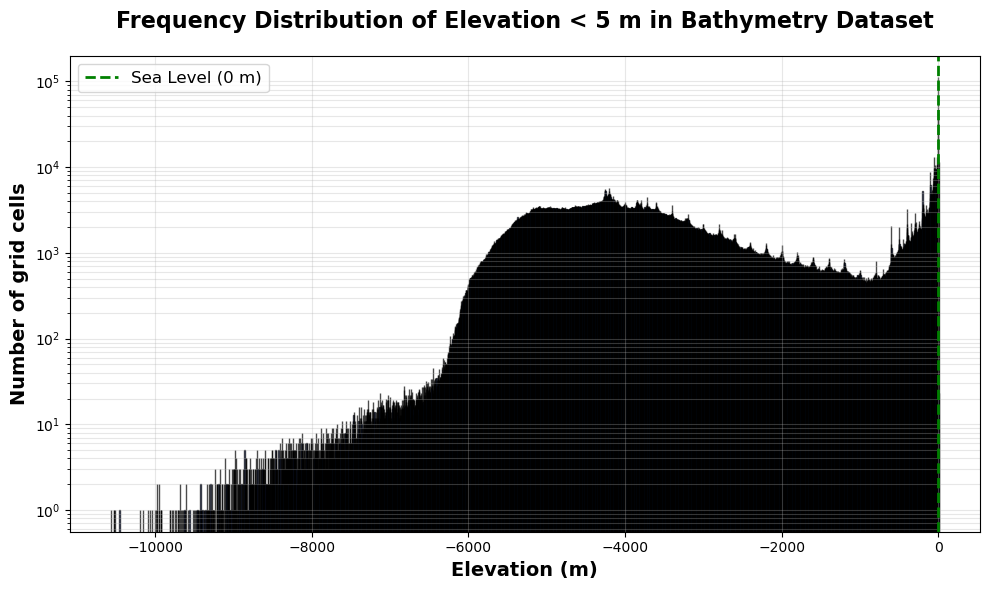

=== ELEVATION (<5m) DISTRIBUTION STATISTICS ===
Total valid grid cells: 6,295,671
Elevation range: -10563.00 m to 4.00 m
Median elevation: -3809.00 m
Mean elevation: -3318.40 m
Standard deviation: 1759.91 m
25th percentile: -4651.00 m
75th percentile: -2283.00 m


In [240]:
import matplotlib.pyplot as plt
import numpy as np

# Flatten the dataset_numpy to 1D array of elevations
elevations = dataset_numpy.flatten()

# Remove NaN and inf values
elevations = elevations[np.isfinite(elevations)]

# Filter to only elevations less than 5 meters
elevations_sub5 = elevations[elevations < 5]

# Define fine bins for this narrow range
bins = np.arange(elevations_sub5.min(), 5.1, 0.5)

# Plot histogram (frequency plot) for elevations < 5m with log scale on y-axis
plt.figure(figsize=(10, 6))
plt.hist(elevations_sub5, bins=bins, color='royalblue', edgecolor='black', alpha=0.7)
plt.xlabel('Elevation (m)', fontsize=14, fontweight='bold')
plt.ylabel('Number of grid cells', fontsize=14, fontweight='bold')
plt.title('Frequency Distribution of Elevation < 5 m in Bathymetry Dataset', fontsize=16, fontweight='bold', pad=20)
plt.yscale('log')  # Set y-axis to log scale

# Add reference lines for important bathymetric boundaries in this range
plt.axvline(x=0, color='green', linestyle='--', linewidth=2, label='Sea Level (0 m)')

plt.legend(frameon=True, fontsize=12)
plt.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()

# Print some statistics for elevations < 5m
print("=== ELEVATION (<5m) DISTRIBUTION STATISTICS ===")
print(f"Total valid grid cells: {len(elevations_sub5):,}")
print(f"Elevation range: {elevations_sub5.min():.2f} m to {elevations_sub5.max():.2f} m")
print(f"Median elevation: {np.median(elevations_sub5):.2f} m")
print(f"Mean elevation: {np.mean(elevations_sub5):.2f} m")
print(f"Standard deviation: {np.std(elevations_sub5):.2f} m")
print(f"25th percentile: {np.percentile(elevations_sub5, 25):.2f} m")
print(f"75th percentile: {np.percentile(elevations_sub5, 75):.2f} m")

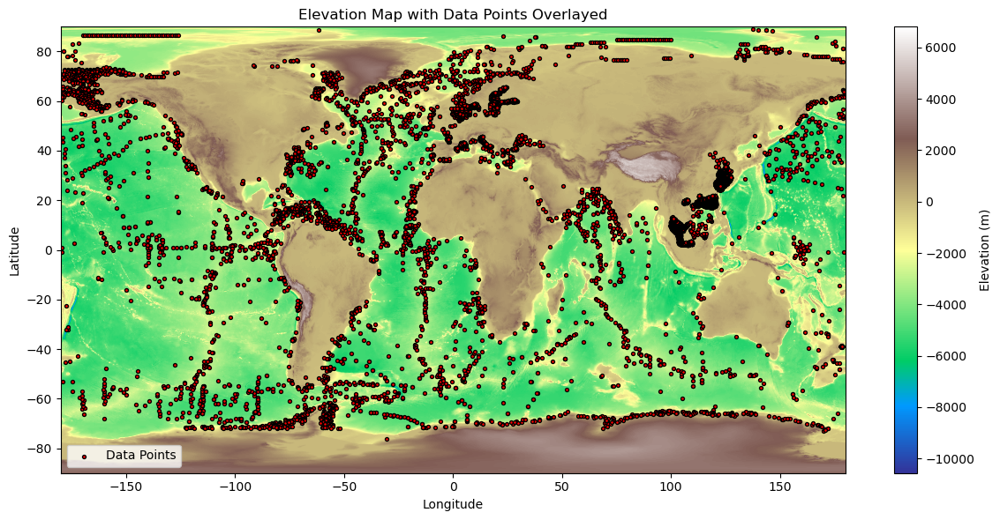

   Latitude  Longitude  elevation
0  -38.9857   178.1677      -51.0
1  -38.9823   178.1790      -51.0
2  -38.9821   178.1796      -51.0
3  -38.9820   178.1795      -51.0
4  -38.9763   178.1679      -51.0


/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


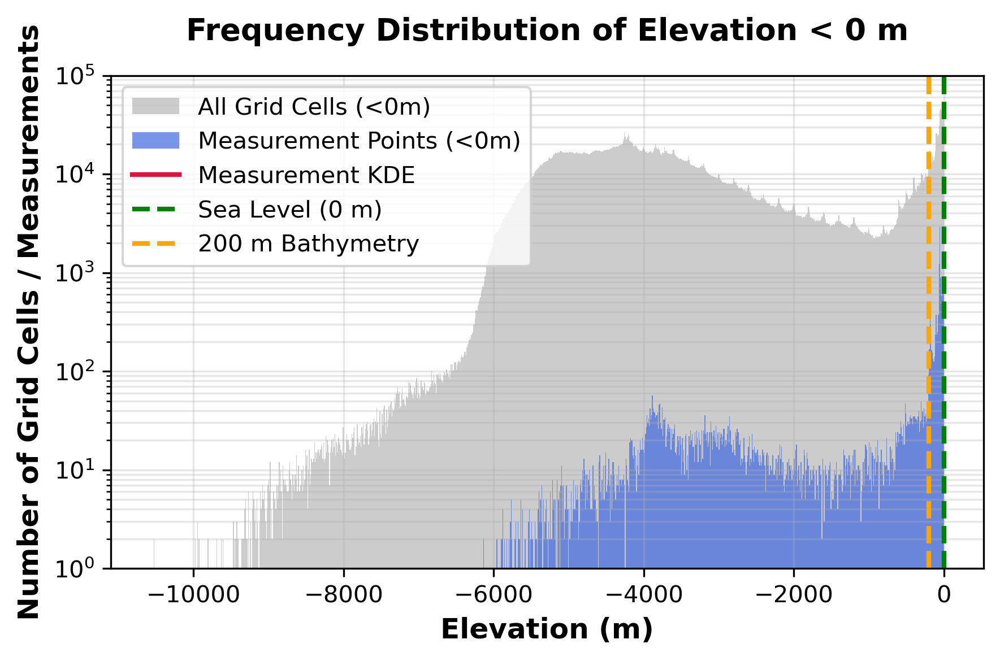

In [241]:
# Add an 'elevation' column to df by extracting elevation from dataset_numpy at each (lat, lon) point
# and plot the points on top of the elevation map

import matplotlib.pyplot as plt
import numpy as np

# Define lats and lons for the grid based on dataset_numpy shape and global coverage
nlat, nlon = dataset_numpy.shape  # Should be (2160, 4320)
lats = np.linspace(-90, 90, nlat)
lons = np.linspace(-180, 180, nlon)

def get_elevation_for_points(df, lats, lons, dataset_numpy):
    """
    For each row in df, find the closest grid cell in (lats, lons) and get the elevation from dataset_numpy.
    """
    lats = np.asarray(lats)
    lons = np.asarray(lons)
    elevations = []
    for idx, row in df.iterrows():
        lat = row['Latitude']
        lon = row['Longitude']
        # Find the nearest index in lats and lons
        lat_idx = np.abs(lats - lat).argmin()
        lon_idx = np.abs(lons - lon).argmin()
        # Get elevation
        elevation = dataset_numpy[lat_idx, lon_idx]
        elevations.append(elevation)
    return elevations

# Add the elevation column to df
df['elevation'] = get_elevation_for_points(df, lats, lons, dataset_numpy)

# Plot the elevation map and overlay the points (make points smaller)
plt.figure(figsize=(12, 6))
extent = [lons.min(), lons.max(), lats.min(), lats.max()]
plt.imshow(dataset_numpy, extent=extent, origin='lower', aspect='auto', cmap='terrain')
plt.colorbar(label='Elevation (m)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Elevation Map with Data Points Overlayed')

# Overlay the points from df with smaller size
plt.scatter(df['Longitude'], df['Latitude'], c='red', s=8, label='Data Points', edgecolor='black')
plt.legend()
plt.tight_layout()
plt.show()

# Show the first few rows of df with the new elevation column
print(df[['Latitude', 'Longitude', 'elevation']].head())

# Overlay the frequency distributions of (1) all grid cells <0m and (2) measurement points <0m
# Use thicker bins and add a KDE plot for the measurement points

import seaborn as sns

plt.figure(figsize=(6, 4), dpi=300)

# 1. All grid cells: elevations < 0m
elevations = dataset_numpy.flatten()
elevations = elevations[np.isfinite(elevations)]
elevations_sub0 = elevations[elevations < 0]

# 2. Measurement points: elevations < 0m
elevs = df['elevation'].dropna().values
elevs_sub0 = elevs[elevs < 0]

# Define thicker bins (e.g., 10 m width)
min_bin = np.floor(min(elevations_sub0.min(), elevs_sub0.min()) / 10) * 10
max_bin = 0
bins = np.arange(min_bin, max_bin + 10, 10)

# Plot all grid cells histogram (background, semi-transparent)
plt.hist(elevations_sub0, bins=bins, color='gray',  alpha=0.4, label='All Grid Cells (<0m)')

# Plot measurement points histogram (foreground)
plt.hist(elevs_sub0, bins=bins, color='royalblue', alpha=0.7, label='Measurement Points (<0m)')

# KDE plot for measurement points
if len(elevs_sub0) > 1:
    sns.kdeplot(elevs_sub0, color='crimson', linewidth=2, label='Measurement KDE', bw_adjust=1.2, clip=(min_bin, 0))

plt.xlabel('Elevation (m)', fontsize=12, fontweight='bold')
plt.ylabel('Number of Grid Cells / Measurements', fontsize=12, fontweight='bold')
plt.title('Frequency Distribution of Elevation < 0 m', fontsize=13, fontweight='bold', pad=15)
plt.yscale('log')
plt.ylim(1, 100000)
plt.axvline(x=0, color='green', linestyle='--', linewidth=2, label='Sea Level (0 m)')
plt.axvline(x=-200, color='orange', linestyle='--', linewidth=2, label='200 m Bathymetry')
plt.legend(frameon=True, fontsize=10)
plt.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()


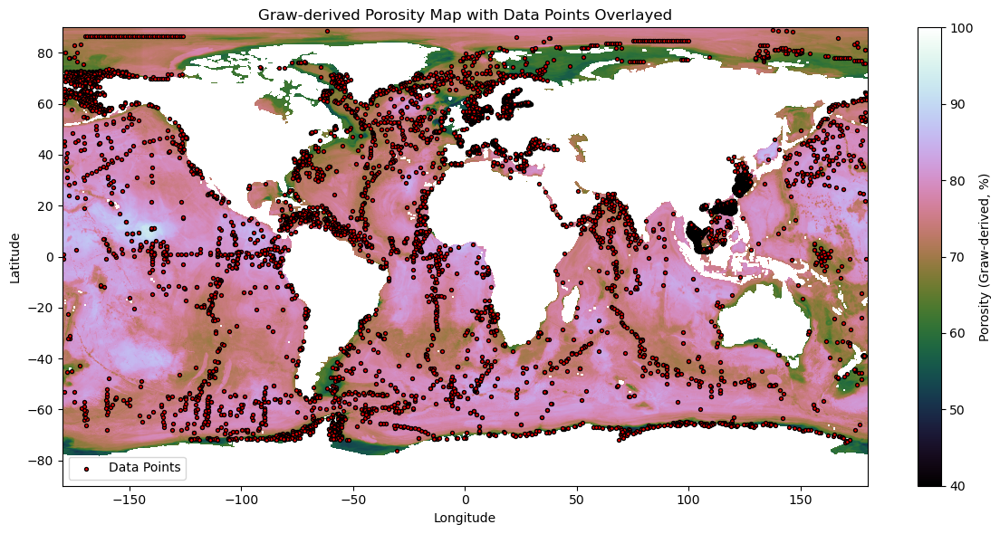

   Latitude  Longitude porosity_graw_derived
0  -38.9857   178.1677             69.607132
1  -38.9823   178.1790             69.607132
2  -38.9821   178.1796             69.607132
3  -38.9820   178.1795             69.607132
4  -38.9763   178.1679             69.607132


/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


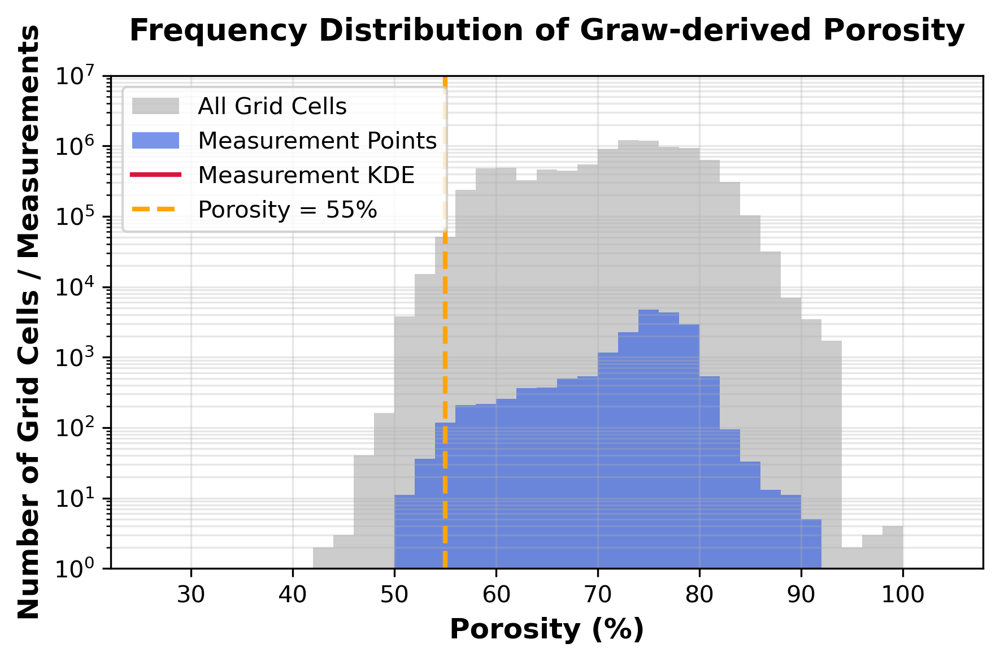

In [242]:
# Add a 'porosity_graw_derived' column to df by extracting porosity from porosity_graw at each (lat, lon) point
# and plot the points on top of the porosity map

import matplotlib.pyplot as plt
import numpy as np
porosity_graw_masked_rotated = np.rot90(np.rot90(np.fliplr(porosity_graw_masked)))
# Define lats and lons for the grid based on porosity_graw shape and global coverage
nlat, nlon = porosity_graw_masked_rotated.shape  # Should be (2160, 4320) or similar
lats = np.linspace(-90, 90, nlat)
lons = np.linspace(-180, 180, nlon)

def get_porosity_for_points(df, lats, lons, porosity_map):
    """
    For each row in df, find the closest grid cell in (lats, lons) and get the porosity from porosity_map.
    """
    lats = np.asarray(lats)
    lons = np.asarray(lons)
    porosities = []
    for idx, row in df.iterrows():
        lat = row['Latitude']
        lon = row['Longitude']
        # Find the nearest index in lats and lons
        lat_idx = np.abs(lats - lat).argmin()
        lon_idx = np.abs(lons - lon).argmin()
        # Get porosity
        porosity = porosity_map[lat_idx, lon_idx]
        porosities.append(porosity)
    return porosities

# Add the porosity_graw_derived column to df
df['porosity_graw_derived'] = get_porosity_for_points(df, lats, lons, porosity_graw_masked_rotated)

# Plot the porosity map and overlay the points (make points smaller)
plt.figure(figsize=(12, 6))
extent = [lons.min(), lons.max(), lats.min(), lats.max()]
plt.imshow(porosity_graw_masked_rotated, extent=extent, origin='lower', aspect='auto', cmap='cubehelix', vmin=40, vmax=100)
plt.colorbar(label='Porosity (Graw-derived, %)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Graw-derived Porosity Map with Data Points Overlayed')

# Overlay the points from df with smaller size
plt.scatter(df['Longitude'], df['Latitude'], c='red', s=8, label='Data Points', edgecolor='black')
plt.legend()
plt.tight_layout()
plt.show()

# Show the first few rows of df with the new porosity_graw_derived column
print(df[['Latitude', 'Longitude', 'porosity_graw_derived']].head())

# Overlay the frequency distributions of (1) all grid cells porosity and (2) measurement points porosity
# Use thicker bins and add a KDE plot for the measurement points

import seaborn as sns

plt.figure(figsize=(6, 4), dpi=300)

# 1. All grid cells: porosity (valid only)
porosity_all = porosity_graw_masked.flatten()
porosity_all = porosity_all[np.isfinite(porosity_all)]

# 2. Measurement points: porosity
porosity_pts = df['porosity_graw_derived'].dropna().values

import numpy as np

# Convert 'masked' to np.nan, and cast to float (int not possible with nan)
porosity_pts_clean = np.array([
    float(x) if x != 'masked' else np.nan
    for x in porosity_pts
])

# If you want integer values (will be float if any nan present)
# porosity_pts_int = porosity_pts_clean.astype(float)  # Already float, but for clarity

porosity_pts_clean

# Define bins (e.g., 2% width)
min_bin = np.floor(min(porosity_all.min(), porosity_pts.min()) / 2) * 2
max_bin = np.ceil(max(porosity_all.max(), porosity_pts.max()) / 2) * 2
bins = np.arange(min_bin, max_bin + 2, 2)

# Plot all grid cells histogram (background, semi-transparent)
plt.hist(porosity_all, bins=bins, color='gray',  alpha=0.4, label='All Grid Cells')

# Plot measurement points histogram (foreground)
plt.hist(porosity_pts_clean, bins=bins, color='royalblue', alpha=0.7, label='Measurement Points')

# KDE plot for measurement points
if len(porosity_pts_clean) > 1:
    sns.kdeplot(porosity_pts_clean, color='crimson', linewidth=2, label='Measurement KDE', bw_adjust=1.2, clip=(min_bin, max_bin))

plt.xlabel('Porosity (%)', fontsize=12, fontweight='bold')
plt.ylabel('Number of Grid Cells / Measurements', fontsize=12, fontweight='bold')
plt.title('Frequency Distribution of Graw-derived Porosity', fontsize=13, fontweight='bold', pad=15)
plt.yscale('log')
plt.ylim(1, 10000000)
plt.axvline(x=55, color='orange', linestyle='--', linewidth=2, label='Porosity = 55%')
plt.legend(frameon=True, fontsize=10)
plt.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()


In [243]:
df

,Unnamed: 0,Latitude,Longitude,Sedimentation rate [cm/ka],MAR(g/cm**2/ka),elevation,porosity_graw_derived
0,0,-38.985700,178.167700,0.00000,0.00000,-51.0,69.607132
1,1,-38.982300,178.179000,2620.00000,2316.08000,-51.0,69.607132
2,2,-38.982100,178.179600,1690.00000,1493.96000,-51.0,69.607132
3,3,-38.982000,178.179500,0.00000,0.00000,-51.0,69.607132
4,4,-38.976300,178.167900,2540.00000,2245.36000,-51.0,69.607132
...,...,...,...,...,...,...,...
18745,7912,-71.958333,171.875000,0.00001,0.00001,-451.0,59.559589
18746,7913,-72.041667,-51.875000,0.00001,0.00001,-1201.0,60.992455
18747,7914,-72.041667,171.958333,0.00001,0.00001,-387.0,59.136646
18748,7915,-72.208333,170.208333,0.00001,0.00001,-311.0,60.963673


In [244]:
import matplotlib.pyplot as plt

# Generate grid points
num_lat, num_lon = 2160, 4320
lat_grid = np.linspace(-90, 90, num_lat)
lon_grid = np.linspace(-180, 180, num_lon)
lon_mesh, lat_mesh = np.meshgrid(lon_grid, lat_grid)

# Flatten for scatter plot
lat_flat = lat_mesh.ravel()
lon_flat = lon_mesh.ravel()

# Remove red points on land using land_map
# land_map shape: (2160, 4320), 1=land, 0=sea

land_map = np.rot90(np.rot90(np.fliplr(land_map)))
# Flatten land_map to match lat/lon_flat
land_flat = land_map.ravel()
sea_mask = (land_flat == 0)  # True for sea, False for land
"""
plt.figure(figsize=(8, 6))

# Plot only sea grid points as small red dots
plt.scatter(lon_flat[sea_mask], lat_flat[sea_mask], color='red', s=0.01, alpha=0.5, label='2160x4320 Grid (Sea Only)')

# Overlay the df points
plt.scatter(df['Longitude'], df['Latitude'], c='royalblue', edgecolor='k', alpha=0.7, label='df points')

plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.title('Scatter plot of lat/lon from df over 2160x4320 Grid', fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.legend()
plt.show()
"""

"\nplt.figure(figsize=(8, 6))\n\n# Plot only sea grid points as small red dots\nplt.scatter(lon_flat[sea_mask], lat_flat[sea_mask], color='red', s=0.01, alpha=0.5, label='2160x4320 Grid (Sea Only)')\n\n# Overlay the df points\nplt.scatter(df['Longitude'], df['Latitude'], c='royalblue', edgecolor='k', alpha=0.7, label='df points')\n\nplt.xlabel('Longitude', fontsize=12)\nplt.ylabel('Latitude', fontsize=12)\nplt.title('Scatter plot of lat/lon from df over 2160x4320 Grid', fontsize=14)\nplt.grid(True, alpha=0.3)\nplt.tight_layout()\nplt.legend()\nplt.show()\n"

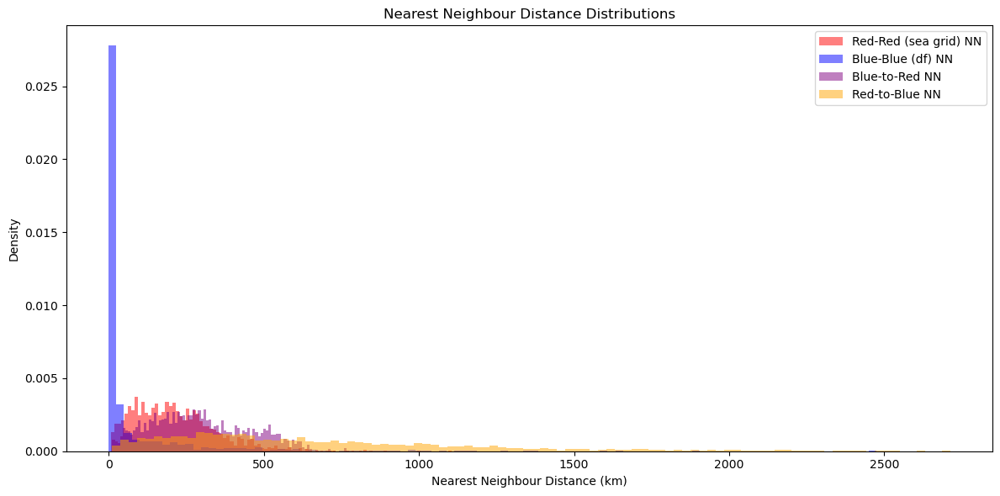

In [245]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

# --- Prepare points as before ---

# Load land mask
land_file = "../../data/raw/island_map.npy"
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1

# Generate grid points
num_lat, num_lon = 2160, 4320
lat_grid = np.linspace(-90, 90, num_lat)
lon_grid = np.linspace(-180, 180, num_lon)
lon_mesh, lat_mesh = np.meshgrid(lon_grid, lat_grid)

# Flatten for processing
lat_flat = lat_mesh.ravel()
lon_flat = lon_mesh.ravel()

# Remove red points on land using land_map
# land_map shape: (2160, 4320), 1=land, 0=sea
land_map = np.rot90(np.rot90(np.fliplr(land_map)))
land_flat = land_map.ravel()
sea_mask = (land_flat == 0)  # True for sea, False for land

# Red points: sea grid points
red_lats = lat_flat[sea_mask]
red_lons = lon_flat[sea_mask]
red_points = np.column_stack([red_lats, red_lons])

# Blue points: df points
blue_lats = df['Latitude'].values
blue_lons = df['Longitude'].values
blue_points = np.column_stack([blue_lats, blue_lons])

# Helper: haversine distance in km (vectorized for cdist)
def haversine_vec(latlon1, latlon2):
    # latlon1, latlon2: (..., 2) arrays, lat/lon in degrees
    R = 6371.0
    lat1 = np.radians(latlon1[..., 0])
    lon1 = np.radians(latlon1[..., 1])
    lat2 = np.radians(latlon2[..., 0])
    lon2 = np.radians(latlon2[..., 1])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return R * c

# --- Nearest neighbour distributions (like @file_context_0) ---

# For memory, sample a subset of red and blue points
max_red = 2000
max_blue = 2000
rng = np.random.default_rng(42)
if len(red_points) > max_red:
    red_idx = rng.choice(len(red_points), max_red, replace=False)
    red_sample = red_points[red_idx]
else:
    red_sample = red_points
if len(blue_points) > max_blue:
    blue_idx = rng.choice(len(blue_points), max_blue, replace=False)
    blue_sample = blue_points[blue_idx]
else:
    blue_sample = blue_points

# 1. Nearest neighbour blue-to-blue (excluding self)
blue_dmat = cdist(blue_sample, blue_sample, lambda u, v: haversine_vec(u, v))
np.fill_diagonal(blue_dmat, np.inf)
blue_nn = np.min(blue_dmat, axis=1)

# 2. Nearest neighbour red-to-red (excluding self)
red_dmat = cdist(red_sample, red_sample, lambda u, v: haversine_vec(u, v))
np.fill_diagonal(red_dmat, np.inf)
red_nn = np.min(red_dmat, axis=1)

# 3. Nearest neighbour blue-to-red (for each blue, min distance to any red)
blue_to_red_dmat = cdist(blue_sample, red_sample, lambda u, v: haversine_vec(u, v))
blue_to_red_nn = np.min(blue_to_red_dmat, axis=1)

# 4. Nearest neighbour red-to-blue (for each red, min distance to any blue)
red_to_blue_dmat = cdist(red_sample, blue_sample, lambda u, v: haversine_vec(u, v))
red_to_blue_nn = np.min(red_to_blue_dmat, axis=1)

# --- Plot neighbourhood distributions ---

plt.figure(figsize=(12, 6))
plt.hist(red_nn, bins=100, alpha=0.5, label='Red-Red (sea grid) NN', density=True, color='red')
plt.hist(blue_nn, bins=100, alpha=0.5, label='Blue-Blue (df) NN', density=True, color='blue')
plt.hist(blue_to_red_nn, bins=100, alpha=0.5, label='Blue-to-Red NN', density=True, color='purple')
plt.hist(red_to_blue_nn, bins=100, alpha=0.5, label='Red-to-Blue NN', density=True, color='orange')
plt.xlabel('Nearest Neighbour Distance (km)')
plt.ylabel('Density')
plt.title('Nearest Neighbour Distance Distributions')
plt.legend()
plt.tight_layout()
plt.show()


0.0010000000081096224 2473.9707106556893


/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


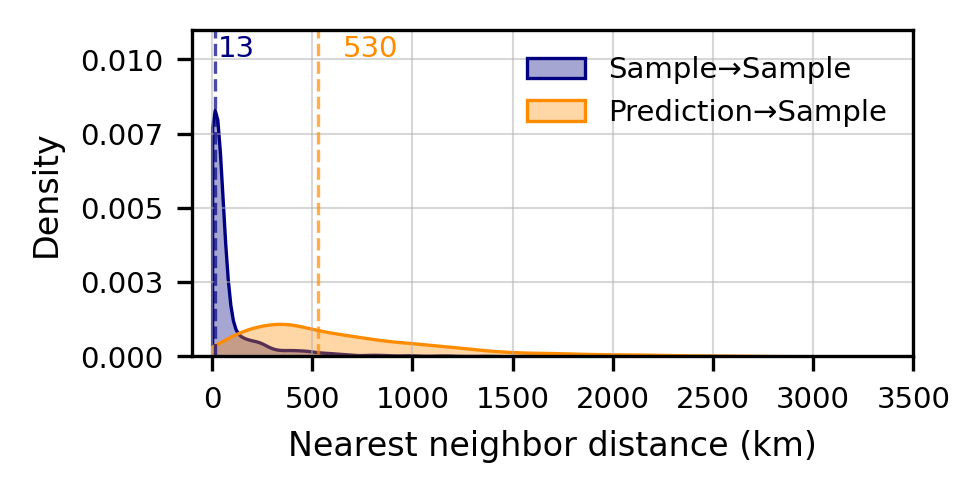

In [246]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# --- Remove negative values for KDE plotting (cut at 0) ---
blue_nn_pos = blue_nn[blue_nn >= 0] + 1e-3  # add small constant as before
red_to_blue_nn_pos = red_to_blue_nn[red_to_blue_nn >= 0] + 1e-3

# --- Figure & style ---
plt.style.use('default')  # Use matplotlib's default style
fig, ax = plt.subplots(figsize=(3, 1.5), dpi=300)
print(np.min(blue_nn_pos), np.max(blue_nn_pos))
# --- KDEs ---
sns.kdeplot(
    blue_nn_pos, label='Sample→Sample', color='navy',
    fill=True, lw=0.8, alpha=0.35, ax=ax, bw_adjust=0.9, common_norm=False, clip=(0, None)
)
sns.kdeplot(
    red_to_blue_nn_pos, label='Prediction→Sample', color='darkorange',
    fill=True, lw=0.8, alpha=0.35, ax=ax, bw_adjust=0.9, common_norm=False, clip=(0, None)
)

# --- Medians ---
m_blue = np.median(blue_nn)
m_rb   = np.median(red_to_blue_nn)
ax.axvline(m_blue, color='navy', ls='--', lw=0.8, alpha=0.7)
ax.axvline(m_rb,   color='darkorange', ls='--', lw=0.8, alpha=0.7)

# --- Axes formatting ---
ax.set_xlabel('Nearest neighbor distance (km)', fontsize=8)
ax.set_ylabel('Density', fontsize=8)
ax.set_xlim(left=0)  # Cut distribution at zero
ax.set_ylim(0, 0.011)
ax.set_xlim(-100,3500)
ax.tick_params(axis='both', which='major', labelsize=7)
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter('%.0f'))
ax.yaxis.set_major_locator(mtick.MaxNLocator(nbins=5))
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter('%.3f'))

# --- Annotate medians ---
ax.text(m_blue+200, ax.get_ylim()[1]*0.9, f"{m_blue:.0f}", 
        color='navy', fontsize=7, ha='right', va='bottom', rotation=0)
ax.text(m_rb+400, ax.get_ylim()[1]*0.9, f"{m_rb:.0f}", 
        color='darkorange', fontsize=7, ha='right', va='bottom', rotation=0)

# --- Legend & grid ---
ax.legend(frameon=False, fontsize=7, loc='upper right')
ax.grid(True, which='major', linestyle='-', linewidth=0.5, alpha=0.5)  # Use matplotlib style grid

plt.tight_layout(pad=0.2)
plt.show()